# Formula 1 Podium Prediction — Milestone 1

**Task.** For every driver who starts a Formula 1 race, predict whether he finishes on the podium (top 3), using only information that is known **after qualifying and before the race starts**.

**How to read this notebook**

* The notebook is split into numbered sections that follow the milestone brief (audit → cleaning → data-engineering questions → features → modeling → experiments → explainability → inference).
* Every choice we made is recorded in **`DECISIONS.md`** with an ID like **D7** (D1–D30). Wherever a decision is applied you will see:
  * a callout in the markdown: `🔶 Decision D7 — ...`
  * a comment in the code: `# DECISION D7 → see DECISIONS.md`
* Every markdown section ends with a short **"What this shows"** note so the conclusion is written next to its evidence.
* Wherever a difference between two numbers matters, it comes with a 95% interval from a bootstrap over races (D23), so you can see whether it is real or luck.
* The notebook runs top to bottom with a single **Run All**. It finds the Kaggle dataset automatically, and falls back to a local `data/` folder when run outside Kaggle.

**Contents**

1. Setup and loading the raw tables
2. Audit of the raw data (before cleaning)
3. Cleaning
4. EDA after cleaning (before vs after)
5. Data-engineering questions Q1–Q3
6. Feature engineering (leakage-safe)
7. Train / validation / test split
8. Preprocessing, preprocessing-order experiments (E1–E3), training-window check
9. Models (grid rule, logistic-regression baseline, random forest, gradient boosting, shallow neural network) and model selection
10. Feature-group ablation
11. Explainability (permutation importance, SHAP, LIME)
12. Inference function
13. Summary and limitations

## 1. Setup and loading the raw tables

We load all 14 CSV files **as plain text** (`dtype=str`, `keep_default_na=False`).
Loading everything as text means pandas does not guess types or silently turn values into NaN, so the audit below sees the files exactly as they are on disk.

🔶 **Decision D1** — the raw files are never modified. Raw data lives in `raw`, every cleaning step works on copies in `df`. We store a fingerprint (MD5 hash) of every raw file now and check at the end of Section 3 that none of them changed.

> All numbers quoted in the markdown come from the run saved with this notebook. The library versions of that run are printed below; random forest, gradient boosting and the neural network can move slightly under other versions, the cleaning, the data-engineering answers and the logistic regression cannot.

In [1]:
import os, glob, re, json, html, hashlib, warnings, sys, subprocess, importlib.util
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # hide TensorFlow start-up logs later in the notebook

# SHAP and LIME are needed in Section 11, statsmodels in Q2. Try to install them if missing (on Kaggle this needs Internet ON),
# and stop HERE with a clear message if that fails, instead of crashing in Section 11.
for _pkg in ["shap", "lime", "statsmodels"]:
    if importlib.util.find_spec(_pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _pkg], check=False)
        importlib.invalidate_caches()             # make a freshly installed package visible to find_spec
    if importlib.util.find_spec(_pkg) is None:
        raise ImportError(f"Package '{_pkg}' is missing and could not be installed. "
                          "On Kaggle: Settings → Internet → On, then Run All again.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, shap, lime
from importlib.metadata import version as _metadata_version

def _version(pkg):
    """Installed version of a package, or 'unknown' if it was installed without metadata."""
    try:
        return _metadata_version(pkg)
    except Exception:
        return "unknown"

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*IProgress not found.*")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)

SEED = 42                      # one seed everywhere so every run gives the same numbers
np.random.seed(SEED)

# Find the data. On Kaggle the dataset is mounted under /kaggle/input/...; prefer the folder of the
# official F1 dataset if several datasets are attached. Anywhere else we expect the 14 CSVs in "data/".
_hits = sorted(glob.glob("/kaggle/input/**/results.csv", recursive=True), key=lambda p: ("formula" not in p.lower(), p))
DATA_DIR = os.path.dirname(_hits[0]) if _hits else "data"

OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "outputs"
FIG_DIR = os.path.join(OUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    """Save the current figure (used for the report) and show it in the notebook."""
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=130, bbox_inches="tight")
    plt.show()

TABLES = ["circuits", "constructors", "constructor_results", "constructor_standings",
          "drivers", "driver_standings", "races", "results", "qualifying",
          "lap_times", "pit_stops", "sprint_results", "seasons", "status"]

# DECISION D1 → see DECISIONS.md  (raw files are read-only; fingerprint them, keep an untouched text copy)
def md5(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()
RAW_HASHES = {t: md5(f"{DATA_DIR}/{t}.csv") for t in TABLES}
raw = {t: pd.read_csv(f"{DATA_DIR}/{t}.csv", dtype=str, keep_default_na=False) for t in TABLES}

# The analysis assumes the 1950–2024 release of the dataset (newer seasons would silently land in the test set).
assert raw["races"]["year"].astype(int).max() == 2024, "unexpected dataset version"

print("Data folder:", DATA_DIR)
print("Versions → python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| shap", shap.__version__, "| lime", _version("lime"),
      "| tensorflow", next((v for v in (_version("tensorflow"), _version("tensorflow-cpu")) if v != "unknown"), "unknown"))
overview = pd.DataFrame({t: {"rows": d.shape[0], "columns": d.shape[1]} for t, d in raw.items()}).T
overview.sort_values("rows", ascending=False)

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Data folder: data
Versions → python 3.13.16 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | shap 0.53.0 | lime unknown | tensorflow 2.21.0


,rows,columns
lap_times,589081,6
driver_standings,34863,7
results,26759,18
constructor_standings,13391,7
constructor_results,12625,5
pit_stops,11371,7
qualifying,10494,9
races,1125,18
drivers,861,9
sprint_results,360,16


## 2. Audit of the raw data (before cleaning)

### 2.1 Placeholder ("sentinel") missing values

In these CSVs a missing value is written as the literal text `\N` (a *sentinel*). Pandas does not know this, so it would treat `\N` as a real string. A few cells are also simply **empty** (`""`), which is a second way of writing "missing". We count both, per column.

30 columns in 6 tables contain placeholders
Empty-string cells (all tables): 68


,table,column,\N cells,empty cells,pct missing
19,qualifying,q3,6819,46,65.418334
21,qualifying,q2,4625,22,44.282447


NaN cells pandas detects in the raw text: 0


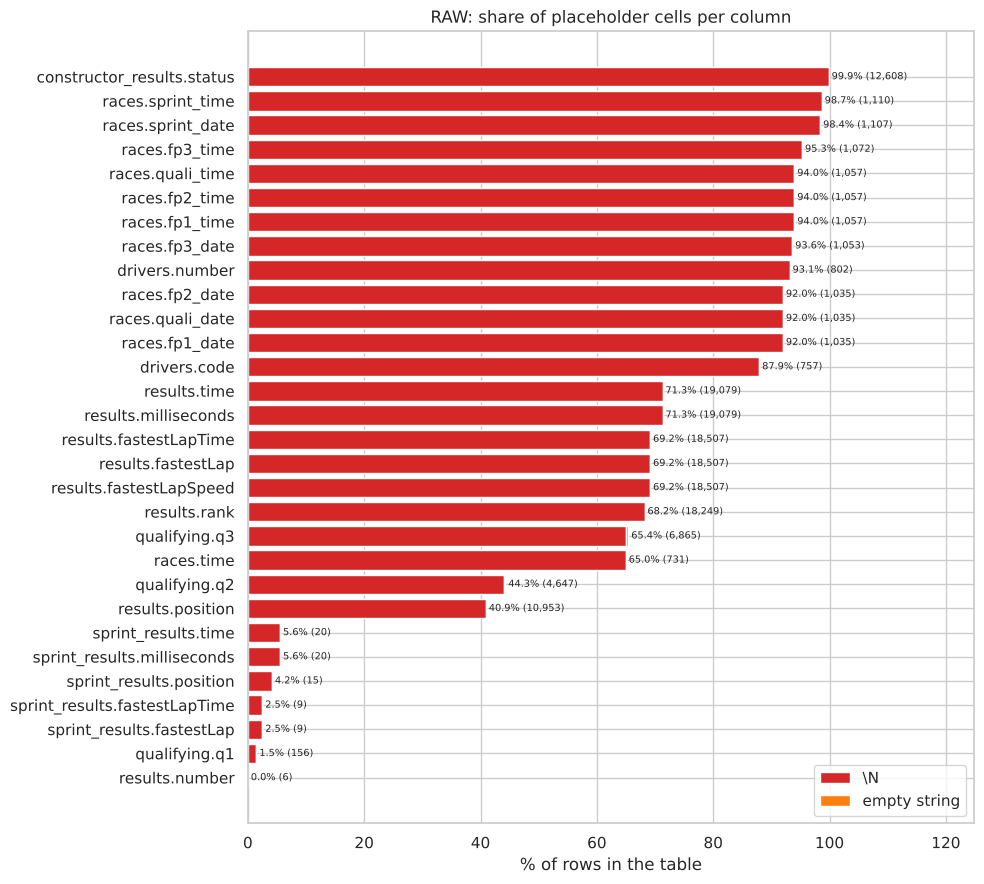

In [2]:
SENT = r"\N"   # the sentinel string used in the Ergast/Kaggle CSVs

# Count '\N' and empty-string cells per column, for every column that has at least one of them.
rows = []
for t, d in raw.items():
    for c in d.columns:
        n_sent, n_empty = int((d[c] == SENT).sum()), int((d[c].str.strip() == "").sum())
        if n_sent + n_empty > 0:
            rows.append({"table": t, "column": c, "\\N cells": n_sent, "empty cells": n_empty,
                         "pct missing": 100 * (n_sent + n_empty) / len(d)})
sent_df = pd.DataFrame(rows).sort_values("pct missing", ascending=False).reset_index(drop=True)

print(f"{len(sent_df)} columns in {sent_df['table'].nunique()} tables contain placeholders")
print("Empty-string cells (all tables):", int(sent_df["empty cells"].sum()))
display(sent_df[sent_df["empty cells"] > 0])
# Pandas itself sees no missing values at all in the raw text -> these are "hidden" missing values.
print("NaN cells pandas detects in the raw text:", sum(int(d.isna().sum().sum()) for d in raw.values()))

plot_df = sent_df.assign(label=sent_df["table"] + "." + sent_df["column"]).sort_values("pct missing")
fig, ax = plt.subplots(figsize=(10, max(4, 0.3 * len(plot_df))))
ax.barh(plot_df["label"], 100 * plot_df["\\N cells"] / plot_df["label"].map(lambda l: len(raw[l.split(".")[0]])),
        color="tab:red", label="\\N")
ax.barh(plot_df["label"], 100 * plot_df["empty cells"] / plot_df["label"].map(lambda l: len(raw[l.split(".")[0]])),
        left=100 * plot_df["\\N cells"] / plot_df["label"].map(lambda l: len(raw[l.split(".")[0]])), color="tab:orange", label="empty string")
for i, (p, n) in enumerate(zip(plot_df["pct missing"], plot_df["\\N cells"] + plot_df["empty cells"])):
    ax.text(p + 0.5, i, f"{p:.1f}% ({n:,})", va="center", fontsize=7)
ax.set_xlim(0, plot_df["pct missing"].max() * 1.25)
ax.set_title("RAW: share of placeholder cells per column")
ax.set_xlabel("% of rows in the table"); ax.legend(loc="lower right")
save_fig("01_raw_sentinels")

**What this shows.** Missing values are common but concentrated in a few places: race-session dates and times (`races.fp*`, only recorded recently), finishing times and fastest laps in `results` (empty for anyone who did not finish, and not recorded in early years), and `qualifying.q2/q3` (empty for drivers knocked out in Q1/Q2). These are *structural* missing values: each has a reason, which matters later when we decide how to fill them. The 68 empty strings all sit in `qualifying.q2/q3` of 2023–2024 races; they mean the same as `\N` and are treated the same way.

### 2.2 How the data changes over 75 seasons

Before cleaning anything we look at how the size and shape of a race changed over time. These plots explain most of the cleaning decisions in Section 3.

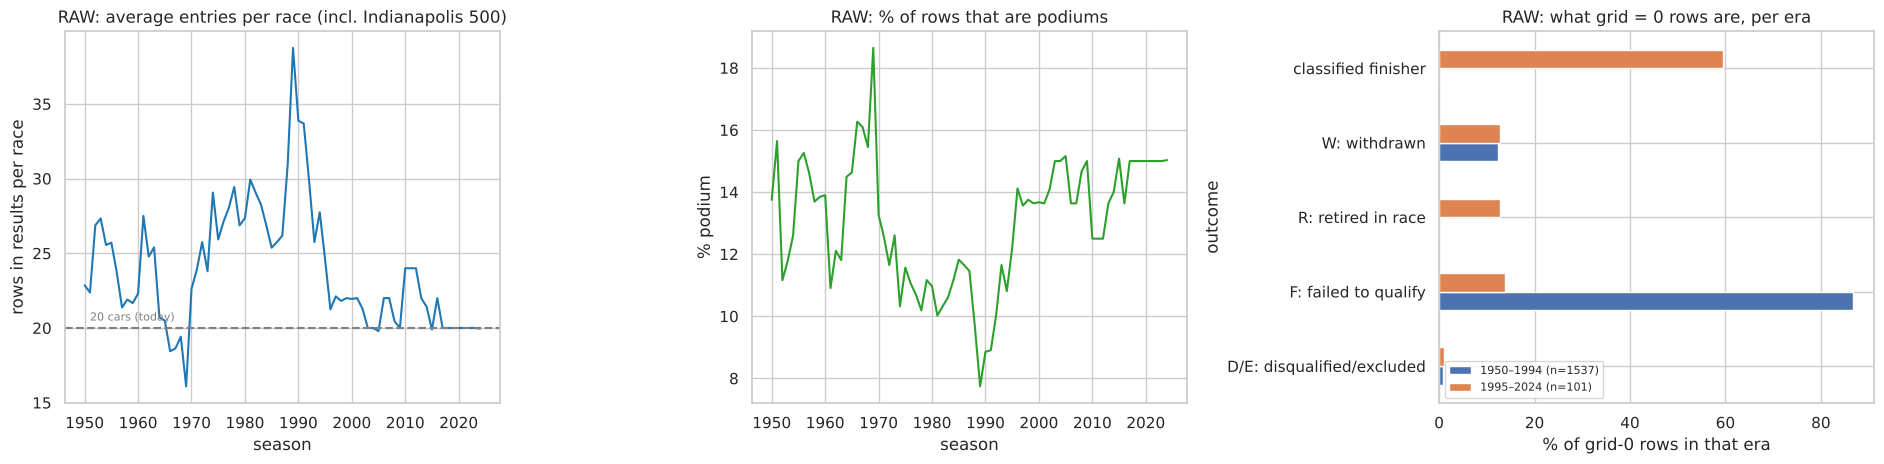

Rows with grid = 0: 1638


era,1950–1994 (n=1537),1995–2024 (n=101)
outcome,,
D/E: disqualified/excluded,12,1
F: failed to qualify,1334,14
R: retired in race,1,13
W: withdrawn,190,13
classified finisher,0,60


In [3]:
# Attach the season (year) and race name to every raw result row.
res_raw = raw["results"].merge(raw["races"][["raceId", "year", "name"]], on="raceId")
res_raw["year"] = res_raw["year"].astype(int)
res_raw = res_raw.merge(raw["status"], on="statusId", how="left")

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))

# (a) Entries per race: how many rows each race has in results.csv
per_race = res_raw.groupby(["year", "raceId"]).size().groupby("year").mean()
axes[0].plot(per_race.index, per_race.values, color="tab:blue")
axes[0].axhline(20, ls="--", color="gray"); axes[0].text(1951, 20.5, "20 cars (today)", color="gray", fontsize=8)
axes[0].set_title("RAW: average entries per race (incl. Indianapolis 500)")
axes[0].set_xlabel("season"); axes[0].set_ylabel("rows in results per race")

# (b) Podium share of rows per season: the base rate of the target before cleaning
pod_share = res_raw.assign(p=res_raw["positionOrder"].astype(int) <= 3).groupby("year")["p"].mean()
axes[1].plot(pod_share.index, pod_share.values * 100, color="tab:green")
axes[1].set_title("RAW: % of rows that are podiums")
axes[1].set_xlabel("season"); axes[1].set_ylabel("% podium")

# (c) What does grid = 0 mean? Share of each outcome among grid-0 rows, separately for each era
#     (shares, not counts, so the much smaller modern era stays visible).
g0 = res_raw[res_raw["grid"] == "0"].copy()
g0["era"] = np.where(g0["year"] < 1995, f"1950–1994 (n={int((g0['year'] < 1995).sum())})", f"1995–2024 (n={int((g0['year'] >= 1995).sum())})")
g0["outcome"] = np.select(
    [g0["positionText"].eq("F"), g0["positionText"].eq("W"), g0["positionText"].isin(["D", "E"]), g0["positionText"].eq("R"),
     g0["positionText"].str.isdigit() | g0["positionText"].eq("N")],
    ["F: failed to qualify", "W: withdrawn", "D/E: disqualified/excluded", "R: retired in race", "classified finisher"], default="other")
share = pd.crosstab(g0["outcome"], g0["era"], normalize="columns") * 100
share.plot(kind="barh", ax=axes[2])
axes[2].set_title("RAW: what grid = 0 rows are, per era")
axes[2].set_xlabel("% of grid-0 rows in that era"); axes[2].legend(fontsize=8)
save_fig("02_raw_eras")

print("Rows with grid = 0:", len(g0))
display(pd.crosstab(g0["outcome"], g0["era"]))

**What this shows.**

* (a) Early races had far more entries than the 20 cars of today, peaking above 30 in the late 1980s. (The 1950s line also includes the Indianapolis 500's 33-car fields, see D5.)
* (b) Because of that, only ~8–12% of rows are podiums in the busy eras, against ~15% today.
* (c) **`grid = 0` means two different things.** Before 1995 nearly all grid-0 rows are drivers who *never got onto the grid*: failed to qualify (`F`) or withdrawn (`W`). From 1995 on, most grid-0 rows are classified finishers or retirements, i.e. drivers who **started from the pit lane**. So a grid 0 cannot simply be read as a pit-lane start: the plot shows that holds only for drivers who actually took part. → handled in **D6** and **D7**.

### 2.3 Qualifying coverage per season

The brief warns about *historical qualifying-coverage drift*. We measure it two ways: the share of **races** that have any rows in `qualifying.csv`, and the share of **result rows** (driver-race entries) that have a matching qualifying row.

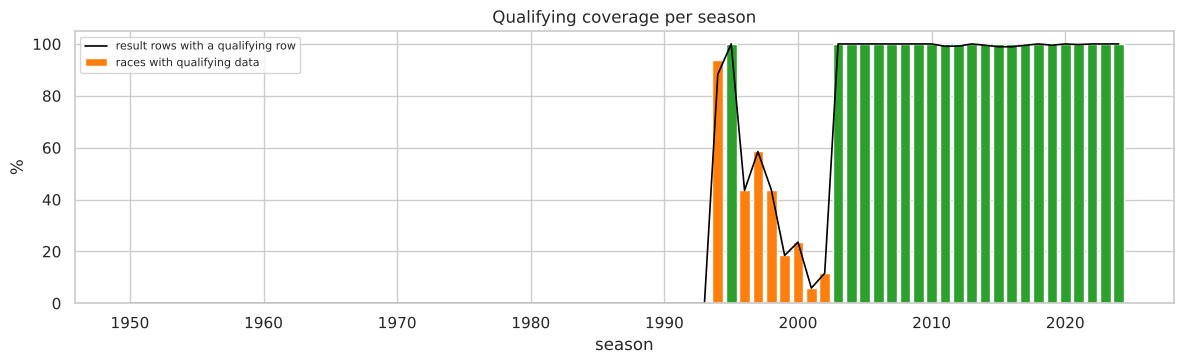

First season with qualifying data: 1994
Seasons with partial race coverage: {1994: 0.94, 1996: 0.44, 1997: 0.59, 1998: 0.44, 1999: 0.19, 2000: 0.24, 2001: 0.06, 2002: 0.12}
Row-level coverage 2003–2024 (min, mean): 0.989 0.997


In [4]:
races_y = raw["races"][["raceId", "year"]].astype({"year": int})
q_races = raw["qualifying"][["raceId"]].drop_duplicates().merge(races_y, on="raceId")
coverage = (q_races.groupby("year").size() / races_y.groupby("year").size()).reindex(races_y["year"].unique()).fillna(0).sort_index()

q_keys = set(zip(raw["qualifying"]["raceId"], raw["qualifying"]["driverId"]))
res_raw["has_quali_row"] = [k in q_keys for k in zip(res_raw["raceId"], res_raw["driverId"])]
row_cov = res_raw.groupby("year")["has_quali_row"].mean()

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.bar(coverage.index, coverage.values * 100, color=np.where(coverage.values >= 0.99, "tab:green", "tab:orange"), label="races with qualifying data")
ax.plot(row_cov.index, row_cov.values * 100, color="black", lw=1.2, label="result rows with a qualifying row")
ax.set_title("Qualifying coverage per season")
ax.set_ylabel("%"); ax.set_xlabel("season"); ax.legend(loc="upper left", fontsize=8)
save_fig("03_qualifying_coverage")

print("First season with qualifying data:", int(coverage[coverage > 0].index.min()))
print("Seasons with partial race coverage:", coverage[(coverage > 0) & (coverage < 0.99)].round(2).to_dict())
print("Row-level coverage 2003–2024 (min, mean):", round(row_cov.loc[2003:].min(), 3), round(row_cov.loc[2003:].mean(), 3))

**What this shows.** `qualifying.csv` is empty before 1994, covers 94% of races in 1994 and all of 1995, only 6–59% of races in 1996–2002, and every race from 2003 onwards (at row level a handful of starters per season still lack a qualifying row, mostly late entries or replacement drivers). So qualifying features will be missing for most rows before 2003, and for those seasons the `grid` column in `results.csv` is the only record of the starting order. We use this when choosing the training window (**D17**) and when handling missing qualifying values (**D15**).

### 2.4 Inconsistent text values

Text columns that are used to group or join rows (driver nationality, circuit country) must spell each value one way only. We check this in code rather than by eye: values that differ only by spaces or upper/lower case are flagged, and the full list of country names is printed so near-duplicates are visible. We also scan **every** text column of every table for HTML codes such as `&amp;`, which appear when a file was copied from a web page.

In [5]:
def spelling_variants(series):
    """Groups of distinct raw values that become identical after stripping spaces and lower-casing."""
    s = pd.Series(series.unique())
    key = s.str.strip().str.casefold()
    groups = s.groupby(key).apply(list)
    return groups[groups.map(len) > 1]

def shared_stem(series, n=6):
    """Groups of distinct values whose first n letters are equal (catches 'Argentine' vs 'Argentinian')."""
    s = pd.Series(sorted(series.str.strip().unique()))
    g = s.groupby(s.str[:n].str.casefold()).apply(list)
    return g[g.map(len) > 1].to_dict()

def acronym_pairs(series):
    """Pairs where a short value starts with the initials of a multi-word value (catches 'United States' vs 'USA')."""
    vals = sorted(series.str.strip().unique())
    return [(v, w) for v in vals if " " in v for w in vals
            if len(w) <= 4 and w.isupper() and w.startswith("".join(x[0] for x in v.split()).upper())]

nat = raw["drivers"]["nationality"]; ctry = raw["circuits"]["country"]
print("Nationality values with leading/trailing spaces:", sorted(v for v in nat.unique() if v != v.strip()))
print("Nationality values differing only by case/spaces:", spelling_variants(nat).to_dict())
print("Nationalities sharing a 6-letter stem:", shared_stem(nat))
print("Country names vs abbreviations:", acronym_pairs(ctry))
print(f"Distinct values before cleaning → nationalities: {nat.nunique()}, countries: {ctry.nunique()}")

HTML_CODE = r"&(?:#\d+|[a-z]+);"          # e.g. "&amp;" where the text should just say "&"
html_hits = {f"{t}.{c}": sorted(d.loc[d[c].str.contains(HTML_CODE), c].unique())
             for t, d in raw.items() for c in d.columns if d[c].str.contains(HTML_CODE).any()}
print("Values with HTML codes, in all tables:", html_hits)

Nationality values with leading/trailing spaces: ['Argentinian ']
Nationality values differing only by case/spaces: {}
Nationalities sharing a 6-letter stem: {'americ': ['American', 'American-Italian'], 'argent': ['Argentine', 'Argentine-Italian', 'Argentinian']}
Country names vs abbreviations: [('United States', 'USA')]
Distinct values before cleaning → nationalities: 43, countries: 35


Values with HTML codes, in all tables: {'constructors.name': ['Lotus-Pratt &amp; Whitney']}


**What this shows.** The code checks flag one nationality with a trailing space (`"Argentinian "`), a stem group in which `"Argentinian"` and `"Argentine"` are the same nationality (the other members, such as `"Argentine-Italian"` or `"American-Italian"`, are real dual nationalities), and a country written both as `"United States"` and as its abbreviation `"USA"`. Left as they are, they would split one country into two groups in the home-race question (Q2). The scan of all text columns also finds one constructor name written with an HTML code, `"Lotus-Pratt &amp; Whitney"`; it would print badly in tables and plots. Fixed in **D2**. Dual or historical nationalities (`"American-Italian"`, `"Argentine-Italian"`, `"East German"`, `"Rhodesian"`) are real values, not spelling errors; how they map to a home country is decided in Q2 (**D10**).

### 2.5 Columns that hold dates and durations as text

The brief asks for *semantic typing*: dates must become dates and durations must become numbers. First we list which columns hold time-like text and what their formats look like.

In [6]:
time_like = []
for t, d in raw.items():
    for c in d.columns:
        vals = d.loc[~d[c].isin([SENT, ""]), c]
        if len(vals) and (vals.str.contains(r"^\+?\d*:?\d+:\d+(?:\.\d+)?$|^\d{4}-\d{2}-\d{2}$|^\+\d+\.\d+$").mean() > 0.5):
            examples = vals.drop_duplicates().head(3).tolist()
            time_like.append({"table": t, "column": c, "non-missing": len(vals), "examples": examples})
display(pd.DataFrame(time_like))

,table,column,non-missing,examples
0,drivers,dob,861,"[1985-01-07, 1977-05-10, 1985-06-27]"
1,races,date,1125,"[2009-03-29, 2009-04-05, 2009-04-19]"
2,races,time,394,"[06:00:00, 09:00:00, 07:00:00]"
3,races,fp1_date,90,"[2021-04-16, 2022-03-18, 2021-03-26]"
4,races,fp1_time,68,"[12:00:00, 14:00:00, 03:00:00]"
5,races,fp2_date,90,"[2021-04-16, 2022-03-18, 2021-03-26]"
6,races,fp2_time,68,"[15:00:00, 17:00:00, 06:00:00]"
7,races,fp3_date,72,"[2021-04-17, 2022-03-19, 2021-03-27]"
8,races,fp3_time,53,"[12:00:00, 14:00:00, 03:00:00]"
9,races,quali_date,90,"[2021-04-17, 2022-03-19, 2021-03-27]"


**What this shows.** Dates (`races.date`, session dates, `drivers.dob`) and four kinds of durations are stored as text: lap times like `1:27.452` (qualifying, fastest laps, lap times), race times like `1:34:50.616` for the winner but **gaps** like `+5.478` for everyone else in the same column, pit-stop durations like `22.4` or `1:02.3`, and time-of-day values (`races.time`, `pit_stops.time`). Section 3.2 converts every one of them.

## 3. Cleaning

### 3.1 Sentinels → real missing values

We re-read every file and tell pandas that `\N` and empty strings mean "missing". `keep_default_na=False` stops pandas from also treating legitimate text such as `"NA"` as missing.

The check below is **cell by cell**: for every column, the set of cells that are NaN after cleaning must be exactly the set of cells that held `\N` or `""` in the raw text — no more, no fewer.

In [7]:
# Clean working copies: '\N' and '' become NaN. The raw dict stays untouched (D1).
df = {t: pd.read_csv(f"{DATA_DIR}/{t}.csv", na_values=[SENT, ""], keep_default_na=False) for t in TABLES}

# Cell-wise check: NaN in the clean copy <=> placeholder in the raw text, in every column of every table.
mismatch = {t: int(((raw[t].isin([SENT, ""])).values != df[t][raw[t].columns].isna().values).sum()) for t in TABLES}
check = pd.DataFrame({"placeholder cells in raw": {t: int(raw[t].isin([SENT, ""]).sum().sum()) for t in TABLES},
                      "NaN cells after cleaning": {t: int(df[t].isna().sum().sum()) for t in TABLES},
                      "cells that disagree": mismatch})
assert sum(mismatch.values()) == 0, "a placeholder was not converted, or a real value became NaN"
check

,placeholder cells in raw,NaN cells after cleaning,cells that disagree
circuits,0,0,0
constructors,0,0,0
constructor_results,12608,12608,0
constructor_standings,0,0,0
drivers,1559,1559,0
driver_standings,0,0,0
races,11349,11349,0
results,122887,122887,0
qualifying,11668,11668,0
lap_times,0,0,0


### 3.2 Semantic typing and text normalisation

Every column listed in 2.5 gets a proper type:

| raw text | becomes | columns |
|---|---|---|
| `2023-07-30` | `datetime` | `races.date`, session dates, `drivers.dob` |
| date + `15:00:00` | one `datetime` (UTC) | `race_start`, `quali_start`, `sprint_start` |
| `1:27.452`, `27.452` | seconds (float) | qualifying `q1–q3`, `fastestLapTime` (results and sprint), `lap_times.time` |
| `1:34:50.616` / `+5.478` | seconds from `milliseconds` | `race_time_sec` (results and sprint) |
| `22.4`, `1:02.3` | seconds (float) | `pit_stops.duration` |
| `17:05:23` | `timedelta` (time of day) | `pit_stops.time` |

The `results.time` column itself stays as text: it mixes the winner's total time with gaps to the winner (`+5.478`), so it is a display string, not one quantity. The same information as a single number is `milliseconds`, which we convert to `race_time_sec`.

A hidden placeholder that is a **number** is also turned into NaN: `results.rank = 0` means no fastest-lap rank was recorded (2011–2024). And one real data error is caught by a plausibility rule: in the 2024 Belgian GP the `milliseconds` column holds the gaps to the winner instead of race times, so those race times are set to missing.

🔶 **Decision D2** — we normalise text values that mean the same thing but are written differently, as found in 2.4: `"Argentinian "` → `"Argentine"`, `"United States"` → `"USA"`, and HTML codes are turned back into characters (`"&amp;"` → `"&"`).

In [8]:
def to_seconds(s):
    """Convert a time string to seconds: '1:27.452' -> 87.452, '27.452' -> 27.452, '1:34:50.616' -> 5690.616, NaN -> NaN."""
    if pd.isna(s):
        return np.nan
    s = str(s).strip()
    try:
        parts = s.split(":")
        if len(parts) == 1:
            return float(parts[0])                                              # ss.xxx
        if len(parts) == 2:
            return int(parts[0]) * 60 + float(parts[1])                         # m:ss.xxx
        if len(parts) == 3:
            return int(parts[0]) * 3600 + int(parts[1]) * 60 + float(parts[2])  # h:mm:ss.xxx
    except ValueError:
        pass
    return np.nan

converted = []   # (table, raw column, new column) -> checked for parse failures below

# --- Dates and start times ------------------------------------------------------
df["races"]["date"] = pd.to_datetime(df["races"]["date"], errors="coerce")
for c in ["fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"]:
    df["races"][c] = pd.to_datetime(df["races"][c], errors="coerce")
df["races"]["race_start"] = df["races"]["date"] + pd.to_timedelta(df["races"]["time"])          # NaT where time unknown
df["races"]["quali_start"] = df["races"]["quali_date"] + pd.to_timedelta(df["races"]["quali_time"])
df["races"]["sprint_start"] = df["races"]["sprint_date"] + pd.to_timedelta(df["races"]["sprint_time"])
df["drivers"]["dob"] = pd.to_datetime(df["drivers"]["dob"], errors="coerce")

# --- Lap-time strings -> seconds ------------------------------------------------
for c in ["q1", "q2", "q3"]:
    df["qualifying"][c + "_sec"] = df["qualifying"][c].map(to_seconds); converted.append(("qualifying", c, c + "_sec"))
for t in ["results", "sprint_results"]:
    df[t]["fastestLapTime_sec"] = df[t]["fastestLapTime"].map(to_seconds); converted.append((t, "fastestLapTime", "fastestLapTime_sec"))
df["lap_times"]["time_sec"] = df["lap_times"]["time"].map(to_seconds); converted.append(("lap_times", "time", "time_sec"))
df["pit_stops"]["duration_sec"] = df["pit_stops"]["duration"].map(to_seconds); converted.append(("pit_stops", "duration", "duration_sec"))
df["pit_stops"]["time_of_day"] = pd.to_timedelta(df["pit_stops"]["time"], errors="coerce"); converted.append(("pit_stops", "time", "time_of_day"))

# --- Numeric columns that arrived as text, race time in seconds -----------------
for t in ["results", "sprint_results"]:
    for c in ["number", "position", "fastestLap", "rank", "fastestLapSpeed", "milliseconds"]:
        if c in df[t]:
            df[t][c] = pd.to_numeric(df[t][c], errors="coerce")
    df[t]["race_time_sec"] = df[t]["milliseconds"] / 1000
df["results"]["rank"] = df["results"]["rank"].replace(0, np.nan)        # 0 = no fastest-lap rank recorded
# Impossible race times: no F1 lap takes under 30 s, so a race time below laps × 30 s is a data error
# (2024 Belgian GP: the column holds gaps to the winner in ms). Mark those as missing instead of keeping a wrong number.
bad_time = df["results"]["race_time_sec"] < df["results"]["laps"] * 30
print("Impossible race times set to NaN:", int(bad_time.sum()), "rows in raceIds", sorted(int(x) for x in df["results"].loc[bad_time, "raceId"].unique()))
df["results"].loc[bad_time, "race_time_sec"] = np.nan

# DECISION D2 → see DECISIONS.md  (one spelling per nationality / country)
df["drivers"]["nationality"] = df["drivers"]["nationality"].str.strip().replace({"Argentinian": "Argentine"})
df["circuits"]["country"] = df["circuits"]["country"].str.strip().replace({"United States": "USA"})
df["constructors"]["name"] = df["constructors"]["name"].map(html.unescape)
assert not any(df[t][c].astype(str).str.contains(HTML_CODE).any() for t, c in (k.split(".") for k in html_hits)), "an HTML code is left"
print("HTML codes fixed:", {k: [html.unescape(v) for v in vals] for k, vals in html_hits.items()})

# Check EVERY conversion: a non-missing text value that became NaN would be a parse failure.
fails = pd.DataFrame([{"table": t, "column": c, "non-missing values": int(df[t][c].notna().sum()),
                       "failed to convert": int((df[t][c].notna() & df[t][new].isna()).sum())} for t, c, new in converted])
display(fails)
assert fails["failed to convert"].sum() == 0
# Cross-check: lap times parsed from text agree with the milliseconds column.
assert np.allclose(df["lap_times"]["time_sec"], df["lap_times"]["milliseconds"] / 1000, atol=0.0015)
print(f"Distinct values after D2 → nationalities: {df['drivers']['nationality'].nunique()} (was {raw['drivers']['nationality'].nunique()}), "
      f"countries: {df['circuits']['country'].nunique()} (was {raw['circuits']['country'].nunique()})")

Impossible race times set to NaN: 18 rows in raceIds [1134]
HTML codes fixed: {'constructors.name': ['Lotus-Pratt & Whitney']}


,table,column,non-missing values,failed to convert
0,qualifying,q1,10338,0
1,qualifying,q2,5847,0
2,qualifying,q3,3629,0
3,results,fastestLapTime,8252,0
4,sprint_results,fastestLapTime,351,0
5,lap_times,time,589081,0
6,pit_stops,duration,11371,0
7,pit_stops,time,11371,0


Distinct values after D2 → nationalities: 42 (was 43), countries: 34 (was 35)


**Effect of typing on the values.** Now that durations are numbers, their ranges can be inspected. The plot shows the three duration types as distributions; the table lists their range.

,count,mean,std,min,1%,50%,99%,max
qualifying lap q1 (s),10338.0,88.53,15.39,53.90,65.18,87.14,123.96,1002.64
race lap (s),589081.0,95.80,76.40,55.40,69.85,90.61,158.18,7507.55
pit-stop duration (s),11371.0,85.23,310.43,12.90,16.53,23.61,1848.22,3069.02
"race time, finishers (min)",7662.0,103.34,27.41,3.45,73.75,96.49,233.23,251.51


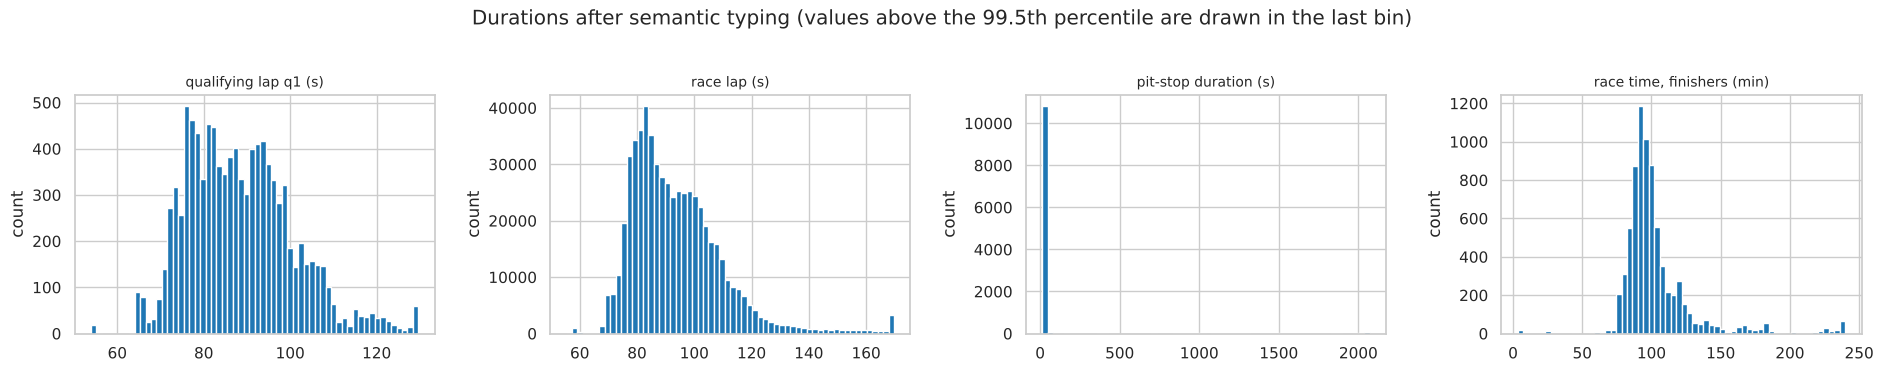

Laps longer than 5 minutes (red-flag / safety-car periods): 708
Pit 'stops' longer than 60 s (red-flag stoppages, repairs): 517


In [9]:
dur = {"qualifying lap q1 (s)": df["qualifying"]["q1_sec"], "race lap (s)": df["lap_times"]["time_sec"],
       "pit-stop duration (s)": df["pit_stops"]["duration_sec"], "race time, finishers (min)": df["results"]["race_time_sec"] / 60}
display(pd.DataFrame({k: v.describe(percentiles=[0.01, 0.5, 0.99]) for k, v in dur.items()}).T.round(2))
fig, axes = plt.subplots(1, 4, figsize=(19, 3.6))
for ax, (k, v) in zip(axes, dur.items()):
    v = v.dropna()
    ax.hist(v.clip(upper=v.quantile(0.995)), bins=60, color="tab:blue")
    ax.set_title(k, fontsize=10); ax.set_ylabel("count")
fig.suptitle("Durations after semantic typing (values above the 99.5th percentile are drawn in the last bin)", y=1.03)
save_fig("04_durations_typed")
print("Laps longer than 5 minutes (red-flag / safety-car periods):", int((df["lap_times"]["time_sec"] > 300).sum()))
print("Pit 'stops' longer than 60 s (red-flag stoppages, repairs):", int((df["pit_stops"]["duration_sec"] > 60).sum()))

**What this shows.** Every text value converted without failures. The typed values have sensible ranges: qualifying and race laps cluster between ~60 and ~120 s, normal pit stops take 20–30 s. The long tails are real events, not errors: laps over 5 minutes are red-flag or safety-car periods, and "pit stops" over a minute are red-flag stoppages or repairs. We keep them as they are, because none of these columns is used as a model feature (they are all post-race information, see Section 6).

### 3.3 Primary and foreign keys

A **primary key** must be unique and never empty. A **foreign key** must point to a row that exists in its parent table. If a foreign key points nowhere, a join would silently drop or duplicate rows. Because the surrogate IDs (`resultId`, `qualifyId`, …) are unique by construction, we also check the **natural keys** that the joins actually use, and a few **reverse** links.

In [10]:
PK = {
    "circuits": ["circuitId"], "constructors": ["constructorId"],
    "constructor_results": ["constructorResultsId"], "constructor_standings": ["constructorStandingsId"],
    "drivers": ["driverId"], "driver_standings": ["driverStandingsId"],
    "races": ["raceId"], "results": ["resultId"], "qualifying": ["qualifyId"],
    "sprint_results": [c for c in ["sprintResultId", "resultId"] if c in df["sprint_results"].columns][:1],
    "seasons": ["year"], "status": ["statusId"],
    "lap_times": ["raceId", "driverId", "lap"], "pit_stops": ["raceId", "driverId", "stop"],
}
NATURAL = {   # keys our joins rely on (results is NOT here: its (raceId, driverId) duplicates are handled in 3.5)
    "qualifying": ["raceId", "driverId"], "races": ["year", "round"], "driver_standings": ["raceId", "driverId"],
    "constructor_standings": ["raceId", "constructorId"], "sprint_results": ["raceId", "driverId"],
}
pk_report = pd.DataFrame([{"table": t, "key": "+".join(cols), "kind": kind,
                           "rows_with_null_key": int(df[t][cols].isna().any(axis=1).sum()),
                           "duplicate_key_rows": int(df[t].duplicated(cols, keep=False).sum())}
                          for kind, keys in [("primary", PK), ("natural", NATURAL)] for t, cols in keys.items()])
pk_report["valid"] = (pk_report["rows_with_null_key"] == 0) & (pk_report["duplicate_key_rows"] == 0)
display(pk_report)

# (child table, foreign key column(s), parent table, parent key column(s))
FK = [("races", "year", "seasons", "year"), ("races", "circuitId", "circuits", "circuitId"),
      ("results", "raceId", "races", "raceId"), ("results", "driverId", "drivers", "driverId"),
      ("results", "constructorId", "constructors", "constructorId"), ("results", "statusId", "status", "statusId"),
      ("qualifying", "raceId", "races", "raceId"), ("qualifying", "driverId", "drivers", "driverId"),
      ("qualifying", "constructorId", "constructors", "constructorId"),
      ("sprint_results", "raceId", "races", "raceId"), ("sprint_results", "driverId", "drivers", "driverId"),
      ("sprint_results", "constructorId", "constructors", "constructorId"), ("sprint_results", "statusId", "status", "statusId"),
      ("lap_times", "raceId", "races", "raceId"), ("lap_times", "driverId", "drivers", "driverId"),
      ("pit_stops", "raceId", "races", "raceId"), ("pit_stops", "driverId", "drivers", "driverId"),
      ("driver_standings", "raceId", "races", "raceId"), ("driver_standings", "driverId", "drivers", "driverId"),
      ("constructor_standings", "raceId", "races", "raceId"), ("constructor_standings", "constructorId", "constructors", "constructorId"),
      ("constructor_results", "raceId", "races", "raceId"), ("constructor_results", "constructorId", "constructors", "constructorId"),
      # composite links: every lap / pit stop / qualifying row belongs to a driver who has a result in that race
      ("lap_times", ["raceId", "driverId"], "results", ["raceId", "driverId"]),
      ("pit_stops", ["raceId", "driverId"], "results", ["raceId", "driverId"]),
      ("qualifying", ["raceId", "driverId"], "results", ["raceId", "driverId"])]

def orphans(child, col, parent, pcol):
    if isinstance(col, list):
        parent_keys = set(map(tuple, df[parent][pcol].values))
        return int(sum(tuple(k) not in parent_keys for k in df[child][col].values))
    return int((~df[child][col].dropna().isin(df[parent][pcol])).sum())

fk_report = pd.DataFrame([{"child": c, "foreign_key": "+".join(col) if isinstance(col, list) else col, "parent": p,
                           "rows_checked": len(df[c]), "orphans": orphans(c, col, p, pcol)} for c, col, p, pcol in FK])
fk_report["valid"] = fk_report["orphans"] == 0
display(fk_report)
print("Races with no result rows:", int((~df["races"]["raceId"].isin(df["results"]["raceId"])).sum()))
print("All keys valid:", bool(pk_report["valid"].all()), "| all foreign keys reconcile:", bool(fk_report["valid"].all()))

,table,key,kind,rows_with_null_key,duplicate_key_rows,valid
0,circuits,circuitId,primary,0,0,True
1,constructors,constructorId,primary,0,0,True
2,constructor_results,constructorResultsId,primary,0,0,True
3,constructor_standings,constructorStandingsId,primary,0,0,True
4,drivers,driverId,primary,0,0,True
5,driver_standings,driverStandingsId,primary,0,0,True
6,races,raceId,primary,0,0,True
7,results,resultId,primary,0,0,True
8,qualifying,qualifyId,primary,0,0,True
9,sprint_results,resultId,primary,0,0,True


,child,foreign_key,parent,rows_checked,orphans,valid
0,races,year,seasons,1125,0,True
1,races,circuitId,circuits,1125,0,True
2,results,raceId,races,26759,0,True
3,results,driverId,drivers,26759,0,True
4,results,constructorId,constructors,26759,0,True
5,results,statusId,status,26759,0,True
6,qualifying,raceId,races,10494,0,True
7,qualifying,driverId,drivers,10494,0,True
8,qualifying,constructorId,constructors,10494,0,True
9,sprint_results,raceId,races,360,0,True


Races with no result rows: 0
All keys valid: True | all foreign keys reconcile: True


**What this shows.** Every primary and natural key is unique and non-null, every foreign key resolves to an existing parent row (0 orphans in all 26 relationships), every lap, pit stop and qualifying row belongs to a driver with a result in that race, and every race has results. Joins between these tables are therefore safe: they cannot create orphan rows or duplicate rows.

`results` passes its primary-key check (`resultId` is unique) even though the same *driver* can appear twice in one race. That is a different kind of duplicate, handled in 3.5.

### 3.4 Grouping the status values

`status` says why a driver's race ended (139 labels in the Kaggle version of the dataset). We need it to define who was on the grid (3.6) and to answer Q3 on mechanical retirements. Every label is assigned to exactly **one** category by an explicit list (no "everything else" default), and an assertion checks that no label is left out or listed twice.

🔶 **Decision D3** — status categories. The guiding rule comes from the brief: *mechanical = a component of the car failed; not a crash, not the driver, not a regulation decision.* A label is only `mechanical` if the label itself names a failed component. Labels that describe **damage that is usually caused by contact or by the pit crew** (wheels, tyres, wings, bodywork, debris) go to `ambiguous`, so tyre, wheel and wing labels are treated the same way.

| category | meaning | examples |
|---|---|---|
| `finished` | reached the chequered flag (incl. *Not classified*: running at the end but too far behind to be classified) | Finished, +1 Lap, +2 Laps, Not classified |
| `did_not_qualify` | eliminated in qualifying | Did not qualify, Did not prequalify, 107% Rule |
| `withdrawn` | withdrew; whether he started is decided per row (3.6) | Withdrew |
| `mechanical` | the label names a failed car component | Engine, Gearbox, Hydraulics, Brakes, Power Unit, Electrical, Fuel pump, Seat, Safety belt… |
| `accident_driver` | crash, driver error or driver's health | Accident, Collision, Spun off, Collision damage, Injury, Illness |
| `regulation` | a regulation decision | Disqualified, Excluded, Underweight |
| `team_operational` | a pit-stop or refuelling error by the team | Wheel nut, Fuel rig, Refuelling |
| `ambiguous` | cause cannot be told from the label | Retired, Puncture, Tyre, Wheel, Front/Rear wing, Undertray, Damage, Debris, Out of fuel, Stalled |

In Q3 we report the strict rate (`mechanical` only) and check with the broad rate (adding `ambiguous`) whether the answer depends on this choice.

In [11]:
# DECISION D3 → see DECISIONS.md  (explicit status -> category mapping, every label exactly once)
FINISHED_RE = re.compile(r"^(Finished|Lapped|\+\d+ Laps?)$")
STATUS_GROUPS = {
    "finished": {"Not classified"},                 # + every "+N Laps" / Finished / Lapped via the regex
    "did_not_qualify": {"Did not qualify", "Did not prequalify", "107% Rule"},
    "withdrawn": {"Withdrew", "Did not start"},
    "regulation": {"Disqualified", "Excluded", "Underweight"},
    "accident_driver": {"Accident", "Collision", "Spun off", "Collision damage", "Fatal accident", "Injury", "Injured",
                        "Eye injury", "Illness", "Driver unwell", "Physical"},
    "team_operational": {"Wheel nut", "Fuel rig", "Refuelling"},
    "ambiguous": {"Retired", "Puncture", "Tyre puncture", "Tyre", "Wheel", "Wheel rim", "Front wing", "Rear wing",
                  "Broken wing", "Undertray", "Damage", "Debris", "Out of fuel", "Stalled", "Handling",
                  "Not restarted", "Safety", "Safety concerns"},
    "mechanical": {"Engine", "Gearbox", "Transmission", "Clutch", "Hydraulics", "Electrical", "Radiator", "Suspension",
                   "Brakes", "Differential", "Overheating", "Mechanical", "Driver Seat", "Driveshaft", "Fuel pressure",
                   "Water pressure", "Throttle", "Steering", "Technical", "Electronics", "Heat shield fire", "Exhaust",
                   "Oil leak", "Water leak", "Fuel pump", "Track rod", "Oil pressure", "Engine fire", "Pneumatics",
                   "Fire", "Wheel bearing", "Fuel system", "Oil line", "Launch control", "Fuel", "Power loss",
                   "Vibrations", "Drivetrain", "Ignition", "Chassis", "Battery", "Halfshaft", "Crankshaft",
                   "Alternator", "Safety belt", "Oil pump", "Fuel leak", "Injection", "Distributor", "Turbo",
                   "CV joint", "Water pump", "Spark plugs", "Fuel pipe", "Oil pipe", "Axle", "Water pipe", "Magneto",
                   "Supercharger", "Engine misfire", "Power Unit", "ERS", "Brake duct", "Seat", "Cooling system"},
}
label_to_cat = {lab: cat for cat, labs in STATUS_GROUPS.items() for lab in labs}
assert sum(len(v) for v in STATUS_GROUPS.values()) == len(label_to_cat), "a label is listed in two categories"

def status_category(s):
    return "finished" if FINISHED_RE.match(s) else label_to_cat.get(s)

df["status"]["category"] = df["status"]["status"].map(status_category)
unmapped = df["status"].loc[df["status"]["category"].isna(), "status"].tolist()
assert not unmapped, f"status labels without a category: {unmapped}"

# Full mapping, with how often each category occurs in results (so it can be checked and quoted).
use = df["results"]["statusId"].map(df["status"].set_index("statusId")["category"]).value_counts()
for cat in STATUS_GROUPS:
    labels = sorted(df["status"].loc[df["status"]["category"] == cat, "status"], key=lambda x: (x[0] != "+", x))
    shown = labels if len(labels) < 20 else labels[:6] + ["…"] + labels[-3:]
    print(f"[{cat}] {len(labels)} labels, {int(use.get(cat, 0)):,} result rows\n   {', '.join(shown)}\n")

[finished] 35 labels, 15,333 result rows
   +1 Lap, +10 Laps, +11 Laps, +12 Laps, +13 Laps, +14 Laps, …, +9 Laps, Finished, Not classified

[did_not_qualify] 3 labels, 1,365 result rows
   107% Rule, Did not prequalify, Did not qualify

[withdrawn] 1 labels, 248 result rows
   Withdrew

[regulation] 3 labels, 156 result rows
   Disqualified, Excluded, Underweight

[accident_driver] 11 labels, 2,839 result rows
   Accident, Collision, Collision damage, Driver unwell, Eye injury, Fatal accident, Illness, Injured, Injury, Physical, Spun off

[team_operational] 3 labels, 12 result rows
   Fuel rig, Refuelling, Wheel nut

[ambiguous] 18 labels, 489 result rows
   Broken wing, Damage, Debris, Front wing, Handling, Not restarted, Out of fuel, Puncture, Rear wing, Retired, Safety, Safety concerns, Stalled, Tyre, Tyre puncture, Undertray, Wheel, Wheel rim

[mechanical] 65 labels, 6,317 result rows
   Alternator, Axle, Battery, Brake duct, Brakes, CV joint, …, Water pressure, Water pump, Wheel b

### 3.5 Duplicate drivers in one race (shared drives)

The modeling table needs exactly **one row per (raceId, driverId)**: each row is one prediction. In the 1950s and early 1960s a driver could hand his car to a teammate mid-race or take over a teammate's car, and the dataset then gives him **two rows** in the same race, one per car.

In [12]:
res = df["results"].merge(df["races"][["raceId", "year", "round", "name"]], on="raceId", how="left")
res = res.merge(df["status"][["statusId", "status", "category"]], on="statusId", how="left")
res = res.merge(df["drivers"][["driverId", "surname"]], on="driverId", how="left")

dup_mask = res.duplicated(["raceId", "driverId"], keep=False)
dups = res[dup_mask].sort_values(["raceId", "driverId", "resultId"])
print(f"Rows involved: {len(dups)} | duplicated (raceId, driverId) pairs: {len(dups[['raceId', 'driverId']].drop_duplicates())}")
print("Seasons affected:", dups["year"].min(), "to", dups["year"].max())
print("Of these pairs, at the Indianapolis 500:", dups[dups["name"] == "Indianapolis 500"][["raceId", "driverId"]].drop_duplicates().shape[0])
print("Pairs by decade:", dups.drop_duplicates(["raceId", "driverId"]).groupby(dups["year"] // 10 * 10).size().to_dict())

# A real example: the 1957 British Grand Prix (Moss and Brooks swapped cars; Vanwall #18 and #20).
example = res[(res["year"] == 1957) & (res["name"] == "British Grand Prix") & res["surname"].isin(["Moss", "Brooks"])]
display(example[["resultId", "surname", "number", "grid", "positionOrder", "points", "laps", "status"]])

# How are the two rows of a pair stored? Compare each row's resultId with the race's block of single-entry rows.
pos = []
for (rid, did), g in dups[dups["name"] != "Indianapolis 500"].groupby(["raceId", "driverId"]):
    single = res[(res["raceId"] == rid) & ~res["driverId"].isin(dups.loc[dups["raceId"] == rid, "driverId"])]["resultId"]
    lo_id, hi_id = sorted(g["resultId"])[:2]
    pos.append({"lower id inside the race's block": lo_id <= single.max() + 5, "higher id appended after the block": hi_id > single.max() + 5})
pos = pd.DataFrame(pos)
print("Non-Indy pairs:", len(pos), "|", pos.sum().to_dict())

Rows involved: 176 | duplicated (raceId, driverId) pairs: 85
Seasons affected: 1950 to 1978
Of these pairs, at the Indianapolis 500: 21
Pairs by decade: {1950: 79, 1960: 5, 1970: 1}


,resultId,surname,number,grid,positionOrder,points,laps,status
18805,18806,Brooks,20.0,3,1,4.0,90,Finished
18816,18817,Moss,18.0,1,12,0.0,51,Engine
20288,20291,Moss,20.0,3,1,5.0,90,Finished
20290,20293,Brooks,18.0,1,12,0.0,51,Engine


Non-Indy pairs: 64 | {"lower id inside the race's block": 64, 'higher id appended after the block': 33}


In the example, Moss started car #18 from pole, then took over Brooks' car #20 and won it, while Brooks drove #18 until its engine failed. So **both** drivers appear twice, and **both** have a row with `positionOrder = 1`. The last print shows how the data is stored: for every pair, the row with the lower `resultId` sits inside the race's normal block of entries (the driver's own entry), while in about half of the pairs the second row was appended later with a much higher `resultId` (the co-driver credit).

A few later duplicates (1960s–1978) are a driver entered in two cars, e.g. failing to qualify in both; most of those rows are removed anyway in 3.6.

Two candidate rules, measured on the data:

* **A — keep the best `positionOrder`**. Each driver keeps his best result, so a car's finish can be credited to two drivers.
* **B — keep the driver's own entry (lowest `resultId`).** This is usually the row of the car the driver was entered in, which is the car his pre-race information (grid slot, qualifying) describes.
* **C — keep the car only he is recorded in; otherwise B.** When a driver takes over a team-mate's car, that car also lists its original driver, while the car he started in lists only him. So if **exactly one** of a driver's cars has only him recorded, that is his starting car and we keep it. When both or neither of his cars are like that (e.g. two team-mates who swapped cars, so both cars list two drivers), the data cannot tell, and the rule falls back to B.

We compare them with two integrity checks that must hold in a clean table: *at most 3 podium rows per race* and *one driver per car per race*.

,rule,races with more than 3 podium rows,drivers sharing one car (affected races)
0,A: best positionOrder,15,121
1,B: own entry (lowest resultId),2,36
2,"C: car only he is in, else B",1,30


Rows removed: 67 under every rule | podium labels that differ between A and B: 15, between B and C: 1
Pairs where rule C keeps a different car than rule B:


,year,name,surname,kept by,number,grid,laps,positionOrder,status
19918,1951,French Grand Prix,Ascari,rule B,14.0,6,77,2,Finished
19934,1951,French Grand Prix,Ascari,rule C,12.0,3,10,18,Gearbox
19267,1954,Belgian Grand Prix,González,rule B,10.0,5,35,4,+1 Lap
19275,1954,Belgian Grand Prix,González,rule C,6.0,2,1,12,Engine
17961,1961,British Grand Prix,Moss,rule B,26.0,20,56,19,Disqualified
17963,1961,British Grand Prix,Moss,rule C,28.0,5,44,21,Brakes
17740,1962,British Grand Prix,Greene,rule B,48.0,0,0,22,Withdrew
17743,1962,British Grand Prix,Greene,rule C,50.0,0,0,25,Withdrew


Rows sharing a positionOrder with another row in the same race (shared cars, 1950s–60s): 155


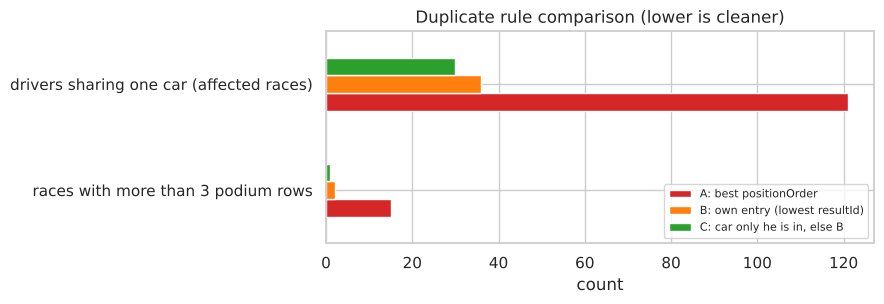

In [13]:
non_indy = res[res["name"] != "Indianapolis 500"]          # Indy is removed anyway (D5), keep the comparison clean
rule_a = non_indy.sort_values(["positionOrder", "resultId"]).drop_duplicates(["raceId", "driverId"])
rule_b = non_indy.sort_values("resultId").drop_duplicates(["raceId", "driverId"])

def own_car_rule(t):
    """Rule C: keep the car only this driver is recorded in (his starting car) if exactly one of his cars is like that;
    otherwise the lowest resultId (rule B). A car = (race, constructor, car number)."""
    number = t["number"].fillna(-t["resultId"])                      # an unknown car number counts as its own car
    solo = t.groupby([t["raceId"], t["constructorId"], number])["driverId"].transform("nunique").eq(1)
    n_solo = solo.groupby([t["raceId"], t["driverId"]]).transform("sum")
    first = (solo & n_solo.eq(1)).map({True: 0, False: 1})
    return t.assign(_first=first).sort_values(["_first", "resultId"]).drop_duplicates(["raceId", "driverId"]).drop(columns="_first")

rule_c = own_car_rule(non_indy)

def integrity(t, name):
    raced = t[~t["category"].isin(["did_not_qualify", "withdrawn"])]   # non-starters share car numbers legitimately
    podiums_per_race = t.groupby("raceId")["positionOrder"].apply(lambda s: (s <= 3).sum())
    return {"rule": name,
            "races with more than 3 podium rows": int((podiums_per_race > 3).sum()),
            "drivers sharing one car (affected races)": int(raced[raced["raceId"].isin(dups["raceId"])]
                                                            .duplicated(["raceId", "number"], keep=False).sum())}

cmp = pd.DataFrame([integrity(rule_a, "A: best positionOrder"), integrity(rule_b, "B: own entry (lowest resultId)"),
                    integrity(rule_c, "C: car only he is in, else B")])
display(cmp)

lab_a = rule_a.set_index(["raceId", "driverId"])["positionOrder"].le(3)
lab_b = rule_b.set_index(["raceId", "driverId"])["positionOrder"].le(3)
lab_c = rule_c.set_index(["raceId", "driverId"])["positionOrder"].le(3)
print(f"Rows removed: {len(non_indy) - len(rule_c)} under every rule | podium labels that differ between A and B: "
      f"{int((lab_a != lab_b.reindex(lab_a.index)).sum())}, between B and C: {int((lab_b != lab_c.reindex(lab_b.index)).sum())}")

# The pairs where C keeps a different car than B: the dropped row is a car the driver took over during the race.
kept_b, kept_c = set(rule_b["resultId"]), set(rule_c["resultId"])
changed = non_indy[non_indy["resultId"].isin(kept_b ^ kept_c)].copy()
changed["kept by"] = np.where(changed["resultId"].isin(kept_c), "rule C", "rule B")
print("Pairs where rule C keeps a different car than rule B:")
display(changed.sort_values(["year", "surname", "kept by"])[["year", "name", "surname", "kept by", "number", "grid", "laps", "positionOrder", "status"]])
ties = non_indy.duplicated(["raceId", "positionOrder"], keep=False)
print("Rows sharing a positionOrder with another row in the same race (shared cars, 1950s–60s):", int(ties.sum()))

fig, ax = plt.subplots(figsize=(9, 3.2))
cmp.set_index("rule").T.plot(kind="barh", ax=ax, color=["tab:red", "tab:orange", "tab:green"])
ax.set_title("Duplicate rule comparison (lower is cleaner)"); ax.set_xlabel("count")
ax.legend(loc="lower right", fontsize=8)
save_fig("05_duplicate_rule")

**What this shows.** All three rules remove the same 67 rows; they differ in *which* row survives. Rule A leaves 15 races with more than three "podium" drivers and lets two drivers keep the same car, because a shared car's result is credited twice. Rule B leaves 2 such races, rule C leaves 1, with the fewest shared cars (30, against 36 for B). C keeps a different car than B in four pairs (last table above):

* **Ascari (1951 French GP), González (1954 Belgian GP) and Moss (1961 British GP)** each took over a team-mate's car after their own car failed. B kept the taken-over car, with the team-mate's grid slot and result (Ascari "started 6th and finished 2nd"); C keeps the car they started in (Ascari started 3rd and retired with a gearbox failure).
* **Greene (1962 British GP)** has grid 0 and 0 laps in both cars: he started in neither, and both rows are removed in 3.6 whichever is kept.

Only one podium label changes between B and C (Ascari's).

🔶 **Decision D4** — we keep the car **only the driver is recorded in** (his starting car) when exactly one of his cars is like that, and otherwise his **own entry (lowest `resultId`)**. Limitations we accept: where the rule falls back to the lowest `resultId` (mostly team-mates who swapped cars, so both cars list two drivers), the data does not say who started which car; one 1950s race (1955 Argentine GP, where Farina and Maglioli are both credited with the 3rd-placed car) still has four podium rows; and official records credit a shared result to both drivers (Ascari's shared 2nd place in 1951), while we count the car the driver started in. All affected rows are from before 1965, outside the training window (D17), so the model is not affected; the rule matters for the historical data-engineering questions.

In [14]:
# DECISION D4 → see DECISIONS.md  (keep the car only he is recorded in = his starting car; otherwise the lowest resultId)
res_dedup = own_car_rule(res)
assert not res_dedup.duplicated(["raceId", "driverId"]).any()
print(f"results rows: {len(res)} -> {len(res_dedup)}  (removed {len(res) - len(res_dedup)})")

results rows: 26759 -> 26668  (removed 91)


### 3.6 The Indianapolis 500, and who was on the grid at the cutoff

🔶 **Decision D5 — exclude the Indianapolis 500 (1950–1960).** It counted for the championship, but it was an American oval race run to different rules with 33-car grids, and F1 regulars almost never entered it. The cell below measures how separate the two groups of drivers were. We match the exact name "Indianapolis 500"; the unrelated "Indian Grand Prix" (2011–2013) is kept.

In [15]:
indy = res_dedup["name"].eq("Indianapolis 500")
indy_drivers = set(res_dedup.loc[indy, "driverId"])
gp_starters = set(res_dedup.loc[~indy & res_dedup["laps"].gt(0), "driverId"])
indy_pod = set(res_dedup.loc[indy & res_dedup["positionOrder"].le(3), "driverId"])
print(f"Indy 500 rows: {int(indy.sum())} in {res_dedup.loc[indy, 'raceId'].nunique()} races "
      f"(avg {indy.sum() / res_dedup.loc[indy, 'raceId'].nunique():.0f} entries per race)")
print(f"Indy drivers: {len(indy_drivers)}, of whom ever started another championship race: {len(indy_drivers & gp_starters)}")
print(f"Indy podium finishers: {len(indy_pod)}, of whom ever started another championship race: {len(indy_pod & gp_starters)}")

# How it distorts field sizes and the home-race question (Q2)
indy_size = res[res["name"].eq("Indianapolis 500")].groupby("year").size()
gp_size = res[~res["name"].eq("Indianapolis 500") & res["year"].between(1950, 1960)].groupby("raceId").size()
print(f"Largest Indy entry list: {indy_size.max()} rows in {indy_size.idxmax()} | "
      f"other championship races 1950–1960: {gp_size.mean():.0f} entries on average (largest {gp_size.max()})")
nat_of = res_dedup["driverId"].map(df["drivers"].set_index("driverId")["nationality"])
country_of = res_dedup["raceId"].map(df["races"].set_index("raceId")["circuitId"]).map(df["circuits"].set_index("circuitId")["country"])
us_home = nat_of.isin(["American", "American-Italian"]) & country_of.eq("USA")
print(f"Rows of American drivers racing in the USA: {int((us_home & indy).sum())} at the Indy 500 "
      f"vs {int((us_home & ~indy).sum())} at every other race in 75 seasons")

Indy 500 rows: 381 in 11 races (avg 35 entries per race)
Indy drivers: 107, of whom ever started another championship race: 4
Indy podium finishers: 24, of whom ever started another championship race: 2
Largest Indy entry list: 55 rows in 1954 | other championship races 1950–1960: 22 entries on average (largest 36)
Rows of American drivers racing in the USA: 380 at the Indy 500 vs 120 at every other race in 75 seasons


**What this shows.** Of over a hundred Indianapolis 500 drivers only a handful ever started another championship race. It was effectively a separate competition inside the championship table, so its rows say nothing about Grand Prix podiums. It also inflates field sizes (55 entries in 1954, against about 22 at a normal race of that decade), which would lower every 1950s podium rate, and it would distort the home-race question (Q2): almost all of its rows are American drivers racing in the USA, more than all other American home starts in the whole dataset together. It has no effect on the model, which trains from 1994 (D17).

🔶 **Decision D6 — keep exactly the drivers who were on the starting grid at the prediction cutoff.** The unit of analysis is "one driver entering one race", and our prediction is made **after qualifying**. At that moment two kinds of entries are already out:

* **Failed to qualify** (status *Did not qualify / Did not prequalify / 107% Rule* or `positionText` `F`, with 0 laps): eliminated *by* qualifying, so they are not on the grid at the cutoff.
* **Never on the grid**: no grid slot, no qualifying row and 0 laps (typically withdrawn or excluded before qualifying).

Everyone else is **kept**, including drivers who qualified but then did not start (e.g. Leclerc on pole at Monaco 2021, driveshaft failure on the way to the grid; the 14 cars that withdrew after the formation lap at the 2005 US Grand Prix) and drivers labelled "Withdrew" who actually raced. Those drivers were on the grid when the prediction is made, so dropping them would use information from after the cutoff and would remove exactly the "pole-sitter does not podium" cases that a model must get right. They keep `podium = 0`.

In [16]:
# DECISION D5 → see DECISIONS.md  (drop the Indianapolis 500)
# DECISION D6 → see DECISIONS.md  (keep everyone on the grid at the prediction cutoff)
q_keys_clean = set(zip(df["qualifying"]["raceId"], df["qualifying"]["driverId"]))
res_dedup["has_quali_row"] = [k in q_keys_clean for k in zip(res_dedup["raceId"], res_dedup["driverId"])]

failed_to_qualify = (res_dedup["category"].eq("did_not_qualify") | res_dedup["positionText"].eq("F")) & res_dedup["laps"].eq(0)
never_on_grid = res_dedup["grid"].eq(0) & res_dedup["laps"].eq(0) & ~res_dedup["has_quali_row"]
removed = indy | failed_to_qualify | never_on_grid

on_grid = res_dedup[~removed].copy()
print(f"Indianapolis 500 rows removed:           {int(indy.sum())}")
print(f"Failed-to-qualify rows removed:          {int((failed_to_qualify & ~indy).sum())}")
print(f"Never-on-the-grid rows removed:          {int((never_on_grid & ~indy & ~failed_to_qualify).sum())}")
print(f"Kept: {len(on_grid)} driver-race rows in {on_grid['raceId'].nunique()} races")

# Who is kept although they did not take the start? (they keep podium = 0)
on_grid["started_race"] = on_grid["laps"].gt(0) | ~on_grid["positionText"].isin(["W", "F"])
kept_dns = on_grid[~on_grid["started_race"]]
print(f"Kept drivers who were on the grid but did not take the start: {len(kept_dns)} "
      f"({int((kept_dns['year'] >= 1994).sum())} of them from 1994 on)")
display(kept_dns[kept_dns["year"] >= 2016][["year", "name", "surname", "grid", "laps", "positionText", "status"]])
withdrew_raced = on_grid[on_grid["status"].eq("Withdrew") & on_grid["laps"].gt(0)]
print(f"Rows labelled 'Withdrew' that completed laps (kept, they raced): {len(withdrew_raced)}")

Indianapolis 500 rows removed:           381
Failed-to-qualify rows removed:          1365
Never-on-the-grid rows removed:          207
Kept: 24715 driver-race rows in 1114 races
Kept drivers who were on the grid but did not take the start: 137 (76 of them from 1994 on)


,year,name,surname,grid,laps,positionText,status
22933,2016,Australian Grand Prix,Kvyat,18,0,W,Retired
22954,2016,Bahrain Grand Prix,Vettel,3,0,W,Engine
22955,2016,Bahrain Grand Prix,Palmer,19,0,W,Hydraulics
23241,2016,Singapore Grand Prix,Grosjean,20,0,W,Withdrew
23351,2016,Brazilian Grand Prix,Grosjean,7,0,W,Withdrew
23453,2017,Russian Grand Prix,Alonso,15,0,W,Power Unit
24699,2020,British Grand Prix,Hülkenberg,13,0,W,Power Unit
24759,2020,Belgian Grand Prix,Sainz,7,0,W,Exhaust
25059,2021,Monaco Grand Prix,Leclerc,1,0,W,Driveshaft
25239,2021,Italian Grand Prix,Tsunoda,0,0,W,Brakes


Rows labelled 'Withdrew' that completed laps (kept, they raced): 23


**What this shows.** The removed rows are the ones decided *before* the prediction moment. The kept "did not start" rows (shown from 2016 on) are real pre-race failures of cars that were already on the grid, and the "Withdrew" rows with laps are drivers who retired during the race. Both stay in the table: at the cutoff we would have had to make a prediction for them.

### 3.7 Grid position, field size and the target

🔶 **Decision D7 — starting position.** Two problems with the raw `grid` column:

1. `grid = 0` for a driver who raced means a **pit-lane start**, i.e. *behind* the last grid slot. Left as 0, every model would read it as "better than pole".
2. In old seasons the raw grid numbers have **holes and ties**. At the 1981 German GP, for example, there is no slot 19, 20, 24, 25 or 27, two cars share slot 17, and the last of the 24 starters has grid 28. In a few races the holes are also slots of cars removed in 3.6. Either way, the raw number is not the car's place in the queue.

We therefore **re-rank** the grid among the drivers kept in each race: `grid_clean = 1` for the front, up to the number of cars, and every pit-lane starter is set to the last slot (= the number of cars). A flag `pit_lane_start = 1` keeps the information that it happened. A driver who qualified but has no grid slot because he did not start is placed at his qualifying position. `field_size` = number of cars on the grid, known before the start. One caveat: for the few rows with raw grid 0, telling a pit-lane starter from a car that never left the garage uses the laps column, which is only known after the race; this affects a handful of rows per season at most.

🔶 **Decision D8 — target.** `podium = 1` when `positionOrder ≤ 3`, as the brief specifies. `positionOrder` is filled for every row (unlike `position`, which is empty for unclassified drivers). It is used **only** to build the target and is then removed from the feature side. Known limitation: in a few old races a disqualified driver's position was left vacant (e.g. 1983 Brazil, 2nd place), so the 4th-placed finisher has `positionOrder = 3`. We follow the brief's definition.

In [17]:
qpos = df["qualifying"].set_index(["raceId", "driverId"])["position"]
on_grid["quali_pos_tmp"] = [qpos.get(k, np.nan) for k in zip(on_grid["raceId"], on_grid["driverId"])]

# DECISION D7 → see DECISIONS.md  (re-rank the grid among cars on the grid; pit lane = behind the last slot)
on_grid["pit_lane_start"] = (on_grid["grid"].eq(0) & on_grid["started_race"]).astype(int)
slot = on_grid["grid"].where(on_grid["grid"] > 0)                                # real grid slots
slot = slot.fillna(on_grid["quali_pos_tmp"].where(~on_grid["started_race"]))      # did not start: his qualifying slot
slot = slot.fillna(1000)                                                          # pit lane: behind everyone
on_grid["grid_clean"] = slot.groupby(on_grid["raceId"]).rank(method="min").astype(int)
on_grid["field_size"] = on_grid.groupby("raceId")["driverId"].transform("size")
# Every pit-lane starter goes to the very last slot (= field_size), the same encoding the inference function uses.
on_grid.loc[on_grid["pit_lane_start"] == 1, "grid_clean"] = on_grid.loc[on_grid["pit_lane_start"] == 1, "field_size"]

# Finishing position re-ranked the same way (only used later, shifted, for past-form features)
on_grid["finish_rank"] = on_grid.groupby("raceId")["positionOrder"].rank(method="min").astype(int)

# Row-level outcome category: a "Withdrew" row that took the start is an unknown in-race retirement.
on_grid["category"] = np.where(on_grid["category"].eq("withdrawn") & on_grid["started_race"], "ambiguous",
                               np.where(~on_grid["started_race"], "did_not_start", on_grid["category"]))

# DECISION D8 → see DECISIONS.md  (target)
on_grid["podium"] = (on_grid["positionOrder"] <= 3).astype(int)

results_clean = on_grid.drop(columns=["quali_pos_tmp"]).sort_values(["year", "round", "grid_clean"]).reset_index(drop=True)

# Final integrity checks on the cleaned driver-race table
assert not results_clean.duplicated(["raceId", "driverId"]).any(), "grain broken: duplicate (raceId, driverId)"
assert results_clean["podium"].isin([0, 1]).all()
assert results_clean["grid_clean"].between(1, results_clean["field_size"]).all(), "grid slot outside the field"
pods = results_clean.groupby("raceId")["podium"].sum()
print(results_clean.shape, "| podium rate:", round(results_clean["podium"].mean(), 4))
print("Races by number of podium rows:", pods.value_counts().sort_index().to_dict())
print("Pit-lane starters:", int(results_clean["pit_lane_start"].sum()))

(24715, 33) | podium rate: 0.1353
Races by number of podium rows: {3: 1113, 4: 1}
Pit-lane starters: 73


### 3.8 Raw files unchanged

In [18]:
# DECISION D1 → see DECISIONS.md  (prove the raw CSVs were not modified by any cleaning step)
assert all(md5(f"{DATA_DIR}/{t}.csv") == RAW_HASHES[t] for t in TABLES), "a raw file was modified"
print("✔ all 14 raw CSV files are byte-for-byte unchanged")

✔ all 14 raw CSV files are byte-for-byte unchanged


## 4. EDA after cleaning (before vs after)

The brief asks for EDA both before and after cleaning, so we can see what the cleaning changed. We compare the raw `results` rows with the cleaned driver-race table.

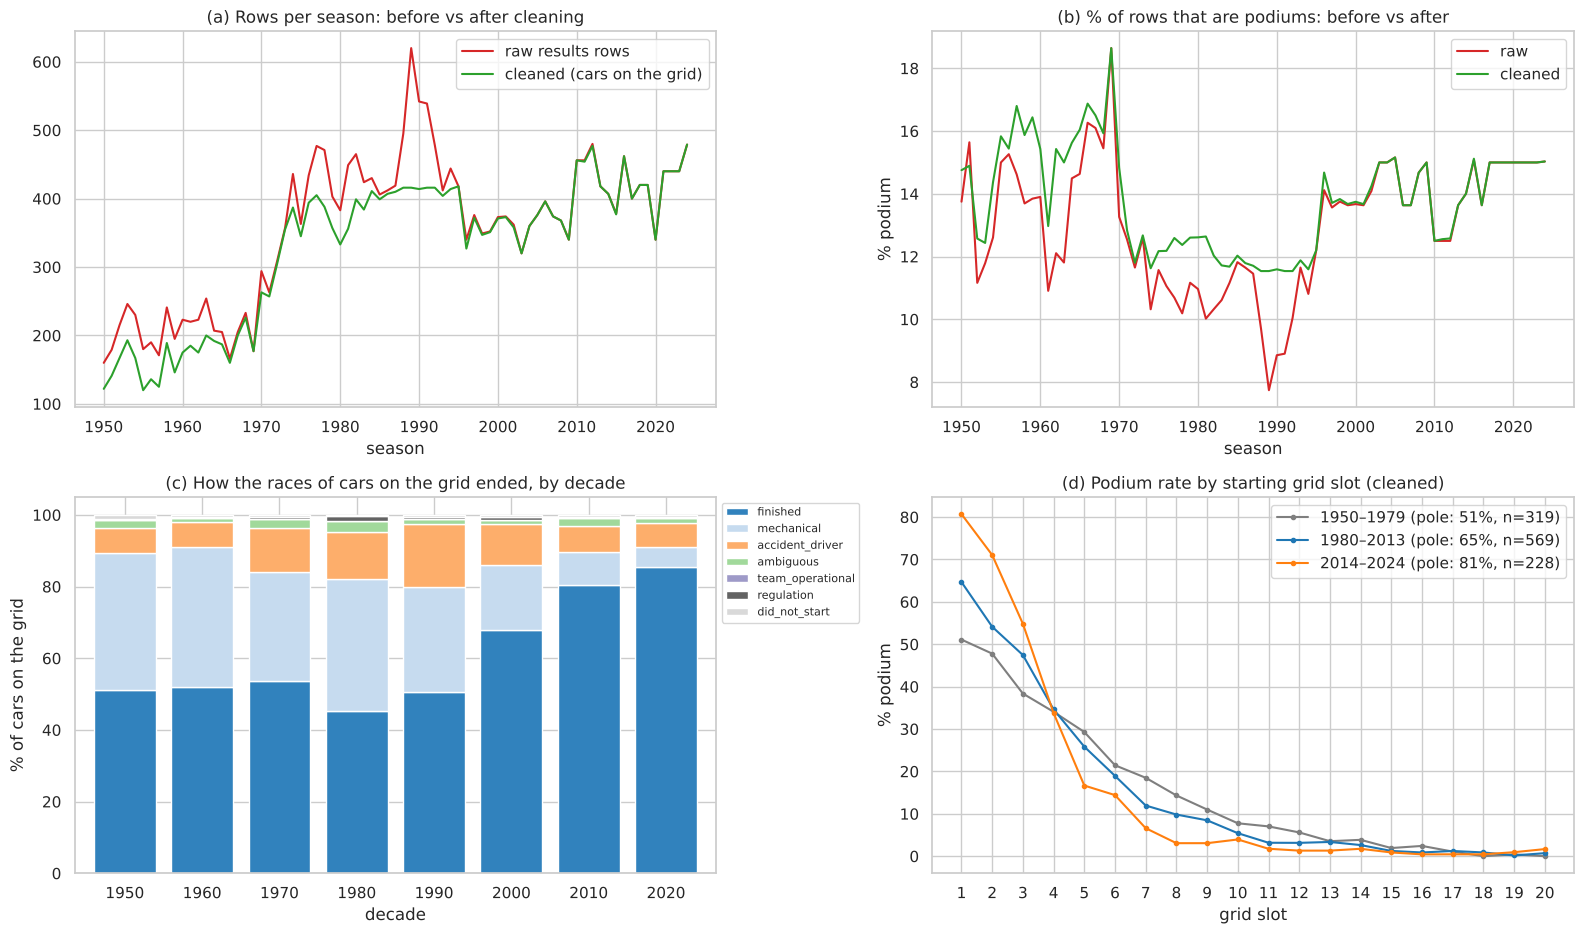

,rows,"duplicate (raceId, driverId) rows",rows with grid = 0,grid slot > number of cars,podium rate,races
raw,26759,91,1638,13,0.1269,1125
cleaned,24715,0,0,0,0.1353,1114


In [19]:
raw_rows = res_raw.assign(podium=res_raw["positionOrder"].astype(int) <= 3)

fig, axes = plt.subplots(2, 2, figsize=(16, 9.5))

# (a) rows per season
raw_rows.groupby("year").size().plot(ax=axes[0, 0], label="raw results rows", color="tab:red")
results_clean.groupby("year").size().plot(ax=axes[0, 0], label="cleaned (cars on the grid)", color="tab:green")
axes[0, 0].set_title("(a) Rows per season: before vs after cleaning"); axes[0, 0].legend(); axes[0, 0].set_xlabel("season")

# (b) target base rate per season
(raw_rows.groupby("year")["podium"].mean() * 100).plot(ax=axes[0, 1], label="raw", color="tab:red")
(results_clean.groupby("year")["podium"].mean() * 100).plot(ax=axes[0, 1], label="cleaned", color="tab:green")
axes[0, 1].set_title("(b) % of rows that are podiums: before vs after"); axes[0, 1].set_ylabel("% podium")
axes[0, 1].legend(); axes[0, 1].set_xlabel("season")

# (c) how a race ends, by decade (cleaned table): reliability changed enormously
cat_order = ["finished", "mechanical", "accident_driver", "ambiguous", "team_operational", "regulation", "did_not_start"]
cat_dec = (results_clean.assign(decade=results_clean["year"] // 10 * 10)
           .groupby("decade")["category"].value_counts(normalize=True).unstack().reindex(columns=cat_order).fillna(0) * 100)
cat_dec.plot(kind="bar", stacked=True, ax=axes[1, 0], colormap="tab20c", width=0.8)
axes[1, 0].set_title("(c) How the races of cars on the grid ended, by decade"); axes[1, 0].set_ylabel("% of cars on the grid")
axes[1, 0].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0)); axes[1, 0].tick_params(axis="x", rotation=0)

# (d) podium rate by starting slot (cleaned), split into eras, with sample sizes
for (lo, hi), col in zip([(1950, 1979), (1980, 2013), (2014, 2024)], ["tab:gray", "tab:blue", "tab:orange"]):
    sub = results_clean[results_clean["year"].between(lo, hi) & (results_clean["grid_clean"] <= 20)]
    rate = sub.groupby("grid_clean")["podium"].mean() * 100
    n_pole = int((sub["grid_clean"] == 1).sum())
    axes[1, 1].plot(rate.index, rate.values, marker="o", ms=3, color=col, label=f"{lo}–{hi} (pole: {rate.loc[1]:.0f}%, n={n_pole})")
axes[1, 1].set_xticks(range(1, 21)); axes[1, 1].set_title("(d) Podium rate by starting grid slot (cleaned)")
axes[1, 1].set_xlabel("grid slot"); axes[1, 1].set_ylabel("% podium"); axes[1, 1].legend()
save_fig("06_eda_before_after")

summary = pd.DataFrame({
    "rows": [len(raw["results"]), len(results_clean)],
    "duplicate (raceId, driverId) rows": [int(raw["results"].duplicated(["raceId", "driverId"]).sum()),
                                          int(results_clean.duplicated(["raceId", "driverId"]).sum())],
    "rows with grid = 0": [int((raw["results"]["grid"] == "0").sum()), int((results_clean["grid_clean"] == 0).sum())],
    "grid slot > number of cars": [int((res_raw["grid"].astype(int) > res_raw.groupby("raceId")["grid"].transform("size")).sum()),
                                   int((results_clean["grid_clean"] > results_clean["field_size"]).sum())],
    "podium rate": [round(raw_rows["podium"].mean(), 4), round(results_clean["podium"].mean(), 4)],
    "races": [raw["results"]["raceId"].nunique(), results_clean["raceId"].nunique()],
}, index=["raw", "cleaned"])
summary

**What this shows.**

* (a) Cleaning mostly removes rows from the 1950s and the busy late 1970s–1990s, the eras with the Indianapolis 500 and with entry lists far larger than the grid. Modern seasons are almost untouched.
* (b) Because drivers who failed to qualify can never podium, removing them raises the podium base rate in the busy eras (late 1980s: from ~8–10% to ~12%). Modern seasons stay at ~15%. The target is now about drivers who were on the grid.
* (c) Reliability changed enormously: in the 1950s–1980s around a third of the cars on the grid retired with a mechanical failure; in the 2020s most cars finish. A good grid slot therefore converted to a podium much less reliably in early decades.
* (d) Grid position is strongly predictive in every era, and its effect is **much stronger in the modern era** (pole rates and sample sizes in the legend). This motivates both the grid features and the choice of training window (D17).

**Effect of the grid recoding (D7).** The next plot shows the starting-position column before and after cleaning.

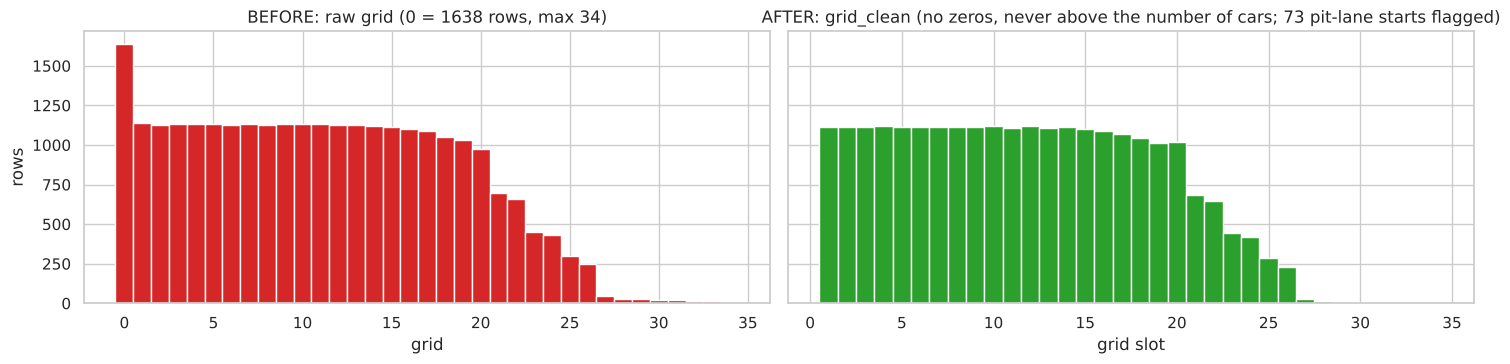

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), sharey=True)
g_raw = res_raw["grid"].astype(int)
axes[0].hist(g_raw, bins=np.arange(-0.5, g_raw.max() + 1.5), color="tab:red")
axes[0].set_title(f"BEFORE: raw grid (0 = {int((g_raw == 0).sum())} rows, max {g_raw.max()})"); axes[0].set_xlabel("grid")
axes[1].hist(results_clean["grid_clean"], bins=np.arange(0.5, results_clean["grid_clean"].max() + 1.5), color="tab:green")
axes[1].set_title(f"AFTER: grid_clean (no zeros, never above the number of cars; {int(results_clean['pit_lane_start'].sum())} pit-lane starts flagged)")
axes[1].set_xlabel("grid slot"); axes[0].set_ylabel("rows")
save_fig("06b_grid_before_after")

**What this shows.** The spike at 0 (mostly drivers who never got onto the grid) is gone, and no car has a slot behind the last car anymore. The few real pit-lane starts are now at the back of the field, with their own flag.

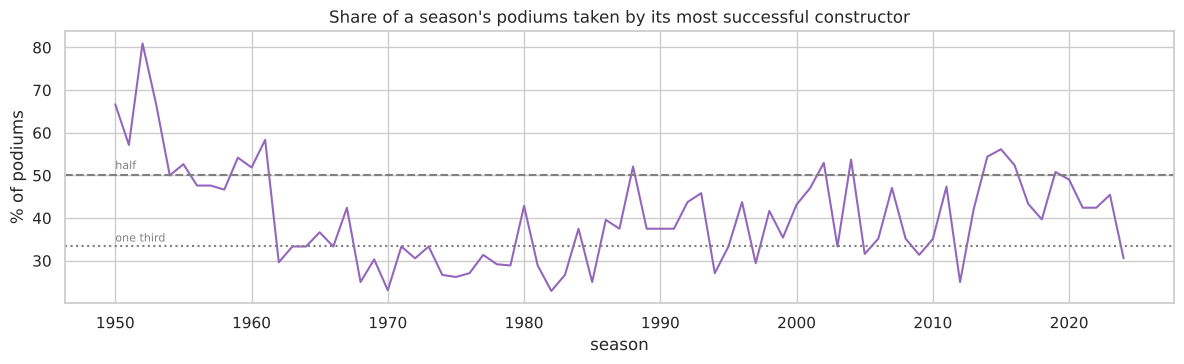

Seasons where one team took over half of all podiums: [1950, 1951, 1952, 1953, 1955, 1959, 1960, 1961, 1988, 2002, 2004, 2014, 2015, 2016, 2019]
Median share of the top team: 37.5 %


In [21]:
# Constructor dominance: in each season, what share of all podiums did the single best team take?
by_team = results_clean[results_clean["podium"] == 1].groupby(["year", "constructorId"]).size()
top_share = (by_team.groupby("year").max() / by_team.groupby("year").sum() * 100)

fig, ax = plt.subplots(figsize=(12, 3.8))
top_share.plot(ax=ax, color="tab:purple")
ax.axhline(100 / 3, ls=":", color="gray"); ax.text(1950, 34.5, "one third", color="gray", fontsize=8)
ax.axhline(50, ls="--", color="gray"); ax.text(1950, 51.5, "half", color="gray", fontsize=8)
ax.set_title("Share of a season's podiums taken by its most successful constructor")
ax.set_ylabel("% of podiums"); ax.set_xlabel("season")
save_fig("07_constructor_dominance")
print("Seasons where one team took over half of all podiums:", list(top_share[top_share > 50].index))
print("Median share of the top team:", round(top_share.median(), 1), "%")

**What this shows.** In most seasons a single constructor takes a third or more of all podiums, and in several seasons more than half. The car (built by the constructor) dominates who podiums, which is why our features include **constructor** form and standings, not only driver form.

**Grid vs qualifying per season (penalties over time).** A driver's grid slot is his qualifying position unless something moved him: a grid penalty (gearbox or engine changes, impeding, a crash in the previous race), a start from the pit lane, or, on the 2021–2022 sprint weekends, the sprint result. We count, for every season with complete qualifying data (2003–2024), how many cars that took the start had a grid slot different from their qualifying position, and why. "Moved forward" is mostly a knock-on effect: when one car is sent back, the cars behind it move up.

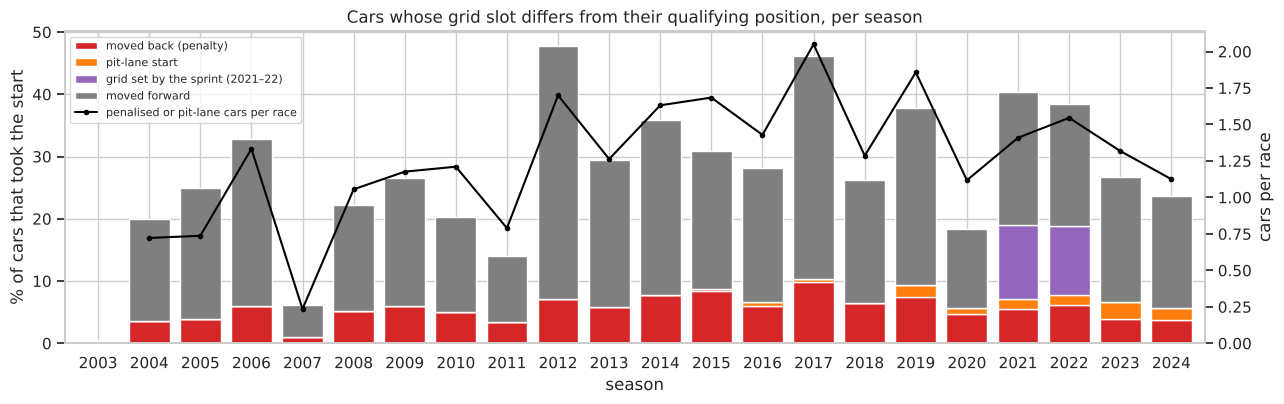

Penalised or pit-lane cars per race: {'2003–2013': 1.02, '2014–2024': 1.5}
Share of starters moved back (penalty or pit lane): {'2003–2013': 4.3, '2014–2024': 7.4} %
Seasons with the most moved-back cars per race: {2017: 2.05, 2019: 1.86, 2012: 1.7}


In [22]:
gq = results_clean[results_clean["year"].between(2003, 2024) & results_clean["started_race"]].merge(
    df["qualifying"][["raceId", "driverId", "position"]].rename(columns={"position": "quali_position"}),
    on=["raceId", "driverId"], how="inner", validate="one_to_one")
sprint_weekend = gq["raceId"].isin(set(df["sprint_results"]["raceId"])) & gq["year"].between(2021, 2022)
gq["change"] = np.select(
    [gq["grid_clean"].eq(gq["quali_position"]),
     sprint_weekend,
     gq["pit_lane_start"].eq(1),
     gq["grid_clean"] > gq["quali_position"]],
    ["grid = qualifying", "grid set by the sprint (2021–22)", "pit-lane start", "moved back (penalty)"], default="moved forward")
order = ["moved back (penalty)", "pit-lane start", "grid set by the sprint (2021–22)", "moved forward"]
share = (pd.crosstab(gq["year"], gq["change"], normalize="index") * 100).reindex(columns=order, fill_value=0)
moved_back = gq[gq["change"].isin(["moved back (penalty)", "pit-lane start"])]
per_race = (moved_back.groupby("year").size() / gq.groupby("year")["raceId"].nunique()).reindex(share.index, fill_value=0)

fig, ax = plt.subplots(figsize=(13, 4.2))
share.plot(kind="bar", stacked=True, ax=ax, width=0.8, color=["tab:red", "tab:orange", "tab:purple", "tab:gray"])
ax.set_ylabel("% of cars that took the start"); ax.set_xlabel("season"); ax.tick_params(axis="x", rotation=0)
ax.set_title("Cars whose grid slot differs from their qualifying position, per season")
ax2 = ax.twinx()
ax2.plot(range(len(per_race)), per_race.values, color="black", marker="o", ms=3, label="penalised or pit-lane cars per race")
ax2.set_ylabel("cars per race"); ax2.set_ylim(0, None); ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper left")
save_fig("07b_grid_vs_qualifying")

periods = pd.cut(per_race.index, [2002, 2013, 2024], labels=["2003–2013", "2014–2024"])
print("Penalised or pit-lane cars per race:", per_race.groupby(periods, observed=True).mean().round(2).to_dict())
print("Share of starters moved back (penalty or pit lane):",
      (share[["moved back (penalty)", "pit-lane start"]].sum(axis=1).groupby(periods, observed=True).mean().round(1)).to_dict(), "%")
print("Seasons with the most moved-back cars per race:", per_race.sort_values(ascending=False).head(3).round(2).to_dict())

**What this shows.** Grid penalties became more common in the hybrid era (from 2014). On average 1.0 car per race started behind its qualifying position (a penalty or a pit-lane start) in 2003–2013, against 1.5 in 2014–2024 (4.3% vs 7.4% of starters). The peaks are 2017 (2.05 per race) and 2019 (1.86), seasons with strict limits on how many engine parts a team may use. Each penalty pushes the cars behind forward, which is why the grey bars are large. On the 2021–2022 sprint weekends the sprint result, not qualifying, set the grid (purple, about 11–12% of starters in those seasons). The 2003 season shows no difference at all, probably because the data stores that season's grid order as its qualifying order (inferred, not checked against another source). Because grid and qualifying differ for several cars in most races, both `grid_pos` and `quali_position` are kept as features, with the difference as `grid_penalty` measured against the sprint result on sprint weekends (D15).

Save the cleaned table for later sections and for the GitHub repo.

In [23]:
results_clean.to_csv(os.path.join(OUT_DIR, "results_clean.csv"), index=False)
print("Saved", os.path.join(OUT_DIR, "results_clean.csv"))

Saved outputs/results_clean.csv


## 5. Data-engineering questions

Each answer uses joins across several tables, shows a plot, and states its **grain** (what one row means), how **missing values** were handled, and whether the **pre-race cutoff** matters.

All three questions use the cleaned driver-race table from Section 3 (`results_clean`: starters only, no Indianapolis 500, one row per driver per race). That table was itself built by joining `results` ⨝ `races` ⨝ `status` ⨝ `drivers`.

---
### 5.1 Q1. Which circuits convert a front-row start into a podium most often, and does that ranking change after 2014?

**Tables joined:** `results` ⨝ `races` ⨝ `circuits` ⨝ `qualifying` ⨝ `sprint_results`.
**Grain:** one row per driver per race; we then aggregate to one row per circuit per period.

🔶 **Decision D9 — how Q1 is measured.**
* *Front row by grid* = car in grid slot 1 or 2 (after penalties). *Front row by qualifying* = qualified 1st or 2nd. A car that was on the front row but did not take the start counts as a failed conversion.
* The two definitions differ for two reasons: **penalties**, and in **2021–2022 sprint weekends** the grid was set by the sprint, not by qualifying. We label both.
* "After the 2014 hybrid era" is read as **2014–2024 vs before 2014**. For "before" we use **2003–2013**: 2003 is the first season with complete qualifying data (Section 2.3), so both definitions use exactly the same rows and both periods span 11 seasons. A sensitivity check with the grid definition over 1950–2013 is printed too.
* Only circuits with **at least 8 front-row starts (4 races) in both periods** are ranked. Every race has 2 front-row cars, so 8 starts means the circuit hosted at least 4 races in that period. A rate from very few starts is mostly luck: with 2 starts it can only be 0%, 50% or 100%. The threshold is a judgement call between keeping more circuits and having steadier rates (8 keeps 17 circuits, 10 keeps 14); the output shows how the result moves with it.
* Because samples per circuit are small, every rate gets a **95% Wilson interval**, and we test whether circuits differ at all (chi-square) and how certain the rank correlation between periods is (bootstrap over races).

Rows 2003–2024 without a qualifying position: 22 of 8964 (best grid slot among them: 19, so none is a front-row case)
Front-row cars 2003–2024, split by how their grid slot relates to their qualifying position:


,rows,podiums,podium rate,95% CI
fr_case,,,,
qualified AND started front row,819,594,0.725,0.69–0.75
promoted to front row by others' penalties,32,20,0.625,0.45–0.77
sprint set the grid (2021–22),10,6,0.600,0.31–0.83
"qualified front row, moved back by a penalty",32,9,0.281,0.16–0.45


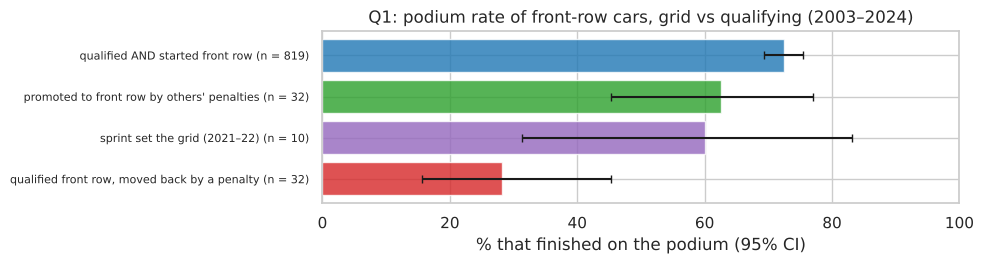


Ranking by GRID (front row = started 1st/2nd), 17 circuits:


,rate 2003–2013,CI 2003–2013,rank 2003–2013,n 2003–2013,rate 2014–2024,CI 2014–2024,rank 2014–2024,n 2014–2024
circuit,,,,,,,,
Suzuka Circuit,0.722,0.49–0.88,4,18,0.889,0.67–0.97,1,18
Sepang International Circuit,0.636,0.43–0.80,10,22,0.875,0.53–0.98,2,8
Yas Marina Circuit,0.600,0.31–0.83,13,10,0.864,0.67–0.95,3,22
Circuit de Monaco,0.773,0.57–0.90,1,22,0.850,0.64–0.95,4,20
Circuit de Spa-Francorchamps,0.722,0.49–0.88,4,18,0.818,0.61–0.93,5,22
Circuit de Barcelona-Catalunya,0.682,0.47–0.84,7,22,0.818,0.61–0.93,5,22
Shanghai International Circuit,0.650,0.43–0.82,9,20,0.786,0.52–0.92,7,14
Circuit Gilles Villeneuve,0.600,0.39–0.78,13,20,0.778,0.55–0.91,8,18
Silverstone Circuit,0.727,0.52–0.87,3,22,0.750,0.55–0.88,9,24


Circuits differ in 2003–2013?  chi-square p = 0.991
Circuits differ in 2014–2024?  chi-square p = 0.796
Pooled front-row conversion: {'2003–2013': '0.680 (n=400)', '2014–2024': '0.759 (n=456)'} | chi-square p = 0.013


Spearman ρ between periods (grid): 0.21 (p = 0.42), bootstrap 95% CI -0.40 to 0.50
Spearman ρ between periods (qualifying): 0.45 (p = 0.07), 17 circuits
Sensitivity (earlier period = 1950–2013): 21 circuits, Spearman ρ = 0.06, best before 2014: Sepang International Circuit (0.70)

Sensitivity to the minimum number of front-row starts (grid definition):


minimum starts,4,6,8,10,12,16
circuits ranked,19.00,17.00,17.00,14.00,13.00,11.00
Spearman ρ,0.08,0.21,0.21,0.35,0.49,0.42


Autodromo Nazionale di Monza: 2003–2013: 17 of 22 (77%, rank 1 of 17) | 2014–2024: 16 of 22 (73%, rank 12 of 17)
Yas Marina Circuit: 2003–2013: 6 of 10 (60%, rank 13 of 17) | 2014–2024: 19 of 22 (86%, rank 3 of 17)
Range of circuit rates: 58% to 89%

Ranking by QUALIFYING (front row = qualified 1st/2nd), 17 circuits:


,rate 2003–2013,CI 2003–2013,rank 2003–2013,n 2003–2013,rate 2014–2024,CI 2014–2024,rank 2014–2024,n 2014–2024
circuit,,,,,,,,
Suzuka Circuit,0.722,0.49–0.88,3,18,0.889,0.67–0.97,1,18
Circuit de Monaco,0.682,0.47–0.84,7,22,0.850,0.64–0.95,2,20
Yas Marina Circuit,0.600,0.31–0.83,12,10,0.818,0.61–0.93,3,22
Circuit de Spa-Francorchamps,0.722,0.49–0.88,3,18,0.818,0.61–0.93,3,22
Circuit de Barcelona-Catalunya,0.636,0.43–0.80,9,22,0.818,0.61–0.93,3,22
Shanghai International Circuit,0.700,0.48–0.85,6,20,0.786,0.52–0.92,6,14
Sepang International Circuit,0.636,0.43–0.80,9,22,0.750,0.41–0.93,7,8
Silverstone Circuit,0.773,0.57–0.90,1,22,0.750,0.55–0.88,7,24
Autodromo Nazionale di Monza,0.727,0.52–0.87,2,22,0.727,0.52–0.87,9,22


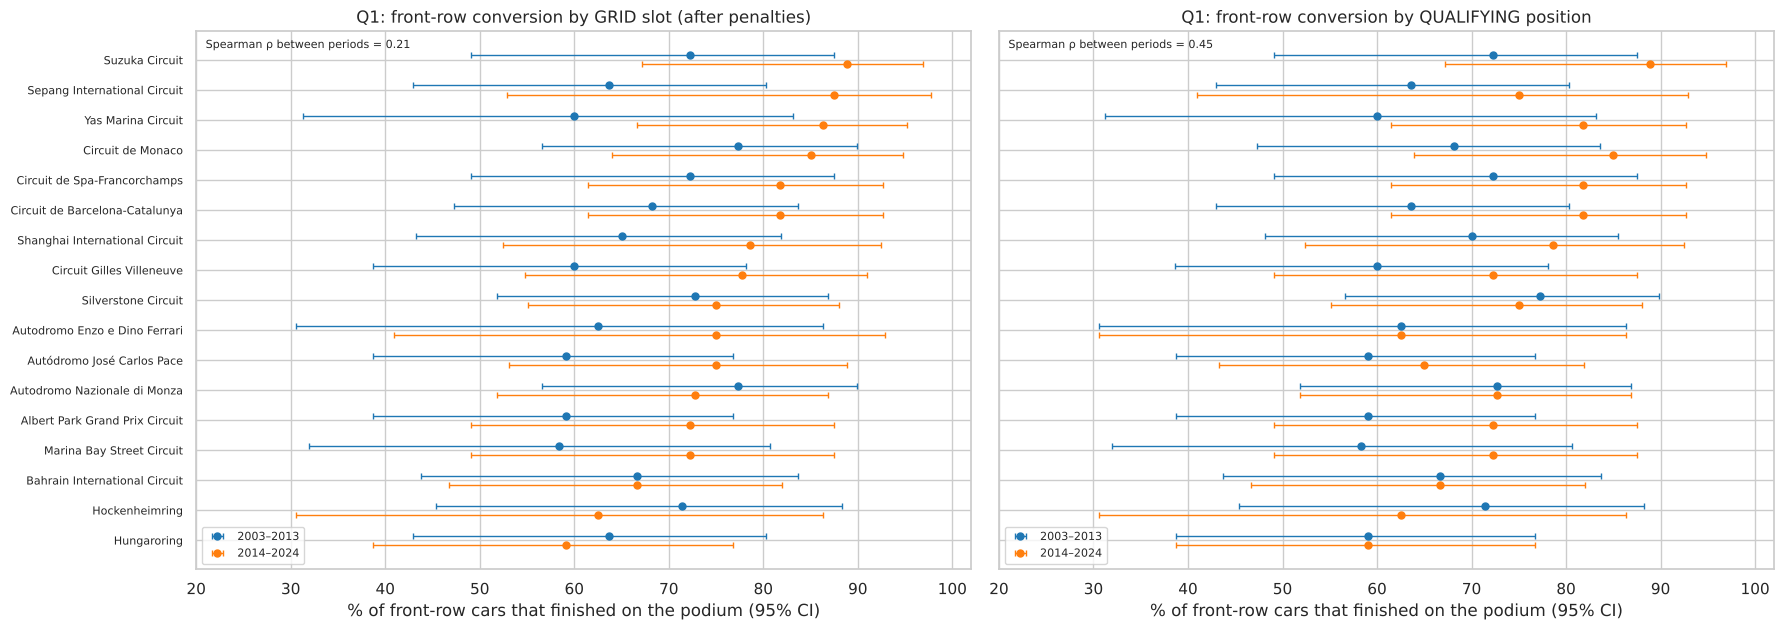

In [24]:
from scipy.stats import chi2_contingency, spearmanr

def wilson(k, n, z=1.96):
    """95% Wilson confidence interval for a proportion k/n (works well for small n and rates near 0 or 1)."""
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n; den = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centre - half, centre + half

# Join chain: cleaned results -> races (circuit) -> circuits (name) -> qualifying (position) -> sprint_results (sprint weekends).
quali_pos = df["qualifying"][["raceId", "driverId", "position"]].rename(columns={"position": "quali_position"})
sprint_races = set(df["sprint_results"]["raceId"])
q1_all = (results_clean
          .merge(df["races"][["raceId", "circuitId"]], on="raceId", how="left")
          .merge(df["circuits"][["circuitId", "name"]].rename(columns={"name": "circuit", "circuitId": "cid"}), left_on="circuitId", right_on="cid", how="left")
          .merge(quali_pos, on=["raceId", "driverId"], how="left"))      # left join: rows without qualifying keep NaN
# Grid set by the sprint (2021–2022 sprint weekends) rather than by qualifying:
q1_all["sprint_grid"] = q1_all["raceId"].isin(sprint_races) & q1_all["year"].between(2021, 2022)
q1_all["front_row_grid"] = (q1_all["grid_clean"] <= 2) & (q1_all["pit_lane_start"] == 0)
q1_all["front_row_quali"] = q1_all["quali_position"] <= 2

# DECISION D9 → see DECISIONS.md  (definitions, periods, minimum sample, uncertainty)
q1 = q1_all[q1_all["year"].between(2003, 2024)].copy()
q1["period"] = np.where(q1["year"] <= 2013, "2003–2013", "2014–2024")
miss = q1[q1["quali_position"].isna()]
print(f"Rows 2003–2024 without a qualifying position: {len(miss)} of {len(q1)} "
      f"(best grid slot among them: {int(miss['grid_clean'].min())}, so none is a front-row case)")

# How often do the two definitions disagree, and what does it do to podium conversion?
q1["fr_case"] = np.select(
    [q1["front_row_grid"] & q1["front_row_quali"],
     q1["front_row_quali"] & ~q1["front_row_grid"] & ~q1["sprint_grid"],
     q1["front_row_grid"] & ~q1["front_row_quali"] & ~q1["sprint_grid"],
     (q1["front_row_grid"] ^ q1["front_row_quali"]) & q1["sprint_grid"]],
    ["qualified AND started front row", "qualified front row, moved back by a penalty",
     "promoted to front row by others' penalties", "sprint set the grid (2021–22)"],
    default="neither")
cases = q1[q1["fr_case"] != "neither"].groupby("fr_case")["podium"].agg(rows="size", podiums="sum")
cases["podium rate"] = cases["podiums"] / cases["rows"]
cases["95% CI"] = [f"{lo:.2f}–{hi:.2f}" for lo, hi in zip(*wilson(cases["podiums"], cases["rows"]))]
order_cases = ["qualified AND started front row", "promoted to front row by others' penalties",
               "sprint set the grid (2021–22)", "qualified front row, moved back by a penalty"]
cases = cases.reindex(order_cases)
print("Front-row cars 2003–2024, split by how their grid slot relates to their qualifying position:")
display(cases.round(3))
lo, hi = wilson(cases["podiums"], cases["rows"])
fig, ax = plt.subplots(figsize=(10, 2.8))
yy = np.arange(len(cases))[::-1]
ax.barh(yy, cases["podium rate"] * 100, color=["tab:blue", "tab:green", "tab:purple", "tab:red"], alpha=0.8,
        xerr=[(cases["podium rate"] - lo) * 100, (hi - cases["podium rate"]) * 100], capsize=3)
ax.set_yticks(yy); ax.set_yticklabels([f"{c} (n = {n})" for c, n in zip(cases.index, cases["rows"])], fontsize=8)
ax.set_xlabel("% that finished on the podium (95% CI)"); ax.set_xlim(0, 100)
ax.set_title("Q1: podium rate of front-row cars, grid vs qualifying (2003–2024)")
save_fig("08a_q1_grid_vs_quali_cases")

def conversion(data, flag):
    """Front-row starts, podiums and podium rate per circuit and period."""
    t = data[data[flag]].groupby(["circuit", "period"])["podium"].agg(starts="size", podiums="sum").unstack("period")
    return t

MIN_STARTS = 8                                    # D9: at least 4 races (2 front-row cars each) per period
PERIODS = ["2003–2013", "2014–2024"]

def ranking(flag):
    t = conversion(q1, flag)
    t = t[(t["starts"] >= MIN_STARTS).all(axis=1)]
    out = pd.DataFrame(index=t.index)
    for p in PERIODS:
        out[f"rate {p}"] = t[("podiums", p)] / t[("starts", p)]
        lo, hi = wilson(t[("podiums", p)], t[("starts", p)])
        out[f"CI {p}"] = [f"{a:.2f}–{b:.2f}" for a, b in zip(lo, hi)]
        out[f"rank {p}"] = out[f"rate {p}"].rank(ascending=False, method="min").astype(int)
        out[f"n {p}"] = t[("starts", p)].astype(int)
    return out.sort_values("rate 2014–2024", ascending=False), t

rank_grid, counts_grid = ranking("front_row_grid")
rank_quali, counts_quali = ranking("front_row_quali")
print(f"\nRanking by GRID (front row = started 1st/2nd), {len(rank_grid)} circuits:")
display(rank_grid.round(3))

# 1) Do circuits differ at all? Chi-square test of circuit × podium within each period.
for p in PERIODS:
    tab = np.c_[counts_grid[("podiums", p)], counts_grid[("starts", p)] - counts_grid[("podiums", p)]]
    print(f"Circuits differ in {p}?  chi-square p = {chi2_contingency(tab)[1]:.3f}")
# 2) Did conversion rise overall after 2014? (all front-row starts, all circuits)
pooled = q1[q1["front_row_grid"]].groupby("period")["podium"].agg(["sum", "size"])
print("Pooled front-row conversion:", {p: f"{r['sum'] / r['size']:.3f} (n={int(r['size'])})" for p, r in pooled.iterrows()},
      f"| chi-square p = {chi2_contingency(np.c_[pooled['sum'], pooled['size'] - pooled['sum']])[1]:.3f}")
# 3) How stable is the ranking? Spearman between periods + bootstrap interval (resample races within circuit and period).
def rho_of(rank_df):
    return spearmanr(rank_df["rate 2003–2013"], rank_df["rate 2014–2024"])
rho, rho_p = rho_of(rank_grid)
rho_q, rho_q_p = rho_of(rank_quali)
rng = np.random.default_rng(SEED)
fr = q1[q1["front_row_grid"] & q1["circuit"].isin(rank_grid.index)]
race_pod = fr.groupby(["circuit", "period", "raceId"])["podium"].agg(["sum", "size"])
boot_rho = []
for _ in range(1000):
    rates = {}
    for (c, p), g in race_pod.groupby(level=[0, 1]):
        pick = g.iloc[rng.integers(0, len(g), len(g))]
        rates[(c, p)] = pick["sum"].sum() / pick["size"].sum()
    r = pd.Series(rates).unstack()
    boot_rho.append(spearmanr(r[PERIODS[0]], r[PERIODS[1]])[0])
print(f"Spearman ρ between periods (grid): {rho:.2f} (p = {rho_p:.2f}), bootstrap 95% CI "
      f"{np.nanpercentile(boot_rho, 2.5):.2f} to {np.nanpercentile(boot_rho, 97.5):.2f}")
print(f"Spearman ρ between periods (qualifying): {rho_q:.2f} (p = {rho_q_p:.2f}), {len(rank_quali)} circuits")
# 4) Sensitivity: grid definition with ALL seasons before 2014 (1950–2013) as the earlier period.
q1_long = q1_all.assign(period=np.where(q1_all["year"] <= 2013, "1950–2013", "2014–2024"))
t_long = q1_long[q1_long["front_row_grid"]].groupby(["circuit", "period"])["podium"].agg(["sum", "size"]).unstack("period")
t_long = t_long[(t_long["size"] >= MIN_STARTS).all(axis=1)]
r_long = (t_long["sum"] / t_long["size"])
print(f"Sensitivity (earlier period = 1950–2013): {len(r_long)} circuits, Spearman ρ = {spearmanr(r_long.iloc[:, 0], r_long.iloc[:, 1])[0]:.2f}, "
      f"best before 2014: {r_long.iloc[:, 0].idxmax()} ({r_long.iloc[:, 0].max():.2f})")

# 5) Sensitivity to the minimum number of front-row starts: circuits ranked and rank correlation between periods.
sens = []
for m in [4, 6, 8, 10, 12, 16]:
    t_m = conversion(q1, "front_row_grid")
    t_m = t_m[(t_m["starts"] >= m).all(axis=1)]
    r_m = t_m["podiums"] / t_m["starts"]
    sens.append({"minimum starts": m, "circuits ranked": len(t_m), "Spearman ρ": round(spearmanr(r_m[PERIODS[0]], r_m[PERIODS[1]])[0], 2)})
print("\nSensitivity to the minimum number of front-row starts (grid definition):")
display(pd.DataFrame(sens).set_index("minimum starts").T)
# 6) Reading a rank change: two examples in podiums out of front-row starts.
for c in ["Autodromo Nazionale di Monza", "Yas Marina Circuit"]:
    print(f"{c}: " + " | ".join(
        f"{p}: {int(counts_grid.loc[c, ('podiums', p)])} of {int(counts_grid.loc[c, ('starts', p)])} "
        f"({rank_grid.loc[c, f'rate {p}']:.0%}, rank {rank_grid.loc[c, f'rank {p}']} of {len(rank_grid)})" for p in PERIODS))
print(f"Range of circuit rates: {rank_grid[[f'rate {p}' for p in PERIODS]].min().min():.0%} to {rank_grid[[f'rate {p}' for p in PERIODS]].max().max():.0%}")

print(f"\nRanking by QUALIFYING (front row = qualified 1st/2nd), {len(rank_quali)} circuits:")
display(rank_quali.round(3))

# Figure: left = grid definition with 95% intervals; right = qualifying definition, same circuit order.
order = rank_grid.index
fig, axes = plt.subplots(1, 2, figsize=(18, max(5.5, 0.38 * len(order))), sharey=True)
for ax, (rk, cnt, title) in zip(axes, [(rank_grid, counts_grid, "by GRID slot (after penalties)"),
                                         (rank_quali.reindex(order), counts_quali.reindex(order), "by QUALIFYING position")]):
    y = np.arange(len(order))[::-1]
    for p, col, off in [("2003–2013", "tab:blue", 0.15), ("2014–2024", "tab:orange", -0.15)]:
        k, n = cnt[("podiums", p)].reindex(order), cnt[("starts", p)].reindex(order)
        rate = k / n; lo, hi = wilson(k, n)
        ax.errorbar(rate * 100, y + off, xerr=[(rate - lo) * 100, (hi - rate) * 100], fmt="o", color=col, ms=5,
                    capsize=2, lw=1, label=p)
    ax.set_yticks(np.arange(len(order))[::-1]); ax.set_yticklabels(order, fontsize=8)
    ax.set_xlabel("% of front-row cars that finished on the podium (95% CI)"); ax.set_title(f"Q1: front-row conversion {title}")
    ax.set_xlim(20, 102); ax.legend(loc="lower left", fontsize=8)
axes[0].text(21, len(order) - 0.6, f"Spearman ρ between periods = {rho:.2f}", fontsize=8)
axes[1].text(21, len(order) - 0.6, f"Spearman ρ between periods = {rho_q:.2f}", fontsize=8)
save_fig("08_q1_front_row")

**How to read the numbers in this section**

* **rate**: podiums ÷ front-row starts at that circuit in that period (0.72 = 72% of the front-row cars finished on the podium).
* **n**: how many front-row starts the rate is based on. The smaller n, the less reliable the rate.
* **95% CI** (confidence interval, Wilson method): the range the true rate probably lies in. It is wide when n is small. When two circuits' intervals overlap a lot, we cannot say that one really converts better than the other.
* **rank**: the circuit's place when all circuits are sorted by rate (1 = best; equal rates share a rank).
* **Chi-square test and its p-value**: asks "do all circuits have the same conversion rate, and are the differences between them just luck?" The p-value is the chance of seeing differences at least this large by luck alone. Below 0.05 we call a difference real; above it, luck explains it. The same test on the two periods' overall rates checks whether the rise after 2014 is real.
* **Spearman ρ** (rank correlation): do the circuits keep the same order in both periods? +1 = same order, 0 = the two orders are unrelated, −1 = reversed order. Its bootstrap 95% interval shows how sure we are: if it includes 0, we cannot claim the order carries over from one period to the next.

**Answer to Q1** *(numbers from the output above)*

* **Overall, front-row starts convert more often after 2014:** 68.0% of front-row cars finished on the podium in 2003–2013 (n = 400) against 75.9% in 2014–2024 (n = 456). This rise is statistically significant (chi-square p = 0.013).
* **Which circuits convert best (grid definition):** in 2014–2024 Suzuka (89%), Sepang (88%, only 8 starts), Yas Marina (86%) and Monaco (85%); in 2003–2013 Monaco and Monza (both 77%) and Silverstone (73%). The Hungaroring is last after 2014 (59%).
* **Does the ranking change? It appears to, but we cannot show that it really does.** Some circuits move a lot (Monza from joint 1st to 12th, Yas Marina from 13th to 3rd), and the rank correlation between the two periods is weak (Spearman ρ = 0.21). But each circuit has only 8–24 front-row starts per period, so every rate has a 95% interval between about 30 and 55 points wide; the circuits are **not statistically distinguishable from each other in either period** (chi-square p = 0.99 and 0.80), and the bootstrap interval for ρ (−0.40 to 0.50) includes both "no relation" and "similar order". Ranked by qualifying position instead, ρ is higher (0.45) but still not significant (p = 0.07): the two definitions count a few different cars as front-row starters (penalties, sprint weekends), and with so few starts per circuit that is enough to move several ranks. The robust conclusion is the overall rise; a circuit-level reordering is not supported by this much data. With all seasons before 2014 as the earlier period the correlation is even lower (ρ = 0.06), so the "before" ranking itself depends on the era chosen.
* **How to read a rank change such as "Monza from joint 1st to 12th".** Each period ranks the circuits by their conversion rate. In 2003–2013, 17 of Monza's 22 front-row cars finished on the podium (77%), tied with Monaco for the best rate, so Monza was joint 1st. In 2014–2024, 16 of 22 did (73%) and 11 circuits did better, so it was 12th. Monza fell 11 places because of **one podium fewer**: all circuits sit between 58% and 89%, so a single result reorders the list. Yas Marina went from 6 of 10 (60%, 13th) to 19 of 22 (86%, 3rd). The ranking also depends on the minimum number of starts: the rank correlation is 0.21 with at least 8 starts, 0.35 with 10 and 0.49 with 12 (printed above). That instability is one more sign that the circuit order is not solid.
* **Qualifying vs grid matters** (first table and bar chart in the output above). Drivers who *qualified and started* on the front row podiumed **72.5%** of the time (n = 819). Front-row qualifiers **moved back by a penalty** podiumed only **28.1%** (n = 32); drivers **promoted** to the front row by others' penalties **62.5%** (n = 32); on 2021–22 sprint weekends, where the sprint set the grid, 60% (n = 10). Ranked by qualifying position instead of grid ("Ranking by QUALIFYING" table above), Monaco drops from 1st to 7th before 2014 (68%), because several front-row qualifiers there started further back. The grid (after penalties) is therefore the better measure of a driver's real starting chance; it is our main starting-position feature, and the change from qualifying to grid is kept as its own feature (D15).

**Grain / missingness / cutoff.** One row per driver-race, aggregated per circuit and period. The few 2003–2024 rows without a qualifying position all started near the back (printed above), so they can never be front-row cases; they are kept, not imputed. Grid, qualifying and the sprint result are all known before the race, so this analysis uses nothing a pre-race model could not use.

---
### 5.2 Q2. Do drivers podium more often at their home race, after controlling for starting position?

**Tables joined:** `results` ⨝ `races` ⨝ `circuits` (country) ⨝ `drivers` (nationality).
**Grain:** one row per driver per race.

🔶 **Decision D10 — how Q2 is measured.**
* *Home race* = the driver's nationality maps to the **country the circuit is in**. Nationalities are adjectives ("British") and countries are names ("UK"), so we write the mapping explicitly (below). Conventions: the circuit's location decides, not the race's name (a German at the "European GP" held at the Nürburgring is at home); East German drivers map to Germany; a driver with two nationalities (American-Italian, Argentine-Italian) is at home in **either** country. Drivers whose nationality has no circuit (e.g. Finnish) never have a home race.
* *Controlling for starting position*: we compare home and away drivers **within the same stratum** of grid bucket (1 / 2–3 / 4–6 / 7–10 / 11+) × era (1950–1979 / 1980–2013 / 2014–2024), then average the within-stratum differences, weighted by how many home starts each stratum has. Era is added because podium rates per grid slot differ by era (Section 4). The grid-only version is shown too, so the effect of adding era is visible.
* Uncertainty: 95% bootstrap intervals from 1,000 resamples of whole **races** (rows from one race are not independent).
* Robustness checks: a **logistic regression** `podium ~ home + grid slot + era` with standard errors clustered by race; the estimate for the **front of the grid only** (grid ≤ 10, where podiums actually happen); and the estimate for the **modern era only** (2014–2024).

Nationalities with no circuit country (never at home): ['Chilean', 'Colombian', 'Czech', 'Danish', 'Finnish', 'Indonesian', 'Irish', 'Liechtensteiner', 'New Zealander', 'Polish', 'Rhodesian', 'Thai', 'Uruguayan', 'Venezuelan']
Circuit countries with no driver nationality mapped to them: ['Azerbaijan', 'Bahrain', 'Korea', 'Morocco', 'Qatar', 'Saudi Arabia', 'Singapore', 'Turkey', 'UAE']
Starts by drivers with two nationalities: {('American-Italian', 'Italy'): {'starts': 1, 'home': 1}, ('Argentine-Italian', 'Argentina'): {'starts': 1, 'home': 1}, ('Argentine-Italian', 'USA'): {'starts': 1, 'home': 0}}
Home starts: 1944 of 24715 driver-race rows


,home − away (pp),95% CI low,95% CI high,home starts
estimate,,,,
raw (no control),-2.12,-3.65,-0.66,1944
controlled: grid bucket,-0.60,-1.83,0.55,1944
controlled: grid bucket × era (main),-0.83,-2.09,0.34,1944
front of grid only (grid ≤ 10),-0.68,-3.57,2.02,794
modern era only (2014–2024),-1.58,-5.90,2.79,145


Logistic regression (clustered by race): odds ratio for home = 0.93 (95% CI 0.79–1.11), p = 0.43
Share of starts by drivers with ≤ 5 career starts — home: 13.1%, away: 1.4%


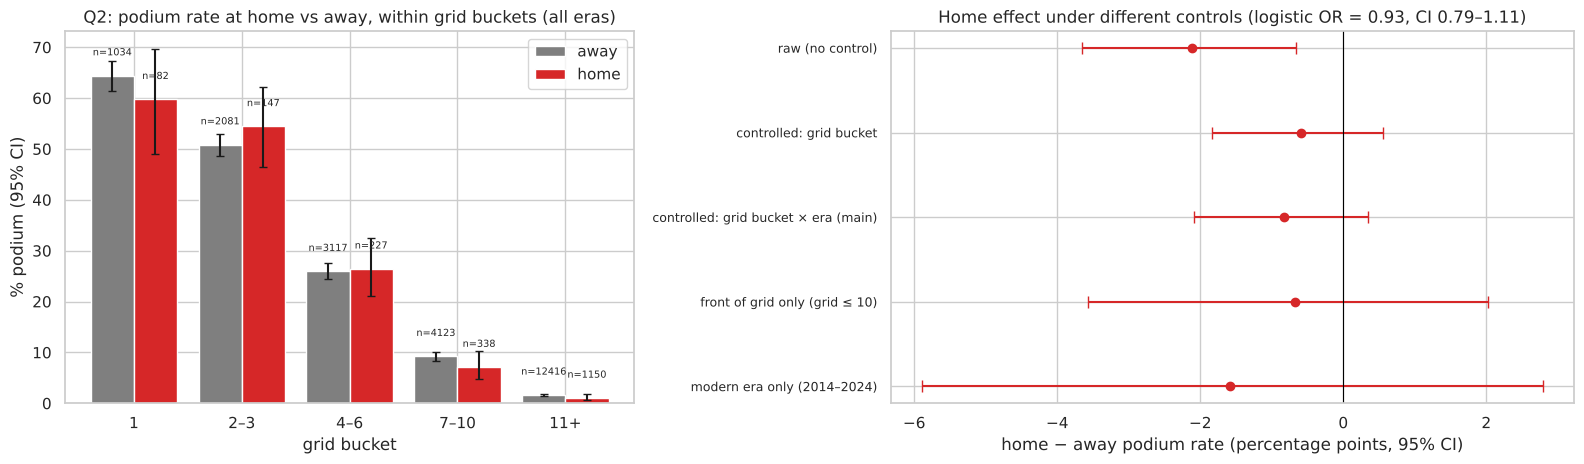

In [25]:
import statsmodels.formula.api as smf

# DECISION D10 → see DECISIONS.md  (nationality -> country mapping, strata, bootstrap, robustness)
NAT_TO_COUNTRY = {
    "American": "USA", "American-Italian": ["USA", "Italy"], "Argentine": "Argentina", "Argentine-Italian": ["Argentina", "Italy"],
    "Australian": "Australia", "Austrian": "Austria", "Belgian": "Belgium", "Brazilian": "Brazil",
    "British": "UK", "Canadian": "Canada", "Chinese": "China", "Dutch": "Netherlands",
    "East German": "Germany", "French": "France", "German": "Germany", "Hungarian": "Hungary",
    "Indian": "India", "Italian": "Italy", "Japanese": "Japan", "Malaysian": "Malaysia",
    "Mexican": "Mexico", "Monegasque": "Monaco", "Portuguese": "Portugal", "Russian": "Russia",
    "South African": "South Africa", "Spanish": "Spain", "Swedish": "Sweden", "Swiss": "Switzerland",
}
q2 = (results_clean
      .merge(df["races"][["raceId", "circuitId"]], on="raceId", how="left")
      .merge(df["circuits"][["circuitId", "country"]], on="circuitId", how="left")
      .merge(df["drivers"][["driverId", "nationality"]], on="driverId", how="left"))
def home_flag(nationality, country):
    """1 if the circuit's country is one of the driver's countries (a dual nationality counts both), else 0."""
    countries = nationality.map(lambda n: NAT_TO_COUNTRY.get(n, []))
    countries = countries.map(lambda v: v if isinstance(v, list) else [v])
    return np.array([c in cs for cs, c in zip(countries, country)], dtype=int)

# Home race = the country the circuit is in is (one of) the driver's countries, from his nationality.
q2["home"] = home_flag(q2["nationality"], q2["country"])
all_countries = {c for v in NAT_TO_COUNTRY.values() for c in (v if isinstance(v, list) else [v])}
print("Nationalities with no circuit country (never at home):", sorted(set(q2["nationality"]) - set(NAT_TO_COUNTRY)))
print("Circuit countries with no driver nationality mapped to them:", sorted(set(q2["country"]) - all_countries))
dual = q2[q2["nationality"].map(lambda n: isinstance(NAT_TO_COUNTRY.get(n), list))]
print("Starts by drivers with two nationalities:", dual.groupby(["nationality", "country"]).agg(starts=("home", "size"), home=("home", "sum")).to_dict("index"))
print(f"Home starts: {int(q2['home'].sum())} of {len(q2)} driver-race rows")

# Strata for the control: compare home vs away only between drivers who started in a similar place, in the same era.
q2["grid_bucket"] = pd.cut(q2["grid_clean"], [0, 1, 3, 6, 10, 99], labels=["1", "2–3", "4–6", "7–10", "11+"])
q2["era"] = pd.cut(q2["year"], [1949, 1979, 2013, 2024], labels=["1950–1979", "1980–2013", "2014–2024"])

def stratified_effect(d, strata):
    """Within-stratum podium-rate difference (home − away), weighted by home starts per stratum."""
    g = d.groupby(strata + ["home"], observed=True)["podium"].agg(["sum", "size"]).unstack("home").dropna()
    rate_h, rate_a, w = g[("sum", 1)] / g[("size", 1)], g[("sum", 0)] / g[("size", 0)], g[("size", 1)]
    return float(((rate_h - rate_a) * w).sum() / w.sum())

def bootstrap(d, strata, n_boot=1000):
    """Cluster bootstrap over races, done with matrices so 1,000 resamples run in seconds."""
    cell = d.groupby(["raceId"] + strata + ["home"], observed=True)["podium"].agg(["sum", "size"])
    S = cell["sum"].unstack(strata + ["home"], fill_value=0)       # races × (stratum, home) podium counts
    N = cell["size"].unstack(strata + ["home"], fill_value=0)       # races × (stratum, home) row counts
    rng = np.random.default_rng(SEED)
    out = []
    for _ in range(n_boot):
        w = rng.multinomial(len(S), np.full(len(S), 1 / len(S)))   # how often each race is drawn
        s_, n_ = pd.Series(w @ S.values, index=S.columns), pd.Series(w @ N.values, index=N.columns)
        g = pd.DataFrame({"s": s_, "n": n_}).unstack("home").dropna()
        g = g[(g[("n", 0)] > 0) & (g[("n", 1)] > 0)]
        diff = g[("s", 1)] / g[("n", 1)] - g[("s", 0)] / g[("n", 0)]
        out.append(float((diff * g[("n", 1)]).sum() / g[("n", 1)].sum()))
    return np.percentile(out, [2.5, 97.5])

GE = ["grid_bucket", "era"]
estimates = []
for label, data, strata in [("raw (no control)", q2.assign(all="all"), ["all"]),
                            ("controlled: grid bucket", q2, ["grid_bucket"]),
                            ("controlled: grid bucket × era (main)", q2, GE),
                            ("front of grid only (grid ≤ 10)", q2[q2["grid_clean"] <= 10], GE),
                            ("modern era only (2014–2024)", q2[q2["year"] >= 2014], GE)]:
    lo, hi = bootstrap(data, strata)
    estimates.append({"estimate": label, "home − away (pp)": 100 * stratified_effect(data, strata),
                      "95% CI low": 100 * lo, "95% CI high": 100 * hi, "home starts": int(data["home"].sum())})
estimates = pd.DataFrame(estimates).set_index("estimate")
display(estimates.round(2))

# Logistic regression check: odds ratio of a podium at home, holding grid slot (1..20, 21+) and era fixed.
q2["grid_cat"] = q2["grid_clean"].clip(upper=21)
logit = smf.logit("podium ~ home + C(grid_cat) + C(era)", data=q2).fit(disp=0, cov_type="cluster", cov_kwds={"groups": q2["raceId"]})
or_, (or_lo, or_hi) = np.exp(logit.params["home"]), np.exp(logit.conf_int().loc["home"])
print(f"Logistic regression (clustered by race): odds ratio for home = {or_:.2f} (95% CI {or_lo:.2f}–{or_hi:.2f}), p = {logit.pvalues['home']:.2f}")

# Evidence for the "one-off local drivers" explanation of the raw gap
career = results_clean.groupby("driverId").size()
q2["career_starts"] = q2["driverId"].map(career)
print("Share of starts by drivers with ≤ 5 career starts — home: "
      f"{(q2.loc[q2['home'] == 1, 'career_starts'] <= 5).mean():.1%}, away: {(q2.loc[q2['home'] == 0, 'career_starts'] <= 5).mean():.1%}")

strat = q2.groupby(["grid_bucket", "home"], observed=True)["podium"].agg(["sum", "size"]).unstack("home")
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 1.2]})
x = np.arange(len(strat))
for h, col, off, lab in [(0, "tab:gray", -0.2, "away"), (1, "tab:red", 0.2, "home")]:
    k, n = strat[("sum", h)], strat[("size", h)]
    lo, hi = wilson(k, n)
    axes[0].bar(x + off, k / n * 100, 0.4, color=col, label=lab, yerr=[(k / n - lo) * 100, (hi - k / n) * 100], capsize=3)
    for xi, (kk, nn) in enumerate(zip(k, n)):
        axes[0].text(xi + off, (kk / nn) * 100 + 4, f"n={int(nn)}", ha="center", fontsize=7)
axes[0].set_xticks(x); axes[0].set_xticklabels(strat.index)
axes[0].set_xlabel("grid bucket"); axes[0].set_ylabel("% podium (95% CI)"); axes[0].legend()
axes[0].set_title("Q2: podium rate at home vs away, within grid buckets (all eras)")
e = estimates.iloc[::-1]
axes[1].errorbar(e["home − away (pp)"], np.arange(len(e)), xerr=[e["home − away (pp)"] - e["95% CI low"], e["95% CI high"] - e["home − away (pp)"]],
                 fmt="o", color="tab:red", capsize=4)
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_yticks(np.arange(len(e))); axes[1].set_yticklabels(e.index, fontsize=9)
axes[1].set_xlabel("home − away podium rate (percentage points, 95% CI)")
axes[1].set_title(f"Home effect under different controls (logistic OR = {or_:.2f}, CI {or_lo:.2f}–{or_hi:.2f})")
save_fig("09_q2_home")

**How to read the numbers in this section**

* **home − away (pp)**: the podium rate at home minus the podium rate away, in **percentage points** (pp). Example: if home drivers podium 12% of the time and away drivers 14%, home − away = 12 − 14 = **−2 pp**. Negative = drivers do *worse* at home, positive = better, 0 = no difference. We say "percentage points" and not "%" because it is a difference between two percentages (12% → 14% is 2 points, not 2%).
* **Grid bucket** (x-axis of the left plot): groups of **starting-grid slots**, not eras. **1** = started from pole position (1st on the grid); **2–3** = started 2nd or 3rd; **4–6** = 4th to 6th; **7–10** = 7th to 10th; **11+** = 11th or further back. The left plot pools all eras: for each grid bucket it compares the podium rate of drivers at home (red) and away (gray); *n* is the number of starts behind each bar.
* **Era**: a separate split by season: **1950–1979**, **1980–2013**, **2014–2024**. It is needed because the chance of a podium from a given grid slot changed over time (Section 4).
* **Stratum (group)**: one grid bucket in one era, e.g. "started 2nd–3rd in 1980–2013". There are 5 × 3 = 15 groups. Comparing home vs away *inside* a group means we compare drivers who started in a similar place in the same era, so a home driver who started from the back is not compared with an away driver who started on pole.
* **Controlled estimate**: home − away is computed inside each group, then averaged across groups, giving each group a weight equal to its number of home starts (groups with more home races count more).
* **Raw estimate**: home − away over all rows, without groups.
* **95% CI** (bootstrap): we redraw the races at random 1,000 times, recompute the estimate each time, and keep the middle 95% of the results. If the interval includes 0, we cannot claim a home effect.
* **Odds ratio** (logistic regression): another way to measure the same thing. 1 = no home effect, above 1 = more podiums at home, below 1 = fewer. If its interval includes 1 (and p > 0.05), there is no evidence of an effect.

**Answer to Q2** *(numbers from the output above)*

* **Raw comparison:** home drivers podium **2.1 percentage points less** often than away drivers (95% CI −3.65 to −0.66). This is a composition effect: 13.1% of home starts come from drivers with five or fewer career starts (one-off local entrants in uncompetitive cars), against 1.4% of away starts.
* **Controlled for starting position:** comparing home and away drivers from the same grid bucket, the difference shrinks to **−0.6 pp**; adding era gives **−0.8 pp (95% CI −2.1 to +0.3)**. Both intervals include zero. Controlling removes most of the raw gap: (2.12 − 0.83) ÷ 2.12 ≈ 61%, from the first and third rows of the table above.
* **Robustness checks agree:** the logistic regression gives an odds ratio for racing at home of **0.93 (95% CI 0.79–1.11, p = 0.43)**; the front of the grid alone (grid ≤ 10) gives −0.7 pp (CI −3.6 to +2.0).
* **Conclusion: we find no evidence that drivers podium more often at home once starting position is accounted for.** For the modern era alone (2014–2024, only 145 home starts) the estimate is −1.6 pp with a wide interval (−5.9 to +2.8), so for today's F1 the data cannot rule out an effect of a few points in either direction.
* This is an association, not a causal effect.

**Grain / missingness / cutoff.** One row per driver-race. Nationality and circuit country have no missing values; unmapped nationalities are "away" by construction. Nationality, circuit and grid are all known before the race, so a `home_race` flag is a legal feature, and we include it in the context group (and measure it in the ablation).

---
### 5.3 Q3. Which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?

**Tables joined:** `results` ⨝ `races` ⨝ `status` (category, D3) ⨝ `constructors`.
**Grain:** one row per car that took the start; aggregated to one row per constructor per period.

🔶 **Decision D11 — how Q3 is measured.**
* Rate = mechanical retirements ÷ **race starts** of that constructor in the period. Following the brief's definition ("a race start that ended early"), cars that were on the grid but **did not take the start** (e.g. Leclerc's driveshaft failure before the start at Monaco 2021) are not race starts and are not counted.
* *Mechanical* = status category `mechanical` (D3): the label names a failed car component. Crashes, driver causes, regulation decisions, team pit errors and ambiguous labels are not mechanical. As a robustness check we also report a *broad* rate that adds the ambiguous labels.
* Teams are grouped by `constructorId` (our choice: a renamed team is a new entry in the data), so renamed teams appear separately (Force India → Racing Point → Aston Martin; Toro Rosso → AlphaTauri → RB). We only rank constructors with **at least 30 starts** in a period, show 95% Wilson intervals, and test whether teams differ at all (chi-square).


2014–2021: overall mechanical-retirement rate = 0.089 | teams differ? chi-square p = 3.62e-08


,starts,mech,mech_broad,mech_1lap,rate,rate_broad,rate_after_lap1,ci_low,ci_high,rank strict,rank broad,rank after lap 1
constructor,,,,,,,,,,,,
Caterham,33,7,10,7,0.212,0.303,0.212,0.107,0.378,1,1,1
Lotus F1,75,13,18,12,0.173,0.240,0.160,0.104,0.274,2,2,2
Toro Rosso,242,39,44,38,0.161,0.182,0.157,0.120,0.213,3,3,3
Renault,199,26,32,25,0.131,0.161,0.126,0.091,0.185,4,4,5
McLaren,316,41,49,40,0.130,0.155,0.127,0.097,0.171,5,5,4
Red Bull,318,34,37,34,0.107,0.116,0.107,0.078,0.146,6,7,6
Sauber,199,21,26,20,0.106,0.131,0.101,0.070,0.156,7,6,7
Marussia,31,3,3,3,0.097,0.097,0.097,0.033,0.249,8,11,8
AlphaTauri,77,7,8,7,0.091,0.104,0.091,0.045,0.176,9,9,9



2022–2024: overall mechanical-retirement rate = 0.055 | teams differ? chi-square p = 0.0524


,starts,mech,mech_broad,mech_1lap,rate,rate_broad,rate_after_lap1,ci_low,ci_high,rank strict,rank broad,rank after lap 1
constructor,,,,,,,,,,,,
Alfa Romeo,88,11,11,11,0.125,0.125,0.125,0.071,0.210,1,1,1
Alpine F1 Team,135,14,14,14,0.104,0.104,0.104,0.063,0.167,2,3,2
AlphaTauri,88,6,7,4,0.068,0.080,0.045,0.032,0.141,3,5,3
Williams,134,7,11,6,0.052,0.082,0.045,0.026,0.104,4,4,4
Ferrari,134,6,9,6,0.045,0.067,0.045,0.021,0.094,5,6,4
Haas F1 Team,135,6,7,6,0.044,0.052,0.044,0.021,0.094,6,9,6
Mercedes,136,6,6,6,0.044,0.044,0.044,0.020,0.093,7,10,7
RB F1 Team,48,2,5,2,0.042,0.104,0.042,0.012,0.140,8,2,8
Aston Martin,134,5,9,5,0.037,0.067,0.037,0.016,0.084,9,6,9


Teams present in both periods: 11 | Spearman ρ of their rates = -0.49 (p = 0.13)


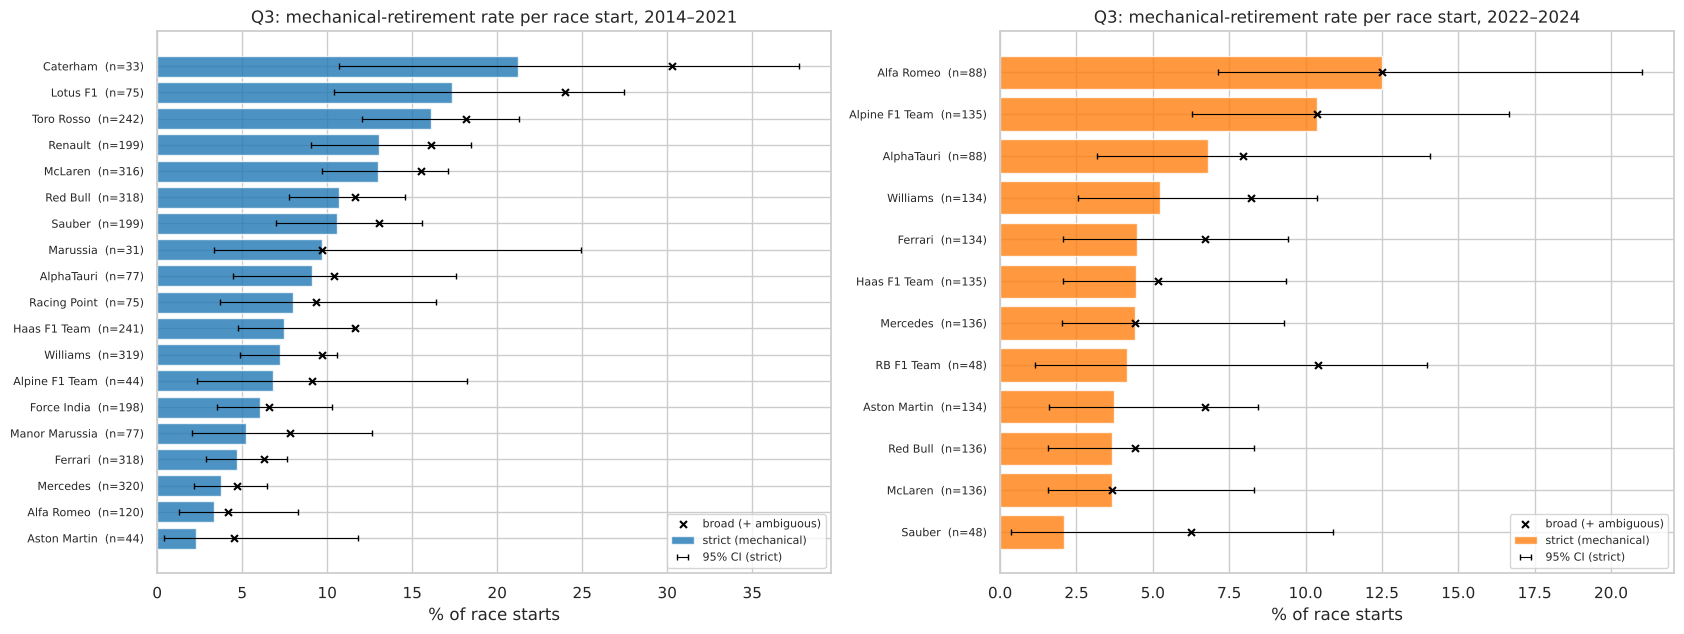

In [26]:
# DECISION D11 → see DECISIONS.md  (denominator = race starts, strict vs broad mechanical, min 30 starts, intervals)
q3 = results_clean[results_clean["year"].between(2014, 2024) & results_clean["started_race"]].merge(
    df["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor"}), on="constructorId", how="left")
q3["period"] = np.where(q3["year"] <= 2021, "2014–2021", "2022–2024")
# Strict: only labels where a car component failed (D3). Broad: also the ambiguous labels, as a robustness check.
q3["mech"] = (q3["category"] == "mechanical").astype(int)
q3["mech_broad"] = q3["category"].isin(["mechanical", "ambiguous"]).astype(int)
# A failure with 0 laps completed can be a first-lap retirement OR a car that never really started (the data codes some
# pre-start failures as 'R'). Second robustness check: count only mechanical failures after at least one lap.
q3["mech_1lap"] = ((q3["category"] == "mechanical") & (q3["laps"] > 0)).astype(int)

agg = q3.groupby(["period", "constructorId", "constructor"]).agg(starts=("mech", "size"), mech=("mech", "sum"), mech_broad=("mech_broad", "sum"),
                                                                  mech_1lap=("mech_1lap", "sum"))
agg["rate"] = agg["mech"] / agg["starts"]
agg["rate_broad"] = agg["mech_broad"] / agg["starts"]
agg["rate_after_lap1"] = agg["mech_1lap"] / agg["starts"]
agg["ci_low"], agg["ci_high"] = wilson(agg["mech"], agg["starts"])
agg = agg[agg["starts"] >= 30]                     # D11: below 30 starts one or two failures swing the rate too much

PERIODS3 = ["2014–2021", "2022–2024"]
for p in PERIODS3:
    t = agg.loc[p].droplevel("constructorId").sort_values("rate", ascending=False)
    t["rank strict"] = t["rate"].rank(ascending=False, method="min").astype(int)
    t["rank broad"] = t["rate_broad"].rank(ascending=False, method="min").astype(int)
    t["rank after lap 1"] = t["rate_after_lap1"].rank(ascending=False, method="min").astype(int)
    tab = np.c_[t["mech"], t["starts"] - t["mech"]]
    print(f"\n{p}: overall mechanical-retirement rate = {q3.loc[q3['period'] == p, 'mech'].mean():.3f} | "
          f"teams differ? chi-square p = {chi2_contingency(tab)[1]:.3g}")
    display(t.round(3))
both = agg["rate"].unstack("period").dropna()
print(f"Teams present in both periods: {len(both)} | Spearman ρ of their rates = {spearmanr(both[PERIODS3[0]], both[PERIODS3[1]])[0]:.2f} "
      f"(p = {spearmanr(both[PERIODS3[0]], both[PERIODS3[1]])[1]:.2f})")

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
for ax, p, col in zip(axes, PERIODS3, ["tab:blue", "tab:orange"]):
    t = agg.loc[p].droplevel("constructorId").sort_values("rate")
    y = np.arange(len(t))
    ax.barh(y, t["rate"] * 100, color=col, alpha=0.8, label="strict (mechanical)")
    ax.errorbar(t["rate"] * 100, y, xerr=[(t["rate"] - t["ci_low"]) * 100, (t["ci_high"] - t["rate"]) * 100],
                fmt="none", ecolor="black", capsize=2, lw=0.8, label="95% CI (strict)")
    ax.scatter(t["rate_broad"] * 100, y, color="black", marker="x", s=25, zorder=3, label="broad (+ ambiguous)")
    ax.set_yticks(y); ax.set_yticklabels([f"{c}  (n={n})" for c, n in zip(t.index, t["starts"])], fontsize=8)
    ax.set_title(f"Q3: mechanical-retirement rate per race start, {p}")
    ax.set_xlabel("% of race starts"); ax.legend(loc="lower right", fontsize=8)
save_fig("10_q3_mechanical")

**How to read the Q3 tables** (one row per constructor; only teams with at least 30 starts in the period)

* **starts**: how many times the team's cars took the start in that period (2 cars per race, so about 40 starts per season). This is the denominator of every rate.
* **mech**: how many of those starts ended in a **mechanical** retirement (strict definition: the status names a failed car part, e.g. "Engine", "Gearbox", "Hydraulics").
* **mech_broad**: the same count plus retirements with an **ambiguous** label (e.g. "Retired"), which may or may not be mechanical.
* **mech_1lap**: strict mechanical retirements that happened **after at least one lap**, so cars that failed before or at the start are left out.
* **rate** = mech ÷ starts: the share of starts lost to a mechanical failure. Example: Caterham 7 ÷ 33 = 0.212, so 21.2% of its starts ended with a broken car.
* **rate_broad** = mech_broad ÷ starts, and **rate_after_lap1** = mech_1lap ÷ starts: the same rate under the two robustness definitions.
* **ci_low / ci_high**: the 95% confidence interval (Wilson method) of the strict rate. Caterham's true rate is probably between 10.7% and 37.8%; the interval is wide because it had only 33 starts. When two teams' intervals overlap a lot, we cannot say one is really less reliable than the other.
* **rank strict / rank broad / rank after lap 1**: the team's place when sorted by each of the three rates (1 = most mechanical failures). If a team's three ranks are close, its position does not depend on how "mechanical" is defined.
* **Chi-square p** (line above each table): the chance that differences between teams this large appear by luck alone, if all teams were equally reliable. Below 0.05, teams really differ.
* **Spearman ρ** (line after the tables): do the teams that failed most in 2014–2021 also fail most in 2022–2024? +1 = same order, 0 = unrelated, −1 = reversed.
* In the bar chart, each bar is the strict rate with its 95% interval, the black × is the broad rate, and *n* is the number of starts.

**Answer to Q3** *(numbers from the output above)*

* **2014–2021 (overall 8.9% of race starts):** the highest rates belong to **Caterham (21.2%, n = 33)**, **Lotus F1 (17.3%)**, **Toro Rosso (16.1%)**, **Renault (13.1%)** and **McLaren (13.0%)**; the lowest to Aston Martin (2.3%, n = 44), Alfa Romeo (3.3%) and **Mercedes (3.8%)**, the dominant team of that period. Teams differ clearly (chi-square p < 0.001).
* **2022–2024 (overall 5.5%):** the highest are **Alfa Romeo (12.5%, 95% CI 7–21%)**, **Alpine (10.4%)** and **AlphaTauri (6.8%)**; the lowest Sauber (2.1%, n = 48), McLaren, Red Bull and Aston Martin (3.7% each). Here the differences between teams are only borderline (p = 0.052) and most intervals overlap, so apart from Alfa Romeo and Alpine standing out, the order is weak evidence.
* **Change between periods:** mechanical failures became rarer overall, but not for everyone: McLaren (13.0% → 3.7%) and Red Bull (10.7% → 3.7%) improved sharply, while Alfa Romeo got worse (3.3% → 12.5%). For the 11 teams present in both periods the rank correlation is −0.49 (p = 0.13): there is no stable "unreliable team" across the two eras.
* **Robustness.** Adding the ambiguous labels (broad rate) leaves the 2014–2021 top five unchanged and Alfa Romeo first in 2022–2024. Below first place the 2022–2024 order does depend on the labels: RB F1 Team (2024 only, 48 starts) moves to 2nd and AlphaTauri to 5th, because several of their retirements are labelled ambiguously ("Retired").
* **Second robustness check: failures with 0 laps.** The data codes some cars that failed *before* the start as retirements with 0 laps (e.g. Tsunoda at Saudi Arabia 2022, credited with grid 19 and "Power Unit"), and the data alone cannot tell those apart from first-lap failures. Counting only mechanical failures after at least one lap changes very little: the 2014–2021 top three stay the same, and in 2022–2024 Alfa Romeo and Alpine stay first and second; AlphaTauri drops from 6.8% to 4.5% and is then level with Williams and Ferrari.

**Grain / missingness / cutoff.** One row per car that took the start; status has no missing values. Status is **post-race** information: it is used only for this analysis and never as a feature for the current race. A constructor's *past* reliability is a legal feature when computed only from earlier races, which is what `con_mech_rate_last10` does (Section 6).

## 6. Feature engineering (leakage-safe)

**The rule for every feature:** it must be known *after qualifying and before the race starts*. Anything from the current race's result (position, points, laps, status, pit stops, lap times, fastest lap) and the standings published *after* the current race are forbidden.

We build five **feature groups**. The groups are used again in the ablation (Section 10).

🔶 **Decision D16 — feature groups**

| group | features | why it should help (hypothesis from EDA) |
|---|---|---|
| **grid** | `grid_pos`, `grid_pct`, `pit_lane_start` | Section 4(d): podium rate falls steeply with grid slot |
| **qualifying** | `quali_position`, `quali_gap_pct`, `grid_penalty` | Q1: qualifying pace and penalties change podium chances |
| **standings** | driver & constructor points share, rank and win share **before** this race | Section 4: one constructor often dominates a season |
| **form** | driver & constructor podium rate / average finish over their last 5 races, constructor mechanical-failure rate over last 10 | recent results and reliability (Q3) differ by team |
| **context** | `driver_age`, `experience`, `home_race`, `field_size` | field size sets the base rate; Q2 tests home advantage |

🔶 **Decision D17 (part 1) — the training window starts in 1994.** Feature evidence in 6.7 is computed on the seasons the model will actually be trained on. The window is fixed here for domain reasons: 1994 is the first season with any qualifying data (Section 2.3), and the sport before it differs strongly (bigger fields, frequent breakdowns, weaker grid effect, Section 4). Section 8.4 tests whether another window would clearly do better.

In [27]:
# DECISION D17 → see DECISIONS.md  (training window 1994–2019; domain choice, checked empirically in 8.4)
TRAIN_START, TRAIN_END, VAL_END = 1994, 2019, 2021

### 6.1 Base table and race order

Every past-only feature needs a strict notion of "earlier". We order races by date (then by `raceId` as a tie-breaker) and give every race a running index `race_seq`.

In [28]:
races = df["races"][["raceId", "year", "round", "circuitId", "date"]].sort_values(["date", "raceId"]).reset_index(drop=True)
races["race_seq"] = np.arange(len(races))     # 0, 1, 2, ... in chronological order
assert not races["date"].duplicated().any(), "two races on the same date: order would be ambiguous"

base = results_clean[["raceId", "driverId", "constructorId", "year", "grid_clean", "pit_lane_start", "started_race",
                      "field_size", "finish_rank", "category", "podium"]].copy()
base = base.merge(races[["raceId", "round", "circuitId", "date", "race_seq"]], on="raceId", how="left", validate="many_to_one")
base = base.sort_values(["race_seq", "grid_clean"]).reset_index(drop=True)
print(base.shape)

(24715, 15)


### 6.2 Grid group

* `grid_pos`: starting slot after penalties, re-ranked among the cars on the grid (D7).
* `grid_pct`: the same slot as a fraction of the field (0 = pole, 1 = last). P10 in a 30-car field is not the same as P10 in a 20-car field.
* `pit_lane_start`: flag from D7.

In [29]:
base["grid_pos"] = base["grid_clean"]
base["grid_pct"] = (base["grid_clean"] - 1) / (base["field_size"] - 1)
assert base["grid_pct"].between(0, 1).all()

### 6.3 Qualifying group

🔶 **Decision D15 — qualifying features.**
* We do **not** use raw lap times (`q1_sec`, `q2_sec`, `q3_sec`) as features. A pole lap at Monaco (~70 s) and at Spa (~105 s) are not comparable, so the model would partly learn track length.
* `quali_gap_pct` = how far the driver's **Q1** lap is from the fastest Q1 lap of that race, in percent. We use Q1 because it is the only session every driver ran: comparing a Q3 lap with a Q1 lap mixes different track conditions, and in 2006–2008 the final session was even run with race fuel loads, so "best lap of any session" was not a fair comparison. Laps more than 20% off the fastest are not a real attempt (a car that stopped or crashed); they are rare (see the plot) and are set to missing.
* `grid_penalty` = `grid_pos − reference slot` (positive = moved back). The reference is the qualifying position, except on the **2021–2022 sprint weekends**, where the sprint set the grid and the reference is the sprint finishing position. Without this, sprint overtakes would be counted as "penalties".
* Qualifying data only exists from 1994 (complete from 2003). In the table, missing qualifying stays **NaN**. The model pipeline later fills it with the training median *and* adds a "was missing" indicator column (D19), so the model can tell "not recorded" (old seasons) from "slow".

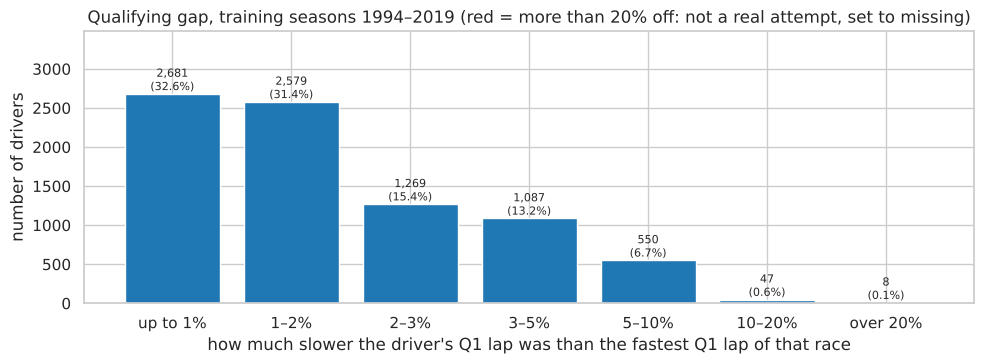

Q1 laps more than 20% slower than the fastest (a car that stopped or crashed, set to missing): 10 of 10,338 in all seasons (8 in the training seasons, the red bar above).
Qualifying position is available for 82% of training rows (1994–2019) and 42% of all rows (1950–2024); qualifying was not recorded before 1994.
164 drivers have a qualifying position but no usable Q1 lap time, so their gap is missing.
32 pole-sitters were more than 1% off the fastest Q1 lap. Pole is decided in the last session (Q3), so the fastest car in Q1 is often someone else: the gap shows pace across the whole field, and quali_position decides the very front.

The three qualifying features on the training rows (1994–2019):


,typical value (median),middle half of drivers,min,max,% missing
quali_position,11.0,6.00 to 17.00,1.0,26.0,18%
quali_gap_pct,1.5,0.79 to 2.63,0.0,19.67,19%
grid_penalty,0.0,0.00 to 0.00,-9.0,23.0,18%


Grid slot compared with qualifying position (training rows with qualifying data):


,drivers,% of drivers
moved back (penalty or pit-lane start),404,4.8
no change,6497,77.8
moved forward (others penalised or not starting),1447,17.3


In [30]:
q = df["qualifying"][["raceId", "driverId", "position", "q1_sec"]].copy()
q["q1_best"] = q.groupby("raceId")["q1_sec"].transform("min")      # fastest Q1 lap of anyone in that race
q["quali_gap_pct"] = (q["q1_sec"] / q["q1_best"] - 1) * 100
q = q.merge(races[["raceId", "year"]], on="raceId", how="left")
in_window = q["year"].between(TRAIN_START, TRAIN_END)          # the cutoff is chosen on training seasons only

# How far off the fastest Q1 lap drivers were, in a few readable bands (training seasons).
bands = pd.cut(q.loc[in_window, "quali_gap_pct"].dropna(), [-np.inf, 1, 2, 3, 5, 10, 20, np.inf],
               labels=["up to 1%", "1–2%", "2–3%", "3–5%", "5–10%", "10–20%", "over 20%"])
counts = bands.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 3.8))
bars = ax.bar(counts.index.astype(str), counts.values, color=["tab:blue"] * 6 + ["tab:red"])
for b, n in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{n:,}\n({n / counts.sum():.1%})", ha="center", va="bottom", fontsize=8)
ax.set_ylim(0, counts.max() * 1.3)
ax.set_xlabel("how much slower the driver's Q1 lap was than the fastest Q1 lap of that race")
ax.set_ylabel("number of drivers")
ax.set_title(f"Qualifying gap, training seasons {TRAIN_START}–{TRAIN_END} (red = more than 20% off: not a real attempt, set to missing)")
save_fig("11a_quali_gap_cutoff")
print(f"Q1 laps more than 20% slower than the fastest (a car that stopped or crashed, set to missing): "
      f"{int((q['quali_gap_pct'] > 20).sum())} of {int(q['quali_gap_pct'].notna().sum()):,} in all seasons "
      f"({int(counts['over 20%'])} in the training seasons, the red bar above).")
q.loc[q["quali_gap_pct"] > 20, "quali_gap_pct"] = np.nan

# DECISION D15 → see DECISIONS.md  (position + Q1 gap %, not raw lap times; penalty vs the right reference slot)
base = base.merge(q[["raceId", "driverId", "position", "quali_gap_pct"]].rename(columns={"position": "quali_position"}),
                  on=["raceId", "driverId"], how="left", validate="one_to_one")
sprint_pos = df["sprint_results"].set_index(["raceId", "driverId"])["positionOrder"]
sprint_set_grid = base["raceId"].isin(set(df["sprint_results"]["raceId"])) & base["year"].between(2021, 2022)
reference = base["quali_position"].copy()
reference[sprint_set_grid] = [sprint_pos.get(k, np.nan) for k in zip(base.loc[sprint_set_grid, "raceId"], base.loc[sprint_set_grid, "driverId"])]
base["grid_penalty"] = base["grid_pos"] - reference

train = base["year"].between(TRAIN_START, TRAIN_END)
print(f"Qualifying position is available for {base.loc[train, 'quali_position'].notna().mean():.0%} of training rows "
      f"({TRAIN_START}–{TRAIN_END}) and {base['quali_position'].notna().mean():.0%} of all rows ({base['year'].min()}–{base['year'].max()}); "
      "qualifying was not recorded before 1994.")
print(f"{int((base['quali_position'].notna() & base['quali_gap_pct'].isna()).sum())} drivers have a qualifying position "
      "but no usable Q1 lap time, so their gap is missing.")
print(f"{int(((base['quali_position'] == 1) & (base['quali_gap_pct'] > 1)).sum())} pole-sitters were more than 1% off the fastest "
      "Q1 lap. Pole is decided in the last session (Q3), so the fastest car in Q1 is often someone else: the gap shows pace "
      "across the whole field, and quali_position decides the very front.")

QUALI = ["quali_position", "quali_gap_pct", "grid_penalty"]
print(f"\nThe three qualifying features on the training rows ({TRAIN_START}–{TRAIN_END}):")
display(pd.DataFrame({c: {"typical value (median)": round(base.loc[train, c].median(), 2),
                          "middle half of drivers": f"{base.loc[train, c].quantile(0.25):.2f} to {base.loc[train, c].quantile(0.75):.2f}",
                          "min": round(base.loc[train, c].min(), 2), "max": round(base.loc[train, c].max(), 2),
                          "% missing": f"{base.loc[train, c].isna().mean():.0%}"} for c in QUALI}).T)

pen = base.loc[train, "grid_penalty"].dropna()
moves = pd.Series({"moved back (penalty or pit-lane start)": (pen > 0).sum(), "no change": (pen == 0).sum(),
                   "moved forward (others penalised or not starting)": (pen < 0).sum()})
print("Grid slot compared with qualifying position (training rows with qualifying data):")
display(pd.DataFrame({"drivers": moves, "% of drivers": (100 * moves / moves.sum()).round(1)}))

### 6.4 Standings group — the "shift" that prevents leakage

`driver_standings` and `constructor_standings` hold the championship table **after** each race, so the row for race N already contains race N's points. Using it would leak the answer.

🔶 **Decision D13 — standings before the race.**
* For race N we join the standings of the **previous race of the same season**. We do this with an explicit lookup table `raceId → prev_raceId` rather than a row `shift()`, so a driver who missed a race still gets the correct previous table.
* For the **first race of a season** there is no earlier race that year. We use the **final standings of the previous season**: they are known before the opener and describe how strong each driver and team was. That table describes a whole season rather than a few races, so we considered a flag `season_opener` to tell the model which kind of table it is looking at. We do not use it as a feature: whether a race is an opener says nothing by itself about who finishes on the podium (every race has three podiums), and a test with the flag in the model showed no measurable gain (D13). The opener rule is still used in the code, to choose which table to join.
* A driver or team that does not appear in the previous table (no points yet, or new) gets 0 points, no wins and the rank after the last ranked entry.
* Points systems changed (a win was worth 8, 9, 10 and now 25 points) and season lengths changed (7 to 24 races), so we use **points as a share of the leader's points**, the **rank**, and **wins as a share of the races run so far**, which mean the same thing in every era.
* Exclusions from a championship (Schumacher 1997, McLaren's constructors' result 2007) were decided **at or after the end of the season**, although the data flags McLaren as excluded in every 2007 table. So during a season we use the points as they were published (McLaren was leading in mid-2007); only the previous season's **final** table used for an opener applies the exclusion (0 points, never the leader), because by then it was known.

🔶 **Decision D12 — sprint results are not used as features (except as the grid reference in D15).** A sprint runs before the main race, so it is technically pre-race information. But sprints only exist from 2021: they are **absent from every training season** (1994–2019), so a model could not learn anything from them, and in 2021–22 the sprint result *was* the grid, which `grid_pos` already contains. The standings we join (from the *previous* race) already include earlier weekends' sprint points.

In [31]:
# prev_raceId: the race whose standings describe the situation just before this race.
season_order = races.sort_values(["year", "round"]).copy()
season_order["prev_raceId"] = season_order.groupby("year")["raceId"].shift(1)        # previous race, same season
last_of_season = season_order.groupby("year")["raceId"].last()                      # final race of each season
openers = season_order["prev_raceId"].isna()
season_order.loc[openers, "prev_raceId"] = season_order.loc[openers, "year"].map(lambda y: last_of_season.get(y - 1, np.nan))
prev_map = season_order.set_index("raceId")["prev_raceId"]
base["prev_raceId"] = base["raceId"].map(prev_map)
races_so_far = races.set_index("raceId")["round"]               # races completed when the prev_raceId table was published

def standings_before(table, key, prefix, apply_exclusions):
    """Standings after prev_raceId: share of the leader's points, rank, and wins per race run so far.
    apply_exclusions: True only for previous-season FINAL tables (exclusions were decided at season end)."""
    st = df[table][["raceId", key, "points", "position", "positionText", "wins"]].copy()
    if apply_exclusions:
        excluded = ~st["positionText"].astype(str).str.isdigit()              # 'D' / 'E' = excluded from that championship
        st.loc[excluded, ["points", "wins"]] = 0
        st.loc[excluded, "position"] = np.nan
    st["leader_pts"] = st.groupby("raceId")["points"].transform("max")
    st[f"{prefix}_pts_share_before"] = np.where(st["leader_pts"] > 0, st["points"] / st["leader_pts"], 0.0)
    st[f"{prefix}_rank_before"] = st["position"]
    st[f"{prefix}_win_share_before"] = st["wins"] / st["raceId"].map(races_so_far)
    st = st.rename(columns={"raceId": "prev_raceId"})
    return st[["prev_raceId", key, f"{prefix}_pts_share_before", f"{prefix}_rank_before", f"{prefix}_win_share_before"]]

# DECISION D13 → see DECISIONS.md  (standings from the previous race / previous season's final table)
# DECISION D12 → see DECISIONS.md  (sprint_results is deliberately NOT joined as a feature)
for table, key, prefix in [("driver_standings", "driverId", "drv"), ("constructor_standings", "constructorId", "con")]:
    st_in, st_final = standings_before(table, key, prefix, False), standings_before(table, key, prefix, True)
    cols = [c for c in st_in.columns if c.startswith(prefix)]
    m_in = base[["prev_raceId", key]].merge(st_in, on=["prev_raceId", key], how="left", validate="many_to_one")
    m_fin = base[["prev_raceId", key]].merge(st_final, on=["prev_raceId", key], how="left", validate="many_to_one")
    opener = (base["round"] == 1).to_numpy()          # season opener: use the previous season's final table
    for c in cols:                                   # openers: final table with exclusions; in-season: table as published
        base[c] = np.where(opener, m_fin[c].to_numpy(), m_in[c].to_numpy())
    st = st_final
    # Entries with no row (or an excluded row) in the previous table: 0 points, no wins, ranked after the last ranked entry.
    has_table = base["prev_raceId"].isin(st["prev_raceId"])
    worst = st.groupby("prev_raceId")[f"{prefix}_rank_before"].max()
    missing = has_table & base[f"{prefix}_rank_before"].isna()
    base.loc[missing, [f"{prefix}_pts_share_before", f"{prefix}_win_share_before"]] = 0.0
    base.loc[missing, f"{prefix}_rank_before"] = base.loc[missing, "prev_raceId"].map(worst) + 1

# Constructor standings only exist from 1958, and the 1950 opener has no previous season: those stay NaN.
print("Missing driver standings:", int(base["drv_rank_before"].isna().sum()), "rows (1950 opener)",
      "| missing constructor standings:", int(base["con_rank_before"].isna().sum()), "rows (before 1958)")

Missing driver standings: 23 rows (1950 opener) | missing constructor standings: 1181 rows (before 1958)


**Leakage check on the standings.** For a known race we compare the leaky value ("after this race") with our feature ("before this race"). Verstappen at the 2023 Belgian GP had 314 points after the race and 281 before it.

In [32]:
spa23 = races[(races["year"] == 2023) & (races["round"] == 12)]["raceId"].iloc[0]
ver = df["drivers"].loc[df["drivers"]["driverRef"] == "max_verstappen", "driverId"].iloc[0]
after = df["driver_standings"].query("raceId == @spa23 and driverId == @ver")["points"].iloc[0]
before = df["driver_standings"].query("raceId == @prev_map[@spa23] and driverId == @ver")["points"].iloc[0]
ver_row = base.query("raceId == @spa23 and driverId == @ver")
print(f"Points after the race (leaky): {after} | points before the race: {before}")
print(f"Feature used: rank {int(ver_row['drv_rank_before'].iloc[0])}, points share {ver_row['drv_pts_share_before'].iloc[0]:.3f} "
      f"(= {before} / leader's points before the race), win share {ver_row['drv_win_share_before'].iloc[0]:.2f}")

# Every prev_raceId must be strictly earlier in time than the race itself.
seq = races.set_index("raceId")["race_seq"]
assert (base["prev_raceId"].dropna().map(seq).values < base.loc[base["prev_raceId"].notna(), "raceId"].map(seq).values).all()
print("✔ every standings feature comes from a race that happened earlier")

Points after the race (leaky): 314.0 | points before the race: 281.0
Feature used: rank 1, points share 1.000 (= 281.0 / leader's points before the race), win share 0.82


✔ every standings feature comes from a race that happened earlier


**Standings features used by the model (6).** All are taken from the standings table published **after the previous race** (or, at the first race of a season, the previous season's final table), so none of them contains the result of the race being predicted. The raw points, positions and wins are only used to compute them.

| feature | what it measures |
|---|---|
| `drv_pts_share_before` | the driver's championship points ÷ the leader's points (1 = leading the championship, 0.5 = half the leader's points) |
| `drv_rank_before` | the driver's position in the championship (1 = leader) |
| `drv_win_share_before` | the driver's wins ÷ races run so far in the season (0.5 = won half of them) |
| `con_pts_share_before` | the same points share for the driver's team (constructors' championship) |
| `con_rank_before` | the team's position in the constructors' championship |
| `con_win_share_before` | the team's wins ÷ races run so far in the season |

Shares are used instead of raw points and wins because the points for a win (8, 9, 10, now 25) and the number of races per season (7 to 24) changed over time; a share means the same in every era.

### 6.5 Form group — rolling windows over past races only

🔶 **Decision D14 — form windows.**
* **Driver form:** podium rate and average finishing position (as a fraction of the field, 0 = winner) over the driver's **previous 5 races**.
* **Constructor form:** the same over the constructor's **previous 5 races** (both cars together), plus the constructor's **mechanical-failure rate over its previous 10 races** (the reliability that Q3 showed differs a lot between teams; a longer window because failures are rarer than podiums).
* The windows carry across season boundaries (the first races of a season still have a recent history).
* `shift(1)` before `rolling(...)` is what makes these features past-only: the current race is never inside its own window.
* Constructor form follows `constructorId`, so a renamed team starts with no history (accepted limitation).
* Window length 5 is a trade-off: long enough to smooth one bad race, short enough to react within a season.

In [33]:
base["finish_pct"] = (base["finish_rank"] - 1) / (base["field_size"] - 1)   # 0 = winner, 1 = last (post-race! only used shifted)
base["mech_fail"] = (base["category"] == "mechanical").astype(int)
assert base["finish_pct"].between(0, 1).all()

# DECISION D14 → see DECISIONS.md  (past-only rolling windows)
base = base.sort_values(["race_seq", "grid_pos"]).reset_index(drop=True)
g = base.groupby("driverId")
base["drv_podium_rate_last5"] = g["podium"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
base["drv_avg_finish_last5"] = g["finish_pct"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
base["experience"] = g.cumcount()                    # number of previous races on the grid (0 on debut)

# Constructor level: first collapse to one row per (constructor, race) so teammates in the SAME race never leak into each other.
con_race = (base.groupby(["constructorId", "raceId", "race_seq"], as_index=False)
                .agg(con_podiums=("podium", "mean"), con_finish=("finish_pct", "mean"), con_mech=("mech_fail", "mean"))
                .sort_values("race_seq"))
gc = con_race.groupby("constructorId")
con_race["con_podium_rate_last5"] = gc["con_podiums"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
con_race["con_avg_finish_last5"] = gc["con_finish"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
con_race["con_mech_rate_last10"] = gc["con_mech"].transform(lambda s: s.shift(1).rolling(10, min_periods=1).mean())
base = base.merge(con_race[["constructorId", "raceId", "con_podium_rate_last5", "con_avg_finish_last5", "con_mech_rate_last10"]],
                  on=["constructorId", "raceId"], how="left", validate="many_to_one")

# Leakage spot-check: recompute one driver's feature by hand from strictly earlier races.
chk = base[base["driverId"] == ver].sort_values("race_seq").iloc[60]
earlier = base[(base["driverId"] == ver) & (base["race_seq"] < chk["race_seq"])].sort_values("race_seq").tail(5)
assert np.isclose(earlier["podium"].mean(), chk["drv_podium_rate_last5"])
print(f"✔ hand check: Verstappen's podium rate over the 5 races before raceId {int(chk['raceId'])} "
      f"= {earlier['podium'].mean():.2f}, feature = {chk['drv_podium_rate_last5']:.2f}")

✔ hand check: Verstappen's podium rate over the 5 races before raceId 989 = 0.40, feature = 0.40


**Form features used by the model (5).** Each is an average over the driver's or team's **previous** races only (the current race is never inside its window). If fewer races exist (e.g. a rookie's 3rd race), the average uses those available; at a first-ever race there is no history and the value is missing (filled later in the pipeline, D19).

| feature | what it measures |
|---|---|
| `drv_podium_rate_last5` | share of the driver's last 5 races that ended on the podium (0.4 = 2 podiums in 5 races) |
| `drv_avg_finish_last5` | the driver's average finishing position over his last 5 races, as a fraction of the field (0 = always won, 1 = always last) |
| `con_podium_rate_last5` | share of the team's cars that finished on the podium over its last 5 races (both cars counted, so 0.5 = one car on the podium per race on average) |
| `con_avg_finish_last5` | the team's average finishing position (both cars, as a fraction of the field) over its last 5 races |
| `con_mech_rate_last10` | share of the team's cars that retired with a mechanical failure over its last 10 races (team reliability, see Q3) |

The cell also computes `experience` (number of previous races on the grid), which belongs to the context group (6.6).

### 6.6 Context group

* `driver_age` at race date (date of birth is known in advance).
* `experience`: number of previous races on the grid (computed above, from the cleaned table).
* `home_race`: nationality matches the circuit's country (mapping from Q2, D10).
* `field_size`: number of cars on the grid. A bigger field lowers every driver's podium chance.

All numeric features are rounded to 6 decimals. This changes no value in a meaningful way, but it removes floating-point noise (differences in the 15th decimal) that otherwise makes histogram-based models give slightly different results after saving and reloading the table.

In [34]:
base = base.merge(df["drivers"][["driverId", "dob", "nationality"]], on="driverId", how="left", validate="many_to_one")
base["driver_age"] = (base["date"] - base["dob"]).dt.days / 365.25
base = base.merge(df["circuits"][["circuitId", "country"]], on="circuitId", how="left", validate="many_to_one")
base["home_race"] = home_flag(base["nationality"], base["country"])          # same rule as Q2 (dual nationality = both countries)

# DECISION D16 → see DECISIONS.md  (the five feature groups, reused by the ablation)
FEATURE_GROUPS = {
    "grid": ["grid_pos", "grid_pct", "pit_lane_start"],
    "qualifying": ["quali_position", "quali_gap_pct", "grid_penalty"],
    "standings": ["drv_pts_share_before", "drv_rank_before", "drv_win_share_before",
                  "con_pts_share_before", "con_rank_before", "con_win_share_before"],
    "form": ["drv_podium_rate_last5", "drv_avg_finish_last5",
             "con_podium_rate_last5", "con_avg_finish_last5", "con_mech_rate_last10"],
    "context": ["driver_age", "experience", "home_race", "field_size"],
}
FEATURES = [f for fs in FEATURE_GROUPS.values() for f in fs]
ID_COLS = ["raceId", "driverId", "constructorId", "year", "round", "date"]

# Leakage guard: none of the post-race columns may be a feature.
POST_RACE = {"positionOrder", "position", "positionText", "points", "laps", "time", "milliseconds", "fastestLap",
             "rank", "fastestLapTime", "fastestLapSpeed", "statusId", "category", "finish_pct", "finish_rank",
             "mech_fail", "started_race"}
assert not POST_RACE & set(FEATURES), "a post-race column is listed as a feature"

model_table = base[ID_COLS + FEATURES + ["podium"]].sort_values(["date", "raceId", "grid_pos"]).reset_index(drop=True)
model_table[FEATURES] = model_table[FEATURES].astype(float).round(6)
assert not model_table.duplicated(["raceId", "driverId"]).any()
model_table.to_csv(os.path.join(OUT_DIR, "f1_modeling_table.csv"), index=False)
print(model_table.shape, "| features:", len(FEATURES))
model_table.sample(5, random_state=SEED)

(24715, 28) | features: 21


,raceId,driverId,constructorId,year,round,date,grid_pos,grid_pct,pit_lane_start,quali_position,quali_gap_pct,grid_penalty,drv_pts_share_before,drv_rank_before,drv_win_share_before,con_pts_share_before,con_rank_before,con_win_share_before,drv_podium_rate_last5,drv_avg_finish_last5,con_podium_rate_last5,con_avg_finish_last5,con_mech_rate_last10,driver_age,experience,home_race,field_size,podium
4106,628,309,1,1972,9,1972-08-13,4.0,0.125000,0.0,NaN,NaN,NaN,0.232558,6.0,0.0,0.674419,4.0,0.125000,0.4,0.248667,0.200000,0.277818,0.15,33.459274,10.0,0.0,25.0,1
22235,1013,842,9,2019,4,2019-04-28,20.0,1.000000,1.0,20.0,NaN,0.0,0.191176,6.0,0.0,0.400000,3.0,0.000000,0.0,0.515789,0.300000,0.205263,0.10,23.219713,29.0,0.0,20.0,0
6916,501,152,51,1980,4,1980-03-30,6.0,0.217391,0.0,NaN,NaN,NaN,0.111111,10.0,0.0,0.111111,9.0,0.000000,0.0,0.608696,0.000000,0.595652,0.35,27.550992,13.0,0.0,24.0,0
1661,755,347,66,1960,10,1960-11-20,4.0,0.136364,0.0,NaN,NaN,NaN,0.050000,22.0,0.0,0.125000,4.0,0.000000,0.0,0.711446,0.066667,0.657442,0.45,30.803559,28.0,0.0,23.0,0
8647,449,170,34,1984,14,1984-09-09,5.0,0.160000,0.0,NaN,NaN,NaN,0.166667,12.0,0.0,0.306977,5.0,0.153846,0.2,0.321615,0.100000,0.411859,0.50,29.505818,17.0,1.0,26.0,0


### 6.7 Evidence for the features

Feature choices must be backed by evidence. We use three checks, **all computed on the training window only (1994–2019)**, so validation and test seasons stay unseen and the evidence describes the rows the model will learn from:

1. **Standalone ROC-AUC** of each feature: how well that single feature ranks podium finishers above the rest (0.5 = no signal). Features where *lower* is better (e.g. grid) are flipped so all values read the same way. For grid vs qualifying we also compare on **the same rows** (rows that have qualifying data), so the comparison is fair.
2. **Podium rate across feature bins**, for every feature: a picture of the relationship.
3. **Correlation between features:** which features carry overlapping information (relevant for interpreting the ablation and SHAP later).

,group,feature,auc,direction,missing %
3,qualifying,quali_position,0.905,lower → podium,17.8
0,grid,grid_pos,0.905,lower → podium,0.0
1,grid,grid_pct,0.905,lower → podium,0.0
9,standings,con_pts_share_before,0.882,higher → podium,0.0
7,standings,drv_rank_before,0.877,lower → podium,0.0
14,form,con_podium_rate_last5,0.872,higher → podium,0.5
6,standings,drv_pts_share_before,0.869,higher → podium,0.0
10,standings,con_rank_before,0.868,lower → podium,0.0
15,form,con_avg_finish_last5,0.866,lower → podium,0.5
12,form,drv_podium_rate_last5,0.849,higher → podium,1.2


On the same rows (training rows with qualifying data): {'grid_pos': 0.904, 'quali_position': 0.905}


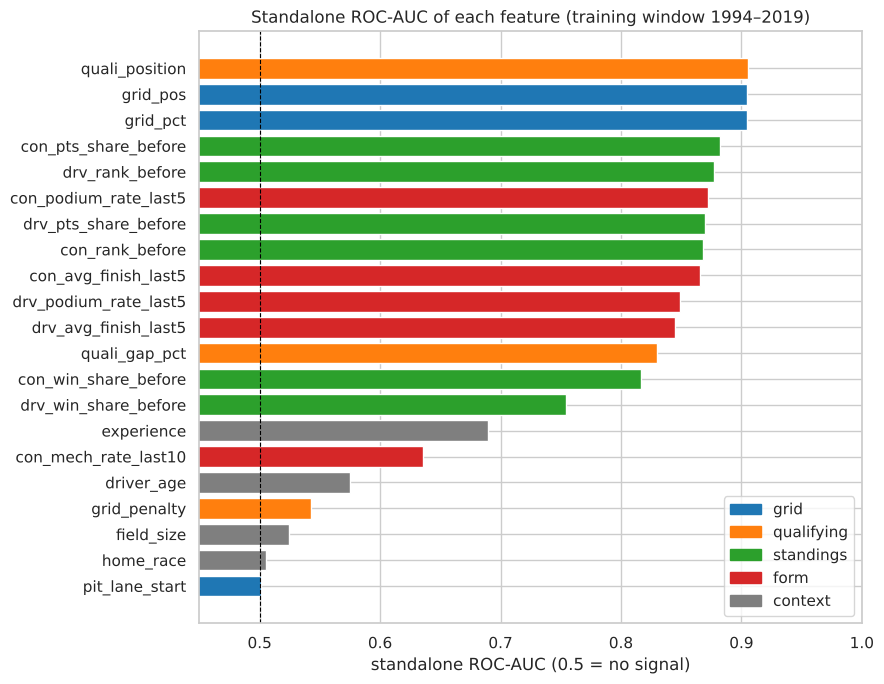

In [35]:
from sklearn.metrics import roc_auc_score
from matplotlib.patches import Patch

train_rows = model_table[model_table["year"].between(TRAIN_START, TRAIN_END)]
ev = []
for grp, cols in FEATURE_GROUPS.items():
    for c in cols:
        m = train_rows[c].notna()
        auc = roc_auc_score(train_rows.loc[m, "podium"], train_rows.loc[m, c]) if train_rows.loc[m, c].nunique() > 1 else np.nan
        ev.append({"group": grp, "feature": c, "auc": max(auc, 1 - auc), "direction": "higher → podium" if auc >= 0.5 else "lower → podium",
                   "missing %": round(100 * (1 - m.mean()), 1)})
evidence = pd.DataFrame(ev).sort_values("auc", ascending=False)
display(evidence.round(3))

same = train_rows["quali_position"].notna()
print("On the same rows (training rows with qualifying data):",
      {c: round(1 - roc_auc_score(train_rows.loc[same, "podium"], train_rows.loc[same, c]), 3) for c in ["grid_pos", "quali_position"]})

fig, ax = plt.subplots(figsize=(9, 7))
colors = dict(zip(FEATURE_GROUPS, ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:gray"]))
e = evidence.sort_values("auc")
ax.barh(e["feature"], e["auc"], color=e["group"].map(colors))
ax.axvline(0.5, color="black", ls="--", lw=0.8)
ax.set_xlim(0.45, 1); ax.set_xlabel("standalone ROC-AUC (0.5 = no signal)")
ax.set_title("Standalone ROC-AUC of each feature (training window 1994–2019)")
ax.legend(handles=[Patch(color=c, label=g) for g, c in colors.items()], loc="lower right")
save_fig("11_feature_auc")

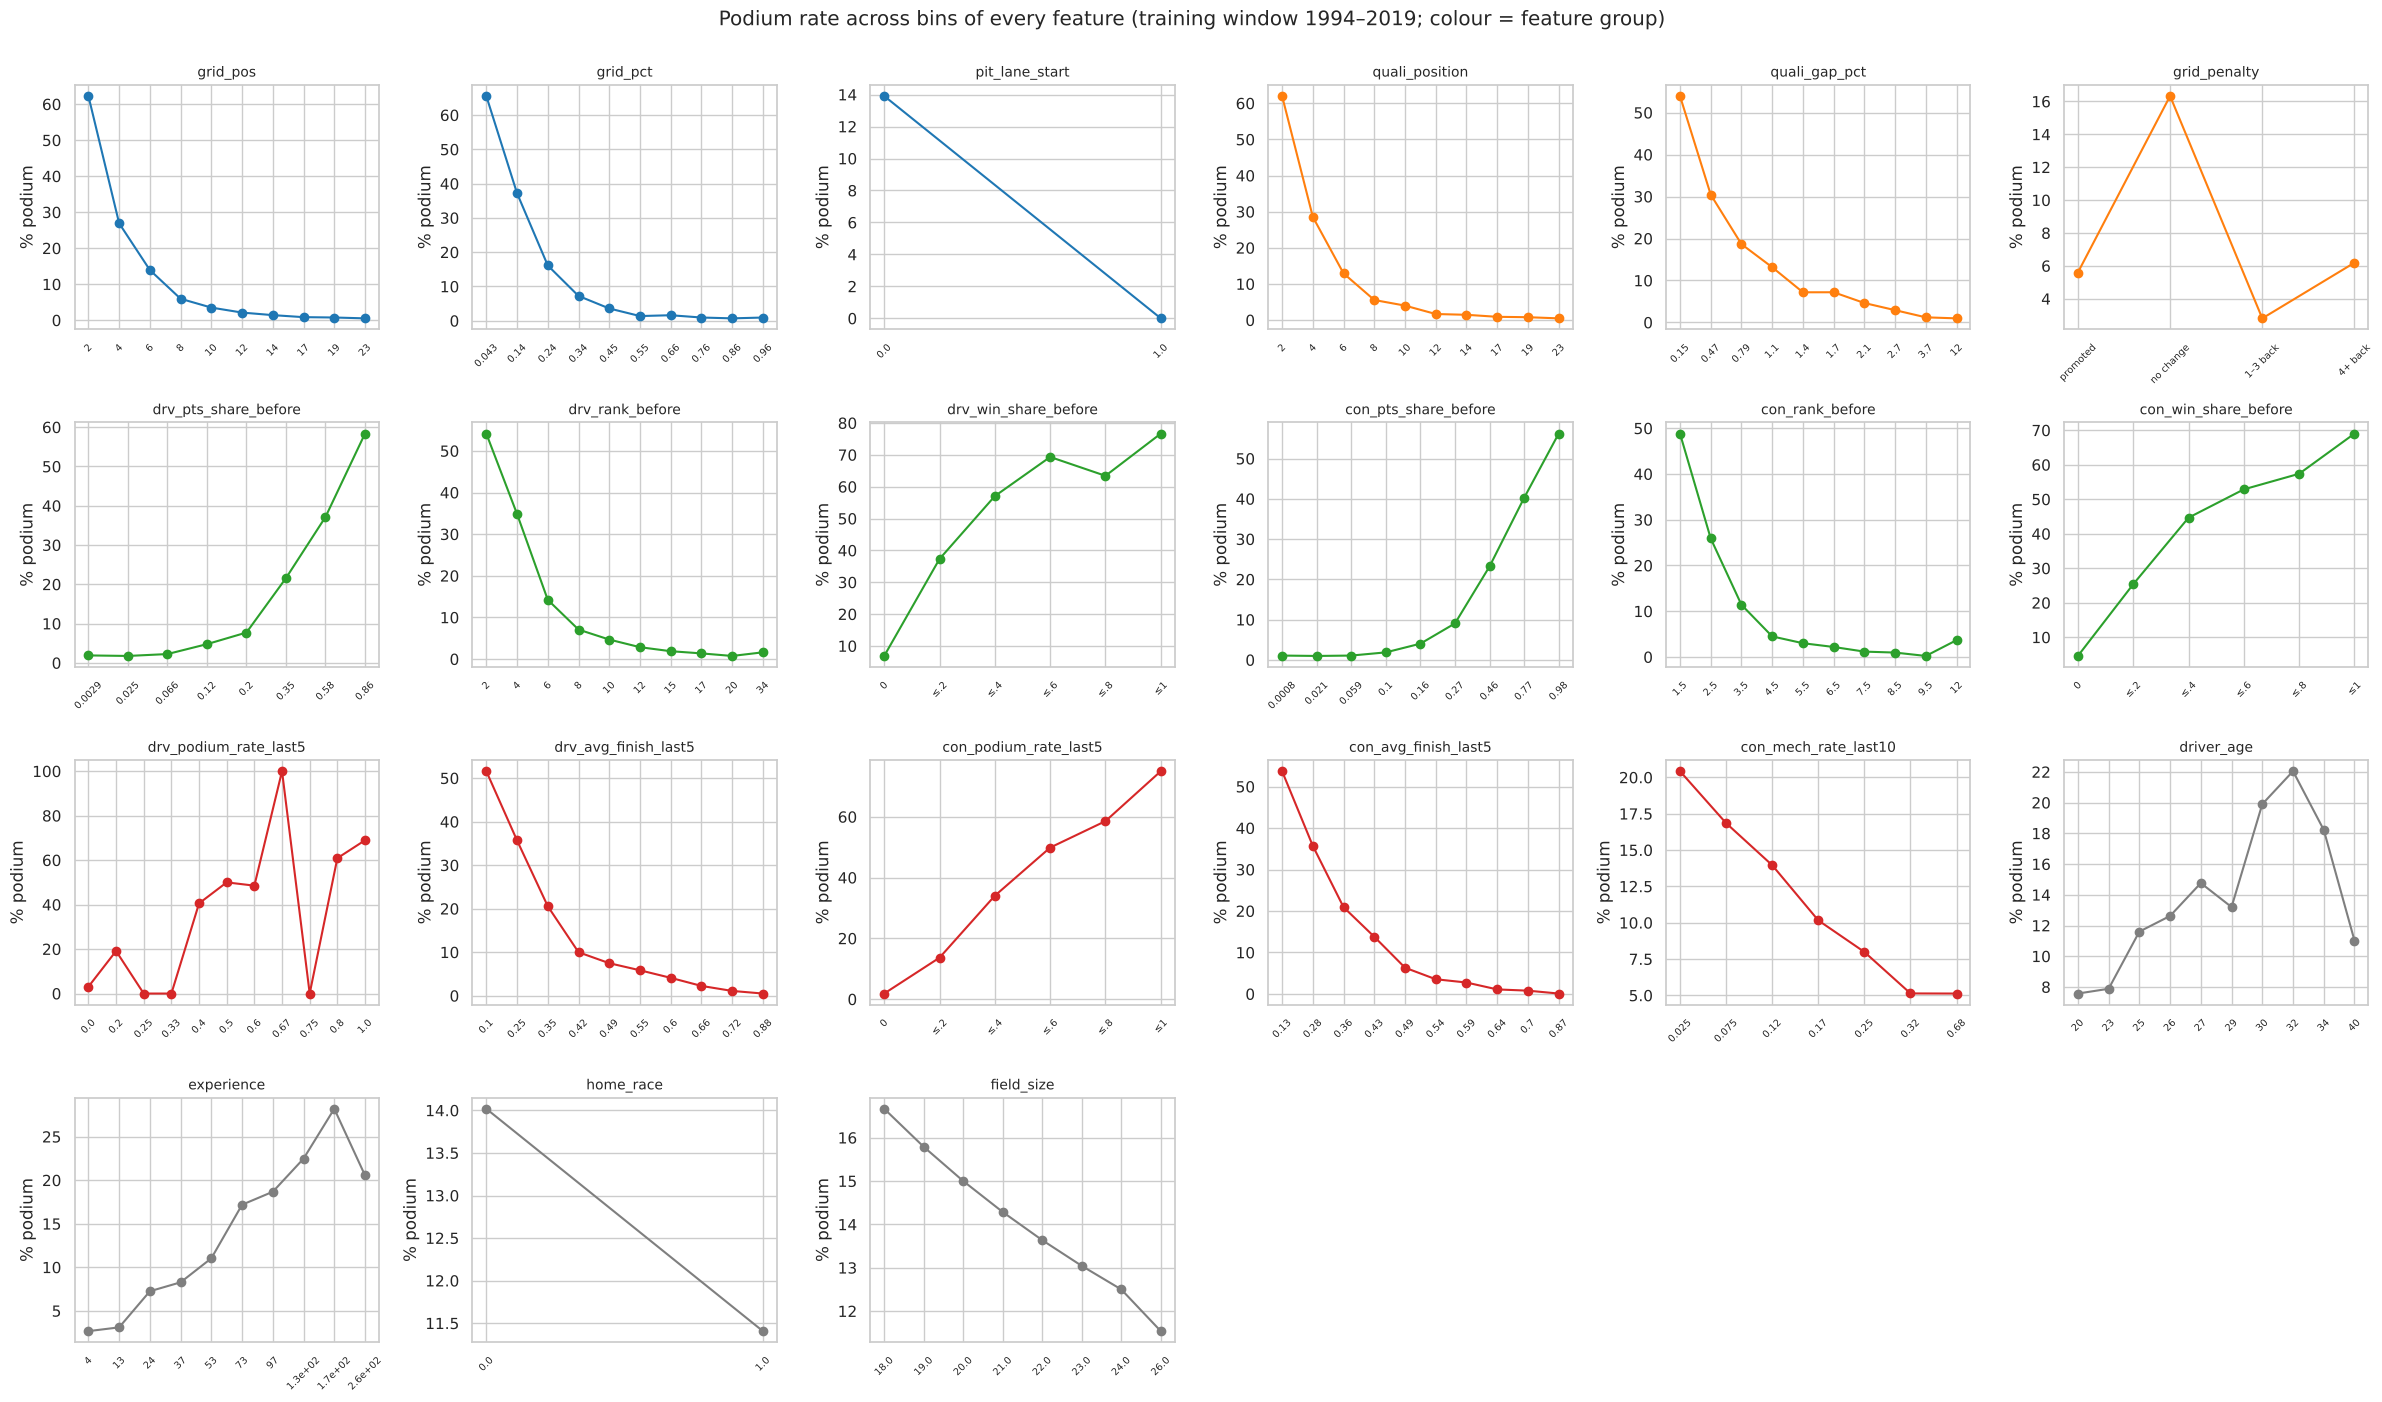

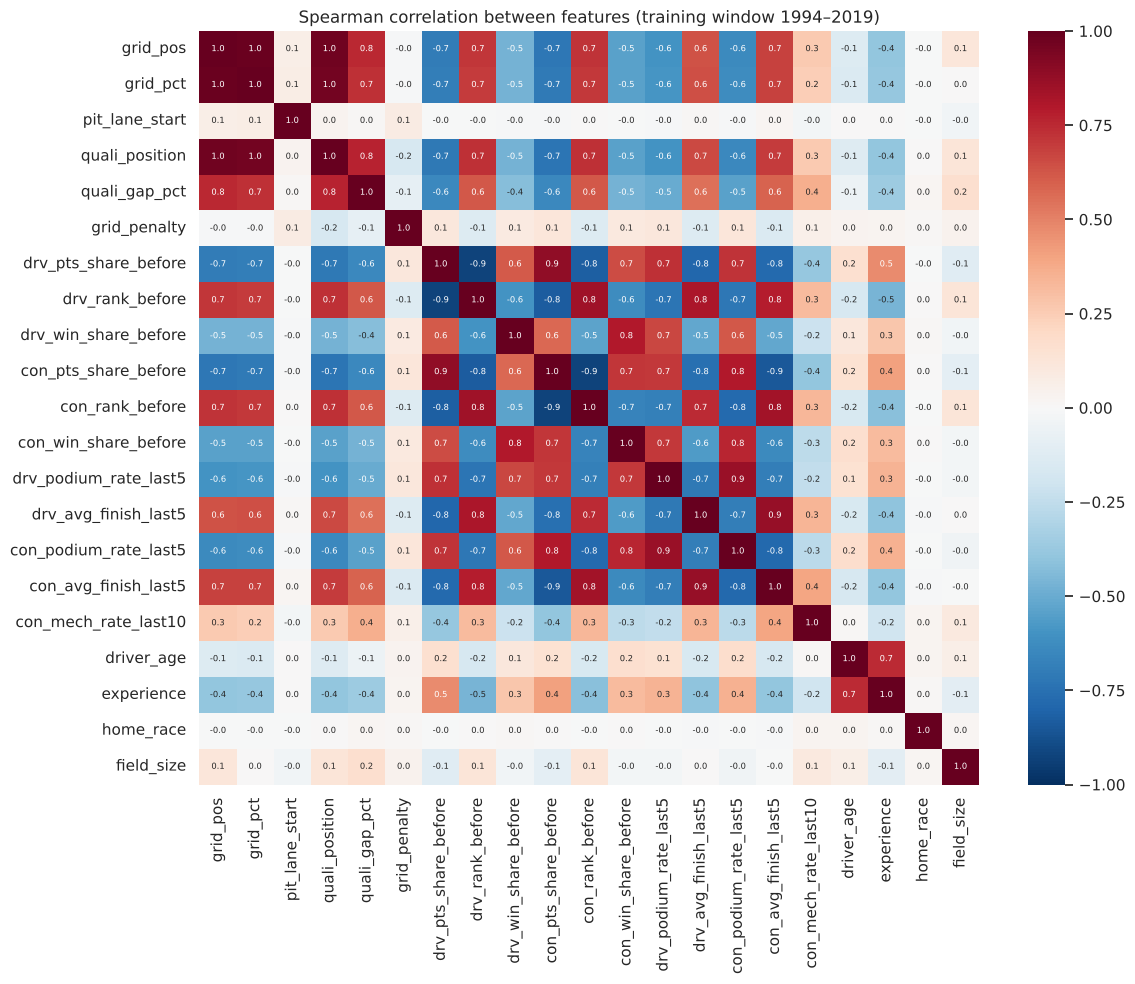

In [36]:
def bin_feature(d, c):
    """Bins that make sense for each kind of feature (flags and small integers stay as they are)."""
    if d[c].nunique() <= 12:
        return d[c].round(2)
    if c == "grid_penalty":
        return pd.cut(d[c], [-99, -1, 0, 3, 99], labels=["promoted", "no change", "1–3 back", "4+ back"])
    if c in ("drv_podium_rate_last5", "con_podium_rate_last5", "drv_win_share_before", "con_win_share_before"):
        return pd.cut(d[c], [-0.01, 0, 0.2, 0.4, 0.6, 0.8, 1.0], labels=["0", "≤.2", "≤.4", "≤.6", "≤.8", "≤1"])
    return pd.qcut(d[c], 10, duplicates="drop")

fig, axes = plt.subplots(4, 6, figsize=(24, 14))
for ax, c in zip(axes.ravel(), FEATURES):
    d = train_rows[[c, "podium"]].dropna().copy()
    d["bin"] = bin_feature(d, c)
    rate = d.groupby("bin", observed=True)["podium"].mean() * 100
    labels = [f"{iv.mid:.2g}" if hasattr(iv, "mid") else str(iv) for iv in rate.index]
    ax.plot(range(len(rate)), rate.values, marker="o", color=colors[[g for g, cs in FEATURE_GROUPS.items() if c in cs][0]])
    ax.set_xticks(range(len(rate))); ax.set_xticklabels(labels, rotation=45, fontsize=7)
    ax.set_title(c, fontsize=10); ax.set_ylabel("% podium")
for ax in axes.ravel()[len(FEATURES):]:
    ax.axis("off")
fig.suptitle("Podium rate across bins of every feature (training window 1994–2019; colour = feature group)", y=1.0)
save_fig("12_feature_bins")

corr = train_rows[FEATURES].corr(method="spearman")
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, annot=True, fmt=".1f", annot_kws={"size": 6})
ax.set_title("Spearman correlation between features (training window 1994–2019)")
save_fig("13_feature_corr")

**Missing values per season.** The plot below shows, for each feature that has missing values, the share of rows without a value in every season from the start of the training window. It shows the qualifying-coverage drift of Section 2.3 inside the training window, which is why the model gets "was missing" indicators (D19).

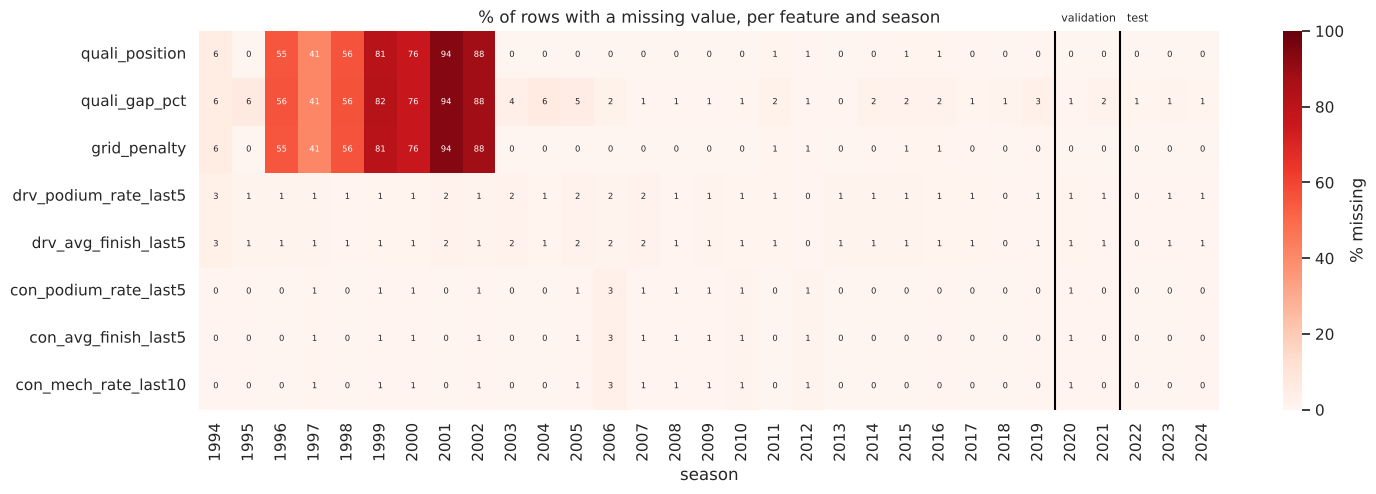

Rows without a qualifying position — 1994–2002: 53.6% | 2003–2019: 0.3% | 2020–2024: 0.0%


In [37]:
miss = model_table[model_table["year"] >= TRAIN_START].groupby("year")[FEATURES].apply(lambda d: d.isna().mean() * 100)
miss = miss.loc[:, miss.max() > 0]
fig, ax = plt.subplots(figsize=(15, 0.45 * miss.shape[1] + 1.5))
sns.heatmap(miss.T, cmap="Reds", vmin=0, vmax=100, ax=ax, cbar_kws={"label": "% missing"}, annot=miss.T.round(0), fmt=".0f",
            annot_kws={"size": 6})
for x, lab in [(TRAIN_END - TRAIN_START + 1, "validation"), (VAL_END - TRAIN_START + 1, "test")]:
    ax.axvline(x, color="black", lw=1.5); ax.text(x + 0.2, -0.2, lab, fontsize=8)
ax.set_title("% of rows with a missing value, per feature and season"); ax.set_xlabel("season"); ax.set_ylabel("")
save_fig("13b_missing_per_season")
print("Rows without a qualifying position — 1994–2002:", f"{model_table.loc[model_table['year'].between(1994, 2002), 'quali_position'].isna().mean():.1%}",
      "| 2003–2019:", f"{model_table.loc[model_table['year'].between(2003, 2019), 'quali_position'].isna().mean():.1%}",
      "| 2020–2024:", f"{model_table.loc[model_table['year'] >= 2020, 'quali_position'].isna().mean():.1%}")

**What this shows.** Qualifying is the only feature group with a large gap: inside the training window, 53.6% of the rows from 1994–2002 have no qualifying position (up to 94% in 2001), against 0.3% in 2003–2019 and none in the validation and test seasons. The model therefore learns the qualifying features mostly from 2003 on, and the "was missing" indicator it gets in Section 8 is almost always 0 when it predicts. Form features are missing only on a driver's or team's first race (about 1% of rows).

**What this shows** *(numbers from the outputs above)*

* **Starting position is the strongest single signal:** `grid_pos`, `grid_pct` and `quali_position` all reach a standalone AUC of **0.905**. On the same rows (those with qualifying data) grid and qualifying position are practically identical (0.904 vs 0.905), which is expected: they correlate almost perfectly (heatmap). We keep both because they differ exactly in the penalty cases that Q1 showed matter.
* **Most standings and form features are almost as strong (0.85–0.88)**, and they add what grid does not have: how strong the car and driver have been this season and recently.
* **Constructor features are as strong as or stronger than the driver versions** (constructor points share 0.882 vs driver 0.869; constructor podium rate 0.872 vs driver 0.849; constructor average finish 0.866 vs driver 0.845). The one exception is rank, where the driver's (0.877) is slightly above the constructor's (0.868). This supports the hypothesis that the car is the dominant factor.
* `quali_gap_pct` (0.830) is weaker alone than qualifying position: the Q1 gap separates the field well but not the very front, whose order is decided in Q3 — that order is already in `quali_position`. Win shares (0.754 and 0.817) are weaker than points shares because most drivers have zero wins.
* `con_mech_rate_last10` carries a moderate signal (0.636): unreliable teams podium less, as Q3 suggested. `experience` (0.690) helps a little.
* **Weak on their own (≈ 0.50–0.58):** `grid_penalty`, `pit_lane_start`, `home_race`, `field_size`, and `driver_age`. `grid_penalty` is not *meant* to work alone: it only matters together with qualifying position (a penalised front-row qualifier, Q1). The others are tested after training: the context group in the ablation and every weak single feature in a drop-one-feature check (Section 10), instead of us dropping them on a hunch.
* Several features overlap strongly (grid ↔ qualifying position; rank ↔ points share; driver ↔ constructor form). That is expected: they describe the same underlying strength from different angles. It means removing any single group in the ablation will cost little, because other groups can partly substitute for it.

## 7. Train / validation / test split

🔶 **Decision D18 — split by season, not by random rows.**

| split | seasons | used for |
|---|---|---|
| train | 1994–2019 (window: D17) | fitting models and preprocessing |
| validation | 2020–2021 | early stopping, hyperparameters, threshold, model selection |
| test | 2022–2024 | reported **once** at the end, never used for any choice |

Why not a random split? (1) Rows from the same race would land in both train and test, so the model would be graded on a race it partly saw. (2) Rows from 2023 would be in training while we test on 2022, which is information from the future. (3) In real use you always predict the *next* race from past races. The time split copies that.

It also makes the test meaningful: 2022 introduced new technical rules (ground-effect cars), so the test checks whether the model still works after a rule change.

Two caveats. **2020 was an unusual season** (17 races because of COVID, several circuits used twice). And because validation is used for several choices (early stopping, hyperparameters, threshold, model selection), **validation scores are slightly optimistic**; the test score is the only unbiased estimate. Model weights are fitted on 1994–2019 and frozen: the 2022–2024 test uses the same model and threshold that were chosen on 2020–2021, exactly as a model deployed at the end of 2021 would have been used.

In [38]:
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, precision_recall_curve, roc_curve, brier_score_loss, log_loss)

# DECISION D18 → see DECISIONS.md  (season-based split; training window from D17)
# Every row is assigned to a split only by its season, so a race never ends up in two splits.
def split_of(year):
    return np.select([year < TRAIN_START, year <= TRAIN_END, year <= VAL_END], ["before window", "train", "validation"], "test")
model_table["split"] = split_of(model_table["year"])

split_summary = model_table.groupby("split").agg(seasons=("year", lambda s: f"{s.min()}–{s.max()}"), races=("raceId", "nunique"),
                                                  rows=("podium", "size"), podium_rate=("podium", "mean"))
display(split_summary.loc[["before window", "train", "validation", "test"]].round(3))
assert model_table.groupby("raceId")["split"].nunique().max() == 1   # no race in two splits

train = model_table[model_table["split"] == "train"]
val = model_table[model_table["split"] == "validation"]
test = model_table[model_table["split"] == "test"]
X_train, y_train = train[FEATURES], train["podium"]
X_val, y_val = val[FEATURES], val["podium"]
X_test, y_test = test[FEATURES], test["podium"]

,seasons,races,rows,podium_rate
split,,,,
before window,1950–1993,537,12420,0.130
train,1994–2019,470,10156,0.139
validation,2020–2021,39,780,0.150
test,2022–2024,68,1359,0.150


**What this shows.** The model learns from 10,000+ rows (470 races). Validation has 39 races (780 rows) and test 68 races (1,359 rows), each with a podium base rate of about 15%. That base rate is the **PR-AUC of a random model** on these splits, so every PR-AUC we report should be read against it. Seasons before 1994 are used only for the EDA and the data-engineering questions.

### 7.1 Metrics and uncertainty

🔶 **Decision D21 — metrics.** The brief lists ROC-AUC, PR-AUC and F1 and mentions "all five metrics"; we report **ROC-AUC, PR-AUC, F1, precision and recall** which covers every metric the brief names, plus two calibration checks (**Brier score** and **log-loss**) because the inference function returns a probability.
* **Primary: PR-AUC.** Podiums are rare (~15%) and PR-AUC scores how clean the *top* of the ranking is, which is the hard part of this task. A useless model still gets ROC-AUC 0.5 but PR-AUC only ≈ 0.15, so PR-AUC exposes weak models more clearly.
* **Secondary: ROC-AUC** for overall separation of podium vs non-podium.
* **F1, precision, recall** describe the yes/no decisions at one threshold.

🔶 **Decision D22 — threshold.** For every model, the threshold is the one that maximises **F1 on the validation set**. The same threshold is then applied to train and test. The test set is never used to choose it.

🔶 **Decision D23 — uncertainty.** Validation has only 39 races, so a difference of 0.01 in PR-AUC can be luck. Every important comparison gets a **95% bootstrap interval over races**: we redraw the races of the split with replacement 1,000 times and recompute the metric (or the difference between two models on the same redrawn races). A difference whose interval includes 0 is treated as "no evidence of a difference".

In [39]:
# DECISION D21 → see DECISIONS.md  (PR-AUC primary, ROC-AUC secondary, F1/precision/recall at the threshold, calibration)
def metrics(y, p, thr):
    """All metrics. AUCs use the probabilities (the ranking); F1/precision/recall use the threshold; Brier/log-loss check calibration."""
    yhat = (p >= thr).astype(int)
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p), "F1": f1_score(y, yhat),
            "precision": precision_score(y, yhat, zero_division=0), "recall": recall_score(y, yhat),
            "Brier": brier_score_loss(y, p), "log-loss": log_loss(y, np.clip(p, 1e-6, 1 - 1e-6))}

def best_f1_threshold(y, p):
    """DECISION D22 → threshold that maximises F1 on the data given (we only ever pass validation data).
    precision_recall_curve returns one more precision/recall value than thresholds, hence f1[:-1]."""
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    return float(thr[np.nanargmax(f1[:-1])])

def race_top3_hit_rate(frame, p):
    """Domain check: in each race take the 3 highest scores; share of actual podium finishers we caught."""
    t = frame[["raceId", "podium"]].assign(p=p)
    t["r"] = t.groupby("raceId")["p"].rank(ascending=False, method="first")
    return float(t.loc[t["r"] <= 3, "podium"].sum() / t["podium"].sum())

# DECISION D23 → see DECISIONS.md  (race-level bootstrap intervals)
def race_bootstrap(frame, preds, n_boot=1000, seed=SEED):
    """PR-AUC of each prediction vector on 1,000 resamples of the races in `frame` (same resamples for every model).
    preds: dict name -> probabilities aligned with frame. Returns a DataFrame n_boot × models."""
    rng = np.random.default_rng(seed)
    race_ids = frame["raceId"].to_numpy()
    groups = pd.Series(np.arange(len(frame))).groupby(race_ids).apply(np.array)
    y = frame["podium"].to_numpy()
    out = []
    for _ in range(n_boot):
        idx = np.concatenate(groups.sample(len(groups), replace=True, random_state=int(rng.integers(1e9))).to_numpy())
        out.append({k: average_precision_score(y[idx], np.asarray(p)[idx]) for k, p in preds.items()})
    return pd.DataFrame(out)

def ci(series):
    lo, hi = np.percentile(series, [2.5, 97.5])
    return f"{lo:+.3f} to {hi:+.3f}" if (series < 0).any() else f"{lo:.3f}–{hi:.3f}"

## 8. Preprocessing and preprocessing experiments

🔶 **Decision D19 — preprocessing.**
* **Imputation: median + missing indicators.** Missing values in our table are structural (no qualifying recorded before 2003, no history yet for a debutant). The median is robust to skewed features, and the indicator columns (`missingindicator_*`) let the model learn that "missing" itself carries information instead of pretending the value was average.
* **Scaling: `StandardScaler` for logistic regression and the neural network** (both are trained by gradient steps and their penalties depend on feature scale). Tree models split on thresholds and do not need scaling, so they only get the imputer.
* Every preprocessing step is **fitted on the training set only** (`fit_transform`) and then applied unchanged to validation and test (`transform`).

The next cell builds **three versions of the data**, once, and every model in Section 9 uses the version it needs:

| version | what it is | used by |
|---|---|---|
| `X_train`, `X_val`, `X_test` | the cleaned feature table from Section 7 (may contain missing values) | nothing directly: input of the two steps below |
| `X_train_imp`, `X_val_imp`, `X_test_imp` | missing values filled + missing-indicator columns | random forest, gradient boosting (trees do not need scaling) |
| `X_train_scaled`, `X_val_scaled`, `X_test_scaled` | imputed **and** scaled | logistic regression, neural network |

21 features -> 29 columns after imputation; the added missing-value indicators are:
['missingindicator_quali_position', 'missingindicator_quali_gap_pct', 'missingindicator_grid_penalty', 'missingindicator_drv_podium_rate_last5', 'missingindicator_drv_avg_finish_last5', 'missingindicator_con_podium_rate_last5', 'missingindicator_con_avg_finish_last5', 'missingindicator_con_mech_rate_last10']
Shapes: train (10156, 29), validation (780, 29), test (1359, 29)


,missing % (raw),raw min,raw max,median used to fill,min after scaling,max after scaling
grid_pos,0.00,1.00,26.00,11.00,-1.63,2.30
grid_pct,0.00,0.00,1.00,0.50,-1.65,1.65
pit_lane_start,0.00,0.00,1.00,0.00,-0.04,22.51
quali_position,17.80,1.00,26.00,11.00,-1.79,2.55
quali_gap_pct,19.19,0.00,19.67,1.50,-1.13,10.48
grid_penalty,17.80,-9.00,23.00,0.00,-7.04,18.00
drv_pts_share_before,0.00,0.00,1.00,0.09,-0.76,2.65
drv_rank_before,0.00,1.00,47.00,11.00,-1.54,4.98
drv_win_share_before,0.00,0.00,1.00,0.00,-0.34,6.98
con_pts_share_before,0.00,0.00,1.00,0.13,-0.84,2.16


After scaling every column has mean 0 and standard deviation 1 (largest deviation: mean 3.8e-16, std 2.2e-16).


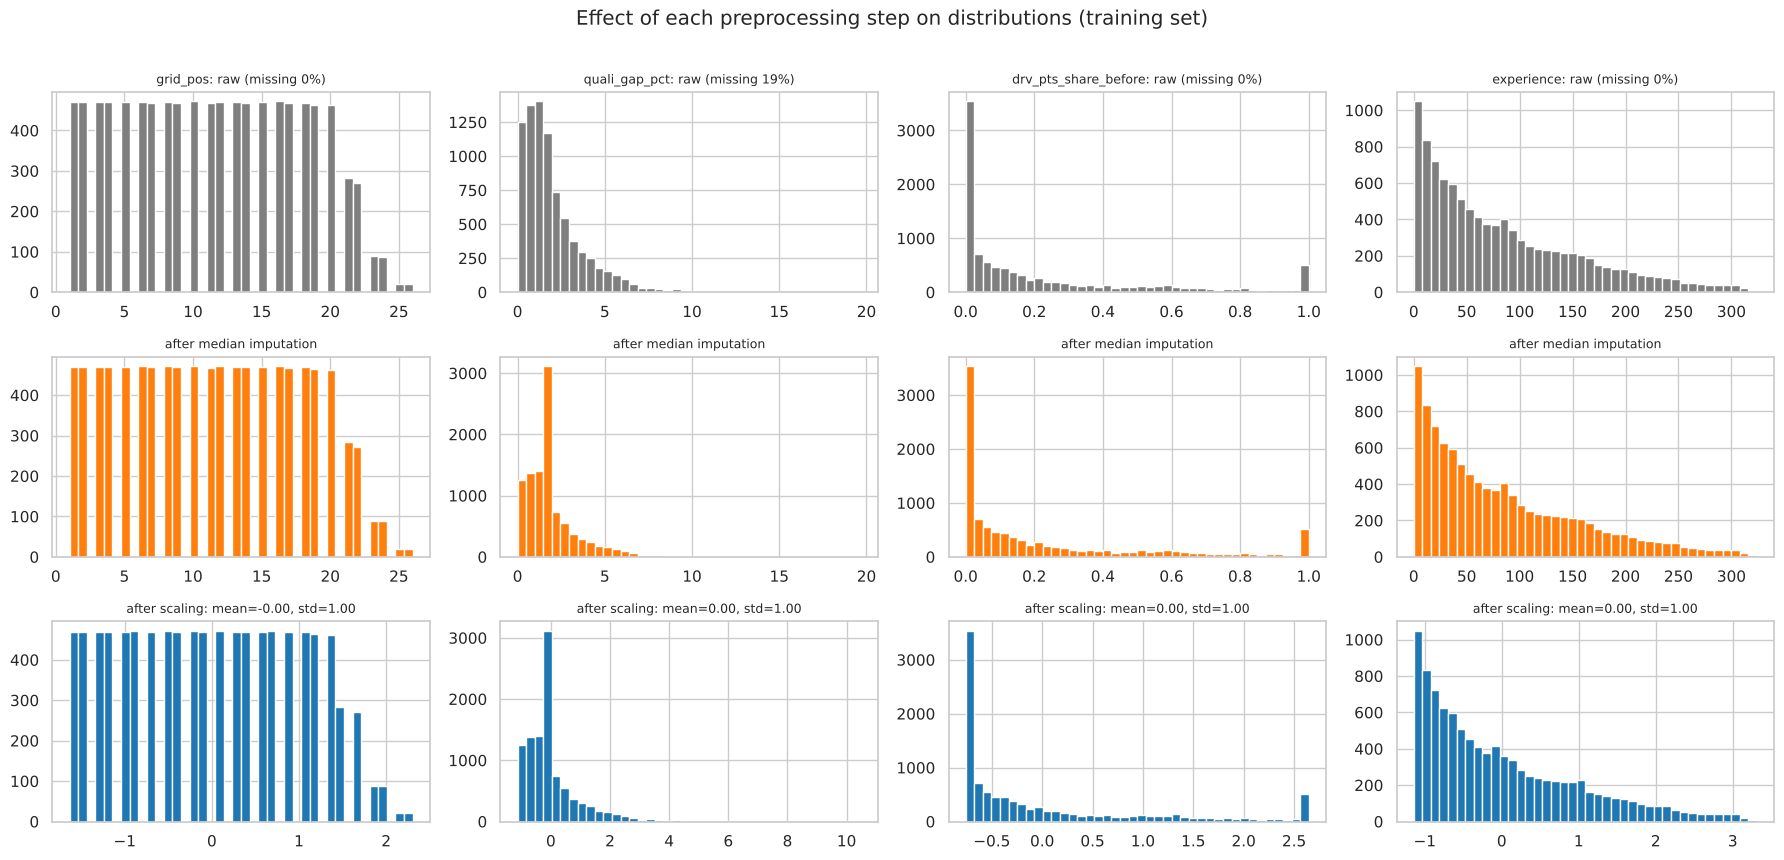

In [40]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline

# DECISION D19 → see DECISIONS.md  (median imputation + missing indicators, then scaling; fitted on the training set only)
# X_train / X_val / X_test come from Section 7. Some values are missing (NaN): no qualifying recorded before 2003,
# no form history yet for a debutant. scikit-learn's models cannot be trained on NaN, so they are filled first.

# Step 1: imputation. Learn each feature's median on the TRAINING rows, fill NaN with it,
#         and add a 0/1 "was missing" column for every feature that has missing values.
imputer = SimpleImputer(strategy="median", add_indicator=True)
X_train_imp = imputer.fit_transform(X_train)      # learn the medians on train, fill train
X_val_imp = imputer.transform(X_val)               # fill validation with the TRAINING medians
X_test_imp = imputer.transform(X_test)             # fill test with the TRAINING medians

# Step 2: scaling. Learn each column's mean and standard deviation on the TRAINING rows,
#         then replace every value by (value - mean) / std.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imp)
X_val_scaled = scaler.transform(X_val_imp)
X_test_scaled = scaler.transform(X_test_imp)

PREP_COLUMNS = list(imputer.get_feature_names_out())
print(f"{len(FEATURES)} features -> {len(PREP_COLUMNS)} columns after imputation; the added missing-value indicators are:")
print([c for c in PREP_COLUMNS if c.startswith("missingindicator")])
print(f"Shapes: train {X_train_scaled.shape}, validation {X_val_scaled.shape}, test {X_test_scaled.shape}")

# Effect of each step, per feature (training set)
Xt_imp = pd.DataFrame(X_train_imp, columns=PREP_COLUMNS, index=X_train.index)
Xt_train = pd.DataFrame(X_train_scaled, columns=PREP_COLUMNS, index=X_train.index)
assert Xt_imp.isna().sum().sum() == 0                              # imputation leaves no missing value
effect = pd.DataFrame({
    "missing % (raw)": X_train.isna().mean() * 100, "raw min": X_train.min(), "raw max": X_train.max(),
    "median used to fill": imputer.statistics_,
    "min after scaling": Xt_train[FEATURES].min(), "max after scaling": Xt_train[FEATURES].max()})
display(effect.round(2))
print(f"After scaling every column has mean 0 and standard deviation 1 (largest deviation: mean {Xt_train.mean().abs().max():.1e}, "
      f"std {(Xt_train.std(ddof=0) - 1).abs().max():.1e}).")

cols_show = ["grid_pos", "quali_gap_pct", "drv_pts_share_before", "experience"]
fig, axes = plt.subplots(3, len(cols_show), figsize=(18, 8.5))
for i, c in enumerate(cols_show):
    axes[0, i].hist(X_train[c].dropna(), bins=40, color="tab:gray")
    axes[0, i].set_title(f"{c}: raw (missing {X_train[c].isna().mean():.0%})", fontsize=9)
    axes[1, i].hist(Xt_imp[c], bins=40, color="tab:orange")
    axes[1, i].set_title("after median imputation", fontsize=9)
    axes[2, i].hist(Xt_train[c], bins=40, color="tab:blue")
    axes[2, i].set_title(f"after scaling: mean={Xt_train[c].mean():.2f}, std={Xt_train[c].std():.2f}", fontsize=9)
fig.suptitle("Effect of each preprocessing step on distributions (training set)", y=1.01)
save_fig("15_preprocessing_effect")

**What this shows.** Imputation removes every missing value; the table lists the training median used to fill each feature. For a feature with many missing values, such as `quali_gap_pct`, it creates a tall spike at the median (second row of the plot). That is why the missing-indicator columns are added: they tell the model which values in the spike were really missing. Scaling then centres every feature at 0 with standard deviation 1, so no feature dominates a linear model just because of its units (`experience` runs up to 300+, `grid_pct` stays between 0 and 1). Scaling does not change the shape of a distribution, only its position and spread.

**Preprocessing-order experiments.** We run three experiments on the order of the preprocessing steps (the brief asks for at least two). Each one changes only the order of two steps and keeps the model, the rows and the threshold rule identical. Scores are on validation; test is shown for reference only.

**How to read them.** These choices are decided by **correctness, not by score**. A wrong order can score the same as the correct one, or even higher, precisely because it uses information it should not have (future seasons, or values we made up). The scores show how large the effect is on this data and whether doing it correctly costs anything; the reason for each choice is given in its text.

### 8.1 Experiment E1 — split first, then fit preprocessing *vs* fit preprocessing first, then split

The imputer and the scaler learn statistics from the rows they are fitted on (medians, means, standard deviations). If they are fitted on **all** rows before splitting, those statistics already contain the validation and test seasons: information from 2020–2024 that a model trained at the end of 2019 could not have had. This is a subtle form of leakage. No labels leak, but the inputs are shaped by the future.


In [41]:
# Correct order: imputer and scaler fitted on the training rows only. These are X_*_scaled from the cell above.
# Leaky order: imputer and scaler fitted on train + validation + test together, before splitting.
X_all = pd.concat([X_train, X_val, X_test])
imputer_leaky = SimpleImputer(strategy="median", add_indicator=True).fit(X_all)
scaler_leaky = StandardScaler().fit(imputer_leaky.transform(X_all))
X_train_leaky = scaler_leaky.transform(imputer_leaky.transform(X_train))
X_val_leaky = scaler_leaky.transform(imputer_leaky.transform(X_val))
X_test_leaky = scaler_leaky.transform(imputer_leaky.transform(X_test))

versions = {"split → fit on train (correct)": (X_train_scaled, X_val_scaled, X_test_scaled),
            "fit on all data → split (leaky)": (X_train_leaky, X_val_leaky, X_test_leaky)}
e1 = []
for label, (A_train, A_val, A_test) in versions.items():
    model = LogisticRegression(max_iter=3000)
    model.fit(A_train, y_train)                      # the model itself is always trained on the training rows only
    p_val = model.predict_proba(A_val)[:, 1]
    p_test = model.predict_proba(A_test)[:, 1]
    thr = best_f1_threshold(y_val, p_val)            # threshold chosen on validation only (D22)
    e1.append({"order": label, "split": "validation", **metrics(y_val, p_val, thr)})
    e1.append({"order": label, "split": "test", **metrics(y_test, p_test, thr)})
display(pd.DataFrame(e1).round(4))

# Which statistics actually change when the future seasons are allowed in? (the size of the leak)
med_train = SimpleImputer(strategy="median").fit(X_train)
med_all = SimpleImputer(strategy="median").fit(X_all)
shift = pd.DataFrame({"median (train only)": med_train.statistics_, "median (all data)": med_all.statistics_,
                      "mean (train only)": X_train.mean().values, "mean (all data)": X_all.mean().values}, index=FEATURES)
display(shift[(shift.iloc[:, 0] != shift.iloc[:, 1]) | ((shift.iloc[:, 2] - shift.iloc[:, 3]).abs() > 0.01 * shift.iloc[:, 2].abs())].round(3))

,order,split,ROC-AUC,PR-AUC,F1,precision,recall,Brier,log-loss
0,split → fit on train (correct),validation,0.9337,0.7233,0.7076,0.6125,0.8376,0.0674,0.2226
1,split → fit on train (correct),test,0.9361,0.7089,0.6617,0.5312,0.8775,0.0692,0.2208
2,fit on all data → split (leaky),validation,0.9338,0.7234,0.7076,0.6125,0.8376,0.0674,0.2226
3,fit on all data → split (leaky),test,0.9361,0.7088,0.6617,0.5312,0.8775,0.0692,0.2208


,median (train only),median (all data),mean (train only),mean (all data)
grid_pos,11.000,11.000,11.371,11.220
pit_lane_start,0.000,0.000,0.002,0.006
quali_position,11.000,11.000,11.364,11.186
quali_gap_pct,1.500,1.343,2.004,1.832
grid_penalty,0.000,0.000,0.000,0.001
drv_pts_share_before,0.089,0.093,0.223,0.228
drv_rank_before,11.000,11.000,11.849,11.656
drv_win_share_before,0.000,0.000,0.046,0.046
con_pts_share_before,0.125,0.132,0.280,0.285
con_rank_before,6.000,6.000,5.955,5.879


**What this shows** *(numbers from the output above)*. With ~10,000 training rows the medians and scales barely move, so the scores are practically identical (validation PR-AUC 0.7233 vs 0.7234). The second table shows that several statistics *do* change when the future seasons are included, for example the median of `quali_gap_pct` (1.500 → 1.343) and of `experience` (62 → 71). So the leaky version uses information from after 2019, and its test score cannot judge it fairly, because the test rows helped build its preprocessing. The correct order costs nothing, so we keep it: **split first, then fit preprocessing on the training set only** (D19). With fewer rows, or with an encoding that uses the target, the same mistake could inflate scores substantially.

### 8.2 Experiment E2 — impute then scale *vs* scale then impute (logistic regression and neural network)

Both orders are leak-free as long as each step is fitted on the training rows only. They differ in which values the scaler learns from:
* **Impute → scale (our choice, and the usual order).** Missing values are first filled with the training median; the scaler then computes the mean and standard deviation over all rows, the filled ones included. The matrix the model sees has exactly mean 0 and standard deviation 1.
* **Scale → impute.** scikit-learn's `StandardScaler` ignores missing values when it computes the mean and standard deviation, and leaves them as missing in its output. The imputer then fills them with the median of the *scaled* column, which is the same median expressed in scaled units. Here the scaling statistics come from real values only.

The difference is largest for a feature with many missing values: imputing first adds many identical median values, which shrinks the standard deviation. Scaling matters most for the neural network, so we run the comparison for both model types; the network is the one used in Section 9 (two hidden layers, 32 → 16).


I0000 00:00:1791935739.083544    7022 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791935739.085151    7022 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1791935741.897909    7022 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791935741.903150    7022 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


,model,order,split,ROC-AUC,PR-AUC,F1,precision,recall,Brier,log-loss
0,logistic regression,impute → scale (our choice),validation,0.9337,0.7233,0.7076,0.6125,0.8376,0.0674,0.2226
1,logistic regression,impute → scale (our choice),test,0.9361,0.7089,0.6617,0.5312,0.8775,0.0692,0.2208
2,shallow NN (32-16),impute → scale (our choice),validation,0.9299,0.7290,0.6914,0.6667,0.7179,0.0684,0.2268
3,shallow NN (32-16),impute → scale (our choice),test,0.9353,0.7054,0.6563,0.5992,0.7255,0.0700,0.2213
4,logistic regression,scale → impute,validation,0.9329,0.7230,0.7050,0.6087,0.8376,0.0675,0.2232
5,logistic regression,scale → impute,test,0.9362,0.7082,0.6605,0.5296,0.8775,0.0692,0.2208
6,shallow NN (32-16),scale → impute,validation,0.9266,0.7204,0.6979,0.6949,0.7009,0.0696,0.2325
7,shallow NN (32-16),scale → impute,test,0.9326,0.6943,0.6458,0.6351,0.6569,0.0721,0.2263


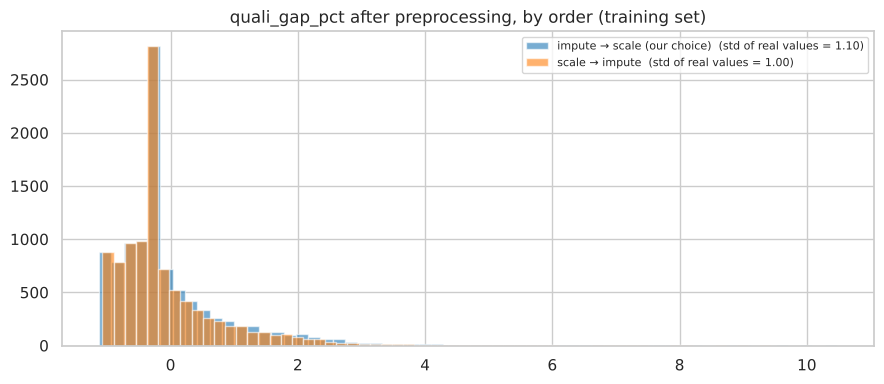

In [42]:
import tensorflow as tf
from tensorflow import keras
keras.utils.set_random_seed(SEED)

# DECISION D25 → see DECISIONS.md  (the shallow network of Section 9.3; defined here because E2 already uses it)
def build_nn(n_inputs, hidden=(32, 16), dropout=0.2, seed=SEED):
    """Input -> Dense ReLU layers (with dropout and a small L2 penalty) -> 1 sigmoid unit = podium probability."""
    keras.utils.set_random_seed(seed)                # same random start every run
    layers = [keras.Input(shape=(n_inputs,))]
    for units in hidden:
        layers += [keras.layers.Dense(units, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-4)),
                   keras.layers.Dropout(dropout)]
    net = keras.Sequential(layers + [keras.layers.Dense(1, activation="sigmoid")])
    net.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="binary_crossentropy",
                metrics=[keras.metrics.AUC(curve="PR", name="pr_auc")])
    return net

def fit_nn(net, A_train, A_val):
    """Train on the training rows; stop when validation PR-AUC stops improving and keep the best epoch's weights."""
    early_stop = keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=15, restore_best_weights=True)
    return net.fit(A_train, np.asarray(y_train), validation_data=(A_val, np.asarray(y_val)), epochs=200, batch_size=128,
                   callbacks=[early_stop], verbose=0)

# Order A (our choice), impute -> scale: X_*_scaled from the start of this section.
# Order B, scale -> impute: StandardScaler skips NaN when it learns mean and std, and keeps NaN in its output;
#          the imputer then fills them with the median of the scaled column.
scaler_b = StandardScaler()
imputer_b = SimpleImputer(strategy="median", add_indicator=True)
X_train_b = imputer_b.fit_transform(scaler_b.fit_transform(X_train))
X_val_b = imputer_b.transform(scaler_b.transform(X_val))
X_test_b = imputer_b.transform(scaler_b.transform(X_test))

versions = {"impute → scale (our choice)": (X_train_scaled, X_val_scaled, X_test_scaled),
            "scale → impute": (X_train_b, X_val_b, X_test_b)}
e2, dists = [], {}
for label, (A_train, A_val, A_test) in versions.items():
    # logistic regression
    model = LogisticRegression(max_iter=3000)
    model.fit(A_train, y_train)
    p_val, p_test = model.predict_proba(A_val)[:, 1], model.predict_proba(A_test)[:, 1]
    thr = best_f1_threshold(y_val, p_val)
    e2.append({"model": "logistic regression", "order": label, "split": "validation", **metrics(y_val, p_val, thr)})
    e2.append({"model": "logistic regression", "order": label, "split": "test", **metrics(y_test, p_test, thr)})
    # neural network (same architecture as Section 9.3)
    net = build_nn(A_train.shape[1])
    fit_nn(net, A_train, A_val)
    p_val, p_test = net.predict(A_val, verbose=0).ravel(), net.predict(A_test, verbose=0).ravel()
    thr = best_f1_threshold(y_val, p_val)
    e2.append({"model": "shallow NN (32-16)", "order": label, "split": "validation", **metrics(y_val, p_val, thr)})
    e2.append({"model": "shallow NN (32-16)", "order": label, "split": "test", **metrics(y_test, p_test, thr)})
    dists[label] = A_train[:, FEATURES.index("quali_gap_pct")]
display(pd.DataFrame(e2).round(4))

fig, ax = plt.subplots(figsize=(9, 4))
real = X_train["quali_gap_pct"].notna().values
for (label, v), col in zip(dists.items(), ["tab:blue", "tab:orange"]):
    ax.hist(v, bins=60, alpha=0.6, label=f"{label}  (std of real values = {np.std(v[real]):.2f})", color=col)
ax.set_title("quali_gap_pct after preprocessing, by order (training set)"); ax.legend(fontsize=8)
save_fig("16_impute_scale_order")

**What this shows** *(numbers from the output above)*. The order visibly changes the distribution of a feature with many missing values (`quali_gap_pct` is missing for most training rows of 1996–2002): imputing first squeezes the standard deviation, so after scaling the real values are stretched further from 0 (compare the two standard deviations in the legend). For the logistic regression the effect on the scores is negligible (validation PR-AUC 0.7233 vs 0.7230), because its weights and the missing-indicator column absorb a change of scale. For the network, impute → scale scores higher on validation (0.7290 vs 0.7204) and on test (0.7054 vs 0.6943). That gap is a little larger than the network's seed spread in 9.3 (validation 0.7257 to 0.7290), but it comes from one training run per order and is small against the uncertainty of 39 validation races, so we read it as "no sign that the other order is better" rather than as proof. We keep **impute → scale**: it is the standard order, the scaler never has to deal with missing values, and the matrix the model is trained on has exactly mean 0 and standard deviation 1.

### 8.3 Experiment E3 — derive features, then impute *vs* impute, then derive features

`grid_penalty = grid_pos − quali_position`: how many places a driver moved between qualifying and the start (positive = moved back, for example after a gearbox penalty). It is **derived** from `quali_position`, which is missing whenever no qualifying session was recorded (1,808 training rows, printed below). The question is which step comes first:
* **Derive → impute (our choice).** Without a qualifying position there is no penalty to compute, so `grid_penalty` stays **missing** in the feature table. The imputer then fills it with the training median of `grid_penalty`, which is **0** ("no change between qualifying and grid", see the table at the start of this section), and sets the indicator column `missingindicator_grid_penalty = 1`, so the model knows that this 0 was not observed.
* **Impute → derive.** The missing `quali_position` is first filled with its training median (11), and the penalty is then computed from that made-up value: `grid_penalty = grid_pos − 11`. A driver who started 22nd gets an invented penalty of +11, one who started 3rd gets −8, and nothing tells the model that these values are invented.


In [43]:
# Our order (derive -> impute): grid_penalty was computed in Section 6 from the real quali_position, so it is NaN
# wherever quali_position is NaN; the imputer of this section fills it later (median 0 + "was missing" flag).
# Wrong order (impute -> derive): fill quali_position with its training median FIRST, then recompute grid_penalty from it.
quali_median = X_train["quali_position"].median()
def impute_then_derive(X):
    X = X.copy()
    X["quali_position"] = X["quali_position"].fillna(quali_median)
    X["grid_penalty"] = X["grid_pos"] - X["quali_position"]
    return X
X_train_w, X_val_w, X_test_w = impute_then_derive(X_train), impute_then_derive(X_val), impute_then_derive(X_test)
no_quali = X_train["quali_position"].isna()
print("derive → impute (our choice): training rows whose grid_penalty value is made up =", int((X_train["grid_penalty"].notna() & no_quali).sum()))
print("impute → derive: training rows whose grid_penalty value is made up =", int((X_train_w["grid_penalty"].notna() & no_quali).sum()))

# The wrong-order table then goes through the same imputer + scaler steps (fitted on its own training rows).
imputer_w = SimpleImputer(strategy="median", add_indicator=True)
scaler_w = StandardScaler()
A_train_w = scaler_w.fit_transform(imputer_w.fit_transform(X_train_w))
A_val_w = scaler_w.transform(imputer_w.transform(X_val_w))
A_test_w = scaler_w.transform(imputer_w.transform(X_test_w))

versions = {"derive → impute (our choice)": (X_train_scaled, X_val_scaled, X_test_scaled),
            "impute → derive": (A_train_w, A_val_w, A_test_w)}
e3 = []
for label, (A_train, A_val, A_test) in versions.items():
    model = LogisticRegression(max_iter=3000)
    model.fit(A_train, y_train)
    p_val, p_test = model.predict_proba(A_val)[:, 1], model.predict_proba(A_test)[:, 1]
    thr = best_f1_threshold(y_val, p_val)
    e3.append({"order": label, "split": "validation", **metrics(y_val, p_val, thr)})
    e3.append({"order": label, "split": "test", **metrics(y_test, p_test, thr)})
display(pd.DataFrame(e3).round(4))

derive → impute (our choice): training rows whose grid_penalty value is made up = 0
impute → derive: training rows whose grid_penalty value is made up = 1808


,order,split,ROC-AUC,PR-AUC,F1,precision,recall,Brier,log-loss
0,derive → impute (our choice),validation,0.9337,0.7233,0.7076,0.6125,0.8376,0.0674,0.2226
1,derive → impute (our choice),test,0.9361,0.7089,0.6617,0.5312,0.8775,0.0692,0.2208
2,impute → derive,validation,0.9311,0.7256,0.7085,0.6234,0.8205,0.0677,0.2250
3,impute → derive,test,0.9356,0.7073,0.6654,0.5396,0.8676,0.0694,0.2214


**What this shows** *(numbers from the output above)*. Imputing before deriving invents a penalty value for all 1,808 training rows without qualifying data. On the scores the two orders are within noise: validation PR-AUC is even 0.002 higher for the wrong order (0.7256 vs 0.7233), while ROC-AUC (0.9311 vs 0.9337) and log-loss (0.2250 vs 0.2226) are slightly worse, so the overall ranking and the probabilities become a little less accurate. **Here the choice is a question of correctness more than of score:** a feature value must be either real or marked as missing, never made up. So we compute derived features from the real values first and impute afterwards (D19).


### 8.4 Training-window check (D17): is 1994 a good first training season?

D17 starts the training data in 1994 for domain reasons (Section 6). Here we test whether a different start year would give a clearly better model.

**How the check works.** We try four start years: 1950, 1980, 1994 and 2003. One validation period of 39 races is noisy, so we use **three different validation periods**: 2016–17, 2018–19 and 2020–21. For each period, a model is trained on all seasons from the start year up to the season just before the period, and scored on that period with PR-AUC. We do this with the logistic regression and with gradient boosting (both give identical results on every run, so no random seed is involved) and average the two scores.

This check trains many models on different seasons, so the steps "impute → scale → model" are packed into one scikit-learn `Pipeline` per model (`make_lr`, `make_hgb`). `pipeline.fit(X, y)` runs `fit_transform` of each step on the rows given and then fits the model; `pipeline.predict_proba(X)` runs `transform` of each step and then predicts. It does exactly what the cells above do by hand (the code checks this). The ablation in Section 10 reuses these functions.

LR                           GBM                          mean                    
validation period 2016–2017 2018–2019 2020–2021 2016–2017 2018–2019 2020–2021 2016–2017 2018–2019 2020–2021
train from                                                                                                 
1950                 0.7345    0.7077    0.7225    0.7273    0.7111    0.7158    0.7309    0.7094    0.7191
1980                 0.7265    0.7066    0.7308    0.7393    0.7218    0.6780    0.7329    0.7142    0.7044
1994                 0.7259    0.6970    0.7233    0.7393    0.7297    0.6861    0.7326    0.7133    0.7047
2003                 0.7242    0.7019    0.7314    0.6948    0.6862    0.6616    0.7095    0.6940    0.6965

Best start year per validation period: {'2016–2017': 1980, '2018–2019': 1980, '2020–2021': 1950}


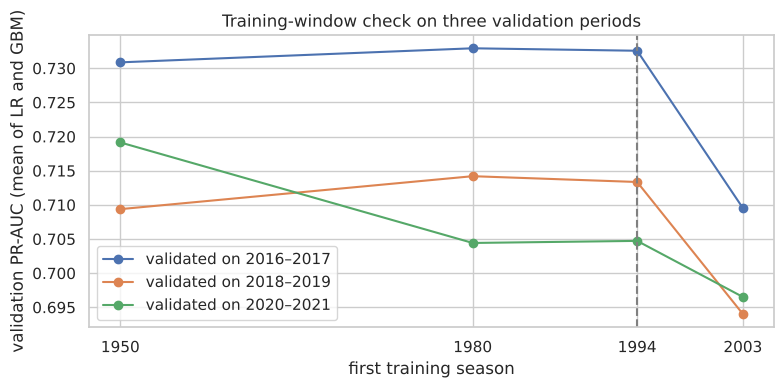

In [44]:
def make_preprocessor(scale=True):
    """The two steps of this section: imputation (+ indicators) and, for LR / NN, scaling."""
    steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]
    if scale:
        steps.append(("scale", StandardScaler()))
    return steps

def make_lr():
    """Logistic regression with its preprocessing: impute -> scale -> model."""
    return Pipeline(make_preprocessor(scale=True) + [("model", LogisticRegression(max_iter=3000))])

# DECISION D28 → see DECISIONS.md  (gradient boosting without early stopping: deterministic, no random row hold-out)
def make_hgb(**params):
    """Gradient boosting with its preprocessing: impute -> model. early_stopping is OFF: scikit-learn's default turns it on
    above 10,000 rows and then holds out a RANDOM 10% of rows, which would mix drivers of the same race (against D18)."""
    return Pipeline(make_preprocessor(scale=False) + [("model", HistGradientBoostingClassifier(early_stopping=False, random_state=SEED, **params))])

# Check: the pipeline gives exactly the same predictions as the step-by-step version.
check = LogisticRegression(max_iter=3000).fit(X_train_scaled, y_train)
assert np.allclose(make_lr().fit(X_train, y_train).predict_proba(X_val), check.predict_proba(X_val_scaled))

window_rows = []
for v0, v1 in [(2016, 2017), (2018, 2019), (2020, 2021)]:
    vfr = model_table[model_table["year"].between(v0, v1)]
    for start in [1950, 1980, 1994, 2003]:
        tr = model_table[model_table["year"].between(start, v0 - 1)]
        lr_s = average_precision_score(vfr["podium"], make_lr().fit(tr[FEATURES], tr["podium"]).predict_proba(vfr[FEATURES])[:, 1])
        hgb_s = average_precision_score(vfr["podium"], make_hgb().fit(tr[FEATURES], tr["podium"]).predict_proba(vfr[FEATURES])[:, 1])
        window_rows.append({"validation period": f"{v0}–{v1}", "train from": start, "LR": lr_s, "GBM": hgb_s, "mean": (lr_s + hgb_s) / 2})
windows = pd.DataFrame(window_rows)
display(windows.pivot(index="train from", columns="validation period", values=["LR", "GBM", "mean"]).round(4))
best_per_period = windows.loc[windows.groupby("validation period")["mean"].idxmax(), ["validation period", "train from"]]
print("Best start year per validation period:", dict(zip(best_per_period["validation period"], best_per_period["train from"])))

fig, ax = plt.subplots(figsize=(8, 4))
for vp, g in windows.groupby("validation period"):
    ax.plot(g["train from"], g["mean"], marker="o", label=f"validated on {vp}")
ax.axvline(TRAIN_START, color="gray", ls="--")
ax.set_xticks([1950, 1980, 1994, 2003]); ax.set_xlabel("first training season")
ax.set_ylabel("validation PR-AUC (mean of LR and GBM)"); ax.set_title("Training-window check on three validation periods"); ax.legend()
save_fig("14_training_window")

**What this shows** *(numbers from the output above)*. Each line in the plot is one validation period; the higher a point, the better that start year did.
* **No start year wins consistently.** 1980 is best for 2016–17 and 2018–19, and 1950 for 2020–21.
* **1994 is never clearly worse:** it is within about 0.001 of the best in the first two periods and about 0.014 behind in 2020–21. In that period the lead of 1950 comes from gradient boosting alone; for the logistic regression alone, 1950 is the weakest start year there.
* **Starting in 2003 is the worst choice in all three periods** (average of both models): dropping the 1994–2002 seasons leaves too little training data.
* The differences between 1950, 1980 and 1994 are at most about 0.015 PR-AUC, smaller than the uncertainty of a 39-race validation set.

**Conclusion.** The data does not single out one start year, but it shows that 1994 is never clearly worse than the alternatives. We keep **1994–2019** for the domain reasons in D17: 1994 is the first season with qualifying data, and the sport since then is closer to today's.


## 9. Models

All models are trained on **the same rows** (seasons 1994–2019) with **the same 21 features**, and evaluated on the same validation and test seasons, so their scores are directly comparable. Thresholds, hyperparameters and the final model are chosen on **validation only**.

**Every model cell follows the same steps:**
1. **create** the model (for example `LogisticRegression(...)`);
2. **fit** it on the training rows, using the data version it needs (Section 8): `X_train_scaled` for logistic regression and the network, `X_train_imp` for the tree models;
3. **predict** podium probabilities for train, validation and test;
4. **evaluate**: choose the decision threshold on **validation** (D22), then print every metric for train, validation and test.

The test rows are only predicted and scored, never used to fit a model or to choose anything, so reporting the test score is not leakage: it is the score of a model that never saw those seasons.

| # | model | role | how it works |
|---|---|---|---|
| 0 | grid rule | reference, no learning | score = 1 / grid slot: "the further forward you start, the likelier the podium". Tells us how much the learned models add on top of starting position. |
| 1 | logistic regression | **baseline** | computes a weighted sum of the (scaled) features, `z = w·x + b`, and turns it into a probability with the sigmoid `1 / (1 + e^(−z))`. The weights are fitted by minimising log-loss with a small L2 penalty. Each weight says how much one feature moves the log-odds of a podium, holding the others fixed. |
| 2 | random forest | statistical model | builds 400 decision trees, each on a bootstrap sample of rows and choosing among a random subset of features at every split; the predicted probability is the average of the trees' leaf podium-shares. Averaging many different trees reduces the variance of single trees. |
| 3 | gradient boosting (default) | statistical model | builds small trees one after another; each new tree is fitted to the errors (gradients of the log-loss) of the current model and added with a small learning rate. Features are binned into histograms first, which makes it fast. |
| 4 | gradient boosting (tuned) | hyperparameter attempt | the same, with settings chosen on validation from a grid of 54 combinations. |
| 5 | shallow NN, 2 hidden layers | neural network | 29 inputs → 32 → 16 ReLU units → 1 sigmoid output. Trained with backpropagation and the Adam optimiser on log-loss; dropout (randomly switching off 20% of units while training) and an L2 penalty reduce overfitting; training stops when validation PR-AUC stops improving. |

Together these are more than the three distinct modeling attempts the brief asks for (three model families, settings for the forest and a hyperparameter search for gradient boosting chosen on validation, and a neural network), each in its own cell below.

🔶 **Decision D20 — class imbalance.** Only ~14% of training rows are podiums. Balanced class weights would make each podium row count ~6× in the loss, so a model cannot just say "no podium". But weights also push every predicted probability up, so the outputs stop being real probabilities, and the inference function (Section 12) returns a probability. The logistic regression, gradient boosting and the network are therefore trained **unweighted**. For the random forest, class weights are one of the settings tried on validation (9.1). The calibration plot in 9.4 shows the effect of the weights.

In [45]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.calibration import calibration_curve

RESULTS, scores = {}, []        # per model: probabilities on each split and the threshold; and the score tables

def evaluate(name, p_train, p_val, p_test):
    """Step 4 for every model. The threshold is chosen on VALIDATION only (D22) and then used unchanged on train and test."""
    thr = best_f1_threshold(y_val, p_val)
    RESULTS[name] = {"p": {"train": p_train, "validation": p_val, "test": p_test}, "thr": thr}
    rows = []
    for split_name, frame, y, p in [("train", train, y_train, p_train), ("validation", val, y_val, p_val), ("test", test, y_test, p_test)]:
        rows.append({"model": name, "split": split_name, **metrics(y, p, thr),
                     "race top-3 hit rate": race_top3_hit_rate(frame, p),
                     "predicted podiums per race": float((p >= thr).sum() / frame["raceId"].nunique()), "threshold": thr})
    table = pd.DataFrame(rows)
    scores.append(table)
    print(f"{name}  (threshold {thr:.3f}, chosen on validation)")
    display(table.set_index("split")[["PR-AUC", "ROC-AUC", "F1", "precision", "recall", "Brier"]].round(3))

# 0. Reference rule, no learning: score = 1 / grid slot (the further forward, the higher)
evaluate("0. grid rule (no learning)", 1 / X_train["grid_pos"].values, 1 / X_val["grid_pos"].values, 1 / X_test["grid_pos"].values)

# 1. Logistic regression (the baseline). Data: imputed + scaled.
BASELINE = "1. logistic regression (baseline)"
log_reg = LogisticRegression(max_iter=3000)          # C = 1.0: scikit-learn's default, mild L2 penalty for ~10,000 rows and 29 columns
log_reg.fit(X_train_scaled, y_train)
evaluate(BASELINE,
         log_reg.predict_proba(X_train_scaled)[:, 1],
         log_reg.predict_proba(X_val_scaled)[:, 1],
         log_reg.predict_proba(X_test_scaled)[:, 1])

# The fitted imputer, scaler and model chained together, so Sections 10-12 can call lr.predict_proba(raw features).
lr = Pipeline([("impute", imputer), ("scale", scaler), ("model", log_reg)])

0. grid rule (no learning)  (threshold 0.333, chosen on validation)


,PR-AUC,ROC-AUC,F1,precision,recall,Brier
split,,,,,,
train,0.588,0.905,0.623,0.623,0.623,0.082
validation,0.639,0.910,0.692,0.692,0.692,0.083
test,0.645,0.913,0.647,0.647,0.647,0.081


1. logistic regression (baseline)  (threshold 0.218, chosen on validation)


,PR-AUC,ROC-AUC,F1,precision,recall,Brier
split,,,,,,
train,0.649,0.923,0.639,0.523,0.821,0.071
validation,0.723,0.934,0.708,0.612,0.838,0.067
test,0.709,0.936,0.662,0.531,0.877,0.069


### 9.1 Random forest: settings chosen on validation

🔶 **Decision D29** — forest settings chosen on validation; logistic regression keeps scikit-learn's default L2 strength (C = 1).

Two settings matter most for a forest on ~10,000 rows: the **minimum number of rows in a leaf** (small leaves memorise single races, large leaves smooth too much) and whether to use **class weights** (D20). We try both on validation, then check how much the chosen forest moves between random seeds.

In [46]:
# DECISION D29 → see DECISIONS.md  (forest leaf size and class weights chosen on validation; out-of-bag training score)
# Settings search: every combination is fitted on train (imputed data) and scored on validation.
rf_grid = []
for leaf in [5, 10, 20, 50, 100]:
    for cw in [None, "balanced_subsample"]:
        model = RandomForestClassifier(n_estimators=400, min_samples_leaf=leaf, max_features="sqrt", class_weight=cw, n_jobs=-1, random_state=SEED)
        model.fit(X_train_imp, y_train)
        rf_grid.append({"min_samples_leaf": leaf, "class_weight": str(cw), "val PR-AUC": average_precision_score(y_val, model.predict_proba(X_val_imp)[:, 1])})
rf_grid = pd.DataFrame(rf_grid)
display(rf_grid.pivot(index="min_samples_leaf", columns="class_weight", values="val PR-AUC").round(4))
best_rf = rf_grid.loc[rf_grid["val PR-AUC"].idxmax()]
RF_PARAMS = dict(n_estimators=400, min_samples_leaf=int(best_rf["min_samples_leaf"]), max_features="sqrt",
                 class_weight=None if best_rf["class_weight"] == "None" else best_rf["class_weight"], n_jobs=-1)
print("Chosen on validation:", RF_PARAMS)
best_by_cw = rf_grid.groupby("class_weight")["val PR-AUC"].max()
print(f"Best validation PR-AUC per class-weight setting: {best_by_cw.round(4).to_dict()}, a gap of "
      f"{best_by_cw.max() - best_by_cw.min():.3f}, inside the forest's seed spread (9.3), so that part of the choice is noise.")

# 2. Random forest with the chosen settings. Data: imputed (trees need no scaling).
rf_model = RandomForestClassifier(random_state=SEED, oob_score=True, **RF_PARAMS)
rf_model.fit(X_train_imp, y_train)
# Training score: the out-of-bag estimate (each training row predicted only by trees that did not see it).
# The in-sample score of a forest is inflated because it has memorised its training rows.
rf_oob = rf_model.oob_decision_function_[:, 1]
evaluate("2. random forest",
         rf_oob,
         rf_model.predict_proba(X_val_imp)[:, 1],
         rf_model.predict_proba(X_test_imp)[:, 1])
print(f"Random forest train PR-AUC in-sample {average_precision_score(y_train, rf_model.predict_proba(X_train_imp)[:, 1]):.3f} "
      f"vs out-of-bag {average_precision_score(y_train, rf_oob):.3f}")

rf = Pipeline([("impute", imputer), ("model", rf_model)])     # for Sections 10-12

def make_rf(seed=SEED):
    """The forest with its preprocessing, for retraining with other seeds (9.3) and in the ablation (Section 10)."""
    return Pipeline(make_preprocessor(scale=False) + [("model", RandomForestClassifier(random_state=seed, oob_score=True, **RF_PARAMS))])

class_weight,None,balanced_subsample
min_samples_leaf,,
5,0.7031,0.7074
10,0.7123,0.7175
20,0.7266,0.7239
50,0.7283,0.7322
100,0.7302,0.7291


Chosen on validation: {'n_estimators': 400, 'min_samples_leaf': 50, 'max_features': 'sqrt', 'class_weight': 'balanced_subsample', 'n_jobs': -1}
Best validation PR-AUC per class-weight setting: {'None': 0.7302, 'balanced_subsample': 0.7322}, a gap of 0.002, inside the forest's seed spread (9.3), so that part of the choice is noise.


2. random forest  (threshold 0.654, chosen on validation)


,PR-AUC,ROC-AUC,F1,precision,recall,Brier
split,,,,,,
train,0.648,0.924,0.647,0.551,0.785,0.109
validation,0.732,0.933,0.708,0.650,0.778,0.106
test,0.712,0.939,0.677,0.578,0.819,0.109


Random forest train PR-AUC in-sample 0.695 vs out-of-bag 0.648


### 9.2 Gradient boosting: default, then a hyperparameter search on validation

🔶 **Decision D28** — gradient boosting always runs with early stopping switched off (scikit-learn would otherwise hold out a random 10% of rows above 10,000 rows, mixing drivers of the same race and making results seed-dependent), and its settings come from the grid search below.

We try 54 combinations of four settings, each trained on the training seasons and scored on validation PR-AUC. The test set is not touched.

* `learning_rate`: how big a step each new tree takes (smaller = slower, more careful learning)
* `max_iter`: how many trees are added
* `max_leaf_nodes`: how complex each tree can be
* `min_samples_leaf`: the minimum number of rows in a leaf (bigger = smoother, less overfitting)

The default (`learning_rate=0.1`, `max_iter=100`, `max_leaf_nodes=31`, `min_samples_leaf=20`) is one of the 54 points, so the search can only match or beat it on validation.

3. gradient boosting (default)  (threshold 0.351, chosen on validation)


,PR-AUC,ROC-AUC,F1,precision,recall,Brier
split,,,,,,
train,0.940,0.989,0.844,0.775,0.926,0.034
validation,0.686,0.926,0.700,0.675,0.726,0.071
test,0.699,0.930,0.673,0.635,0.716,0.071


,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,val PR-AUC
7,0.01,100,7,80,0.7355
6,0.01,100,7,20,0.7349
18,0.03,50,7,20,0.7319
23,0.03,50,31,80,0.7302
19,0.03,50,7,80,0.7298
12,0.01,300,7,20,0.7280
20,0.03,50,15,20,0.7275
21,0.03,50,15,80,0.7260


Chosen on validation: {'learning_rate': 0.01, 'max_iter': 100, 'max_leaf_nodes': 7, 'min_samples_leaf': 80}


4. gradient boosting (tuned)  (threshold 0.189, chosen on validation)


,PR-AUC,ROC-AUC,F1,precision,recall,Brier
split,,,,,,
train,0.665,0.926,0.645,0.528,0.829,0.076
validation,0.736,0.928,0.706,0.625,0.812,0.078
test,0.712,0.938,0.662,0.542,0.848,0.080


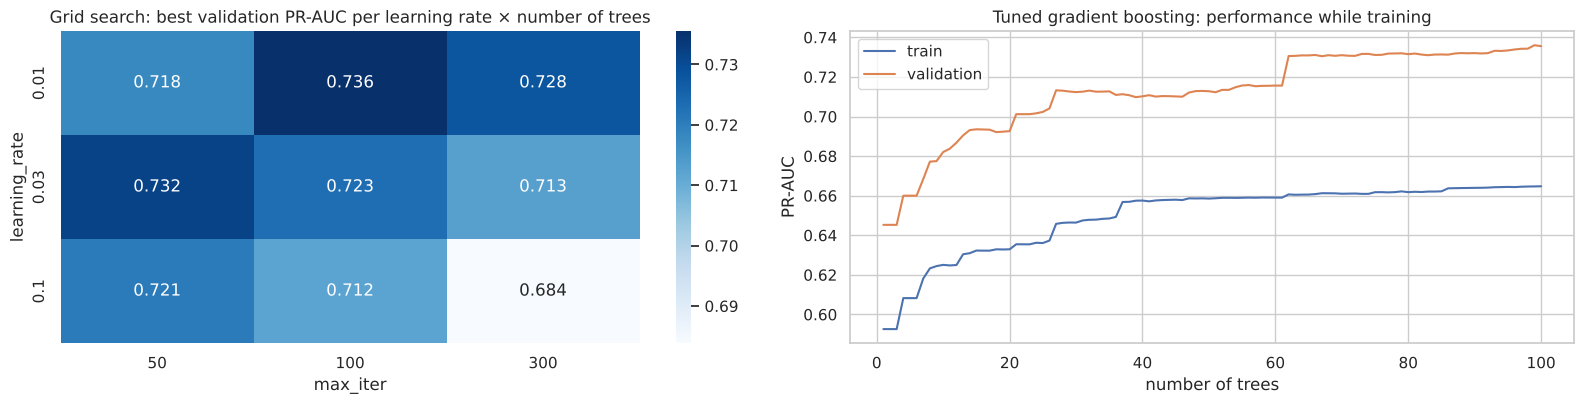

In [47]:
import itertools
# DECISION D28 → see DECISIONS.md  (early stopping off)
# 3. Gradient boosting with scikit-learn's default settings. Data: imputed (trees need no scaling).
gb_default = HistGradientBoostingClassifier(early_stopping=False, random_state=SEED)
gb_default.fit(X_train_imp, y_train)
evaluate("3. gradient boosting (default)",
         gb_default.predict_proba(X_train_imp)[:, 1],
         gb_default.predict_proba(X_val_imp)[:, 1],
         gb_default.predict_proba(X_test_imp)[:, 1])
hgb = Pipeline([("impute", imputer), ("model", gb_default)])     # for Sections 10-12

# Hyperparameter search: every combination (3 × 3 × 3 × 2 = 54) is fitted on train and scored on validation.
grid_search = []
for rate, n_trees, leaves, leaf_min in itertools.product([0.01, 0.03, 0.1], [50, 100, 300], [7, 15, 31], [20, 80]):
    params = dict(learning_rate=rate, max_iter=n_trees, max_leaf_nodes=leaves, min_samples_leaf=leaf_min)
    model = HistGradientBoostingClassifier(early_stopping=False, random_state=SEED, **params)
    model.fit(X_train_imp, y_train)
    grid_search.append({**params, "val PR-AUC": average_precision_score(y_val, model.predict_proba(X_val_imp)[:, 1])})
grid_search = pd.DataFrame(grid_search).sort_values("val PR-AUC", ascending=False)
display(grid_search.head(8).round(4))
BEST_HGB_PARAMS = {k: (float(v) if k == "learning_rate" else int(v)) for k, v in
                   grid_search.iloc[0][["learning_rate", "max_iter", "max_leaf_nodes", "min_samples_leaf"]].items()}
print("Chosen on validation:", BEST_HGB_PARAMS)

# 4. Gradient boosting with the chosen settings.
gb_tuned = HistGradientBoostingClassifier(early_stopping=False, random_state=SEED, **BEST_HGB_PARAMS)
gb_tuned.fit(X_train_imp, y_train)
evaluate("4. gradient boosting (tuned)",
         gb_tuned.predict_proba(X_train_imp)[:, 1],
         gb_tuned.predict_proba(X_val_imp)[:, 1],
         gb_tuned.predict_proba(X_test_imp)[:, 1])
hgb_tuned = Pipeline([("impute", imputer), ("model", gb_tuned)])  # for Sections 10-12

fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))
pv = grid_search.groupby(["learning_rate", "max_iter"])["val PR-AUC"].max().unstack()
sns.heatmap(pv, annot=True, fmt=".3f", cmap="Blues", ax=axes[0])
axes[0].set_title("Grid search: best validation PR-AUC per learning rate × number of trees")
# Learning curve of the tuned model: PR-AUC on train and validation after each added tree.
stage_tr = [average_precision_score(y_train, p[:, 1]) for p in gb_tuned.staged_predict_proba(X_train_imp)]
stage_va = [average_precision_score(y_val, p[:, 1]) for p in gb_tuned.staged_predict_proba(X_val_imp)]
axes[1].plot(range(1, len(stage_tr) + 1), stage_tr, label="train"); axes[1].plot(range(1, len(stage_va) + 1), stage_va, label="validation")
axes[1].set_xlabel("number of trees"); axes[1].set_ylabel("PR-AUC"); axes[1].legend()
axes[1].set_title("Tuned gradient boosting: performance while training")
save_fig("17a_gbm_search_and_curve")

**What this shows** *(numbers from the output above)*. The best settings learn **slowly and with very simple trees** (learning rate 0.01, 100 trees of at most 7 leaves). The default (learning rate 0.1, trees of 31 leaves) fits the training seasons almost perfectly (train PR-AUC 0.94, table in 9.4) but scores only 0.69 on validation: it memorises. The heatmap shows the same pattern across the grid: the more aggressive the learning (high rate, many trees), the lower the validation score. The tuned model's learning curve shows no overfitting within its 100 trees: training and validation scores rise together. Two caveats: the best point lies at the edge of the grid (the smallest learning rate and the smallest trees), which suggests that an even simpler model would do about as well — consistent with the logistic regression results below; and the best of 54 tries on 39 races is an optimistic validation score, so the test score in 9.4 is the fair one.

### 9.3 Shallow neural network

🔶 **Decision D25 — the shallow neural network.** The brief asks for a network with roughly 1–2 hidden layers and allows a standard library, so we build it with Keras (`build_nn`, defined in 8.2):

| part | our choice | in plain words |
|---|---|---|
| input | 29 columns (`X_train_scaled`) | the same imputed and scaled data as logistic regression |
| hidden layer 1 | 32 units, ReLU | each unit combines all inputs with its own weights; ReLU keeps positive values and sets negative ones to 0 |
| hidden layer 2 | 16 units, ReLU | combines the 32 patterns of layer 1 |
| output | 1 unit, sigmoid | squeezes the result into a number between 0 and 1: the probability of a podium |
| loss | binary cross-entropy | the standard loss for a yes/no prediction; no class weights (D20) |
| optimiser | Adam, learning rate 0.001, batches of 128 rows | how the weights are adjusted after each batch of rows |
| against overfitting | dropout 20% and an L2 penalty of 0.0001 on the hidden layers | dropout switches off 20% of the units at random in every training step, so the network cannot rely on single units; L2 adds a cost for large weights, keeping the network simple |
| early stopping | stop when validation PR-AUC has not improved for 15 epochs, keep the best epoch's weights | the number of epochs does not have to be guessed |
| seeds | 3 training runs (seeds 42, 1 and 2) | each run starts from different random weights; the spread shows how much the result depends on luck. The seed-42 network is the one in the comparison table |

**Why two small hidden layers:** this is inside the 1–2 layers the brief asks for, and the network has only 1,505 weights (printed below), small compared with ~10,000 training rows, which keeps overfitting in check. *Note:* Keras computes PR-AUC with an approximation, so the PR-AUC it tracks during training differs slightly from scikit-learn's exact value in the tables.


Weights the network learns: 1,505


5. shallow NN (2 hidden layers: 32-16)  (threshold 0.366, chosen on validation)


,PR-AUC,ROC-AUC,F1,precision,recall,Brier
split,,,,,,
train,0.681,0.934,0.659,0.600,0.732,0.068
validation,0.729,0.930,0.691,0.667,0.718,0.068
test,0.705,0.935,0.656,0.599,0.725,0.070


val PR-AUC                         test PR-AUC                        
                                             mean     std     min     max        mean     std     min     max
model                                                                                                        
2. random forest                           0.7343  0.0029  0.7322  0.7376      0.7129  0.0010  0.7118  0.7138
5. shallow NN (2 hidden layers: 32-16)     0.7269  0.0018  0.7257  0.7290      0.7009  0.0063  0.6937  0.7054

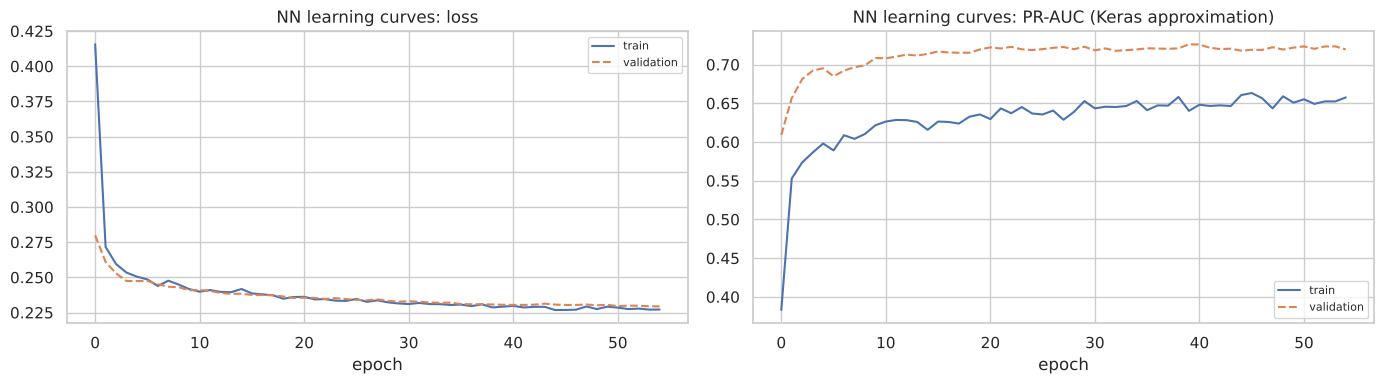

In [48]:
# DECISION D25 → see DECISIONS.md  (shallow network design; build_nn and fit_nn are defined in 8.2)
# 5. Shallow neural network. Data: imputed + scaled (the same matrices as logistic regression).
NN_NAME = "5. shallow NN (2 hidden layers: 32-16)"
seed_rows = []
for s in [SEED, 1, 2]:                                 # 3 random starts, to see how much the result depends on luck
    net = build_nn(X_train_scaled.shape[1], hidden=(32, 16), seed=s)
    history = fit_nn(net, X_train_scaled, X_val_scaled)
    seed_rows.append({"model": NN_NAME, "seed": s, "epochs": len(history.history["loss"]),
                      "val PR-AUC": average_precision_score(y_val, net.predict(X_val_scaled, verbose=0).ravel()),
                      "test PR-AUC": average_precision_score(y_test, net.predict(X_test_scaled, verbose=0).ravel())})
    if s == SEED:
        nn_model, NN_HISTORY = net, history.history     # the seed-42 network is the one evaluated below
print(f"Weights the network learns: {nn_model.count_params():,}")
evaluate(NN_NAME,
         nn_model.predict(X_train_scaled, verbose=0).ravel(),
         nn_model.predict(X_val_scaled, verbose=0).ravel(),
         nn_model.predict(X_test_scaled, verbose=0).ravel())

# Seed variability of the random models: forest and network (gradient boosting is deterministic here).
for s in [1, 2]:
    model = RandomForestClassifier(random_state=s, oob_score=True, **RF_PARAMS)
    model.fit(X_train_imp, y_train)
    seed_rows.append({"model": "2. random forest", "seed": s, "epochs": None,
                      "val PR-AUC": average_precision_score(y_val, model.predict_proba(X_val_imp)[:, 1]),
                      "test PR-AUC": average_precision_score(y_test, model.predict_proba(X_test_imp)[:, 1])})
seed_rows.append({"model": "2. random forest", "seed": SEED, "epochs": None,
                  "val PR-AUC": average_precision_score(y_val, RESULTS["2. random forest"]["p"]["validation"]),
                  "test PR-AUC": average_precision_score(y_test, RESULTS["2. random forest"]["p"]["test"])})
seeds = pd.DataFrame(seed_rows)
display(seeds.groupby("model")[["val PR-AUC", "test PR-AUC"]].agg(["mean", "std", "min", "max"]).round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(NN_HISTORY["loss"], label="train"); axes[0].plot(NN_HISTORY["val_loss"], ls="--", label="validation")
axes[1].plot(NN_HISTORY["pr_auc"], label="train"); axes[1].plot(NN_HISTORY["val_pr_auc"], ls="--", label="validation")
axes[0].set_title("NN learning curves: loss"); axes[0].set_xlabel("epoch"); axes[0].legend(fontsize=8)
axes[1].set_title("NN learning curves: PR-AUC (Keras approximation)"); axes[1].set_xlabel("epoch"); axes[1].legend(fontsize=8)
save_fig("17_nn_learning_curves")

**What the learning curves and seeds show** *(numbers from the output above)*. Loss and PR-AUC improve quickly in the first ~10 epochs and then flatten; early stopping ends training once validation PR-AUC stops improving and keeps the best epoch. Training loss keeps creeping down slowly after that point while validation loss does not, which is where more epochs would start to overfit. The seed table shows how much the network (and the forest) moves just because of its random start: differences between models smaller than that spread mean nothing.

*Why is validation PR-AUC **higher** than training PR-AUC?* It is not leakage: it happens even for the grid rule, which learns nothing (see the per-period table in 9.4). The training seasons include harder years to rank (bigger fields and patchy qualifying data in the 1990s–2000s), and PR-AUC also depends on the share of podiums, which is lower in the training seasons (13.9%) than in validation (15.0%).

### 9.4 Model comparison and selection

🔶 **Decision D24 — choosing the model for inference (validation only, with a simplicity rule).**
1. Rank the candidates by **validation PR-AUC** (the primary metric); for the random forest and the network use the **mean over seeds**, so a lucky seed does not decide.
2. If the best candidate is not the baseline, check the difference *best − baseline* with the paired race bootstrap (D23). **Only if its 95% interval lies entirely above 0 is the more complex model used.** Otherwise the baseline is used: a model must earn its extra complexity, as the brief puts it.

In [49]:
scores = pd.concat(scores, ignore_index=True)
MAIN = ["PR-AUC", "ROC-AUC", "F1", "precision", "recall", "Brier", "race top-3 hit rate", "predicted podiums per race", "threshold"]
for split_name in ["validation", "test", "train"]:
    t = scores[scores["split"] == split_name].set_index("model")[MAIN]
    if split_name == "train":
        print("TRAIN (random forest: out-of-bag estimate; others: in-sample)")
        display(t[["PR-AUC", "ROC-AUC", "F1", "Brier"]].round(3))
        continue
    b = race_bootstrap(val if split_name == "validation" else test, {n: RESULTS[n]["p"][split_name] for n in t.index})
    t.insert(1, "PR-AUC 95% CI", [ci(b[n]) for n in t.index])
    print(split_name.upper(), f"(random-model PR-AUC = base rate = {(y_val if split_name == 'validation' else y_test).mean():.3f})")
    display(t.round(3))
scores.round(4).to_csv(os.path.join(OUT_DIR, "model_comparison.csv"), index=False)

# DECISION D24 → see DECISIONS.md  (best on validation, seed-averaged; complex model only if significantly better than the baseline)
val_pr = scores[scores["split"] == "validation"].set_index("model")["PR-AUC"].drop("0. grid rule (no learning)")
seed_mean = seeds.groupby("model")["val PR-AUC"].mean()
val_pr.update(seed_mean)
print("Validation PR-AUC used for selection (seed means where applicable):"); display(val_pr.sort_values(ascending=False).round(4).to_frame())
best_candidate = val_pr.idxmax()
b = race_bootstrap(val, {"best": RESULTS[best_candidate]["p"]["validation"], "base": RESULTS[BASELINE]["p"]["validation"],
                         "grid": RESULTS["0. grid rule (no learning)"]["p"]["validation"]})
diff_lo = np.percentile(b["best"] - b["base"], 2.5)
print(f"Best candidate: {best_candidate} | best − baseline on validation: 95% CI {ci(b['best'] - b['base'])}")
print(f"Baseline − grid rule on validation: 95% CI {ci(b['base'] - b['grid'])}")
FINAL_MODEL_NAME = best_candidate if (best_candidate != BASELINE and diff_lo > 0) else BASELINE
print("→ model used for inference and explanations:", FINAL_MODEL_NAME)

VALIDATION (random-model PR-AUC = base rate = 0.150)


,PR-AUC,PR-AUC 95% CI,ROC-AUC,F1,precision,recall,Brier,race top-3 hit rate,predicted podiums per race,threshold
model,,,,,,,,,,
0. grid rule (no learning),0.639,0.541–0.745,0.910,0.692,0.692,0.692,0.083,0.692,3.000,0.333
1. logistic regression (baseline),0.723,0.613–0.837,0.934,0.708,0.612,0.838,0.067,0.667,4.103,0.218
2. random forest,0.732,0.626–0.843,0.933,0.708,0.650,0.778,0.106,0.675,3.590,0.654
3. gradient boosting (default),0.686,0.583–0.799,0.926,0.700,0.675,0.726,0.071,0.684,3.231,0.351
4. gradient boosting (tuned),0.736,0.632–0.834,0.928,0.706,0.625,0.812,0.078,0.684,3.897,0.189
5. shallow NN (2 hidden layers: 32-16),0.729,0.621–0.836,0.930,0.691,0.667,0.718,0.068,0.684,3.231,0.366


TEST (random-model PR-AUC = base rate = 0.150)


,PR-AUC,PR-AUC 95% CI,ROC-AUC,F1,precision,recall,Brier,race top-3 hit rate,predicted podiums per race,threshold
model,,,,,,,,,,
0. grid rule (no learning),0.645,0.590–0.708,0.913,0.647,0.647,0.647,0.081,0.647,3.000,0.333
1. logistic regression (baseline),0.709,0.647–0.773,0.936,0.662,0.531,0.877,0.069,0.642,4.956,0.218
2. random forest,0.712,0.656–0.772,0.939,0.677,0.578,0.819,0.109,0.637,4.250,0.654
3. gradient boosting (default),0.699,0.641–0.762,0.930,0.673,0.635,0.716,0.071,0.647,3.382,0.351
4. gradient boosting (tuned),0.712,0.650–0.770,0.938,0.662,0.542,0.848,0.080,0.642,4.691,0.189
5. shallow NN (2 hidden layers: 32-16),0.705,0.647–0.763,0.935,0.656,0.599,0.725,0.070,0.647,3.632,0.366


TRAIN (random forest: out-of-bag estimate; others: in-sample)


,PR-AUC,ROC-AUC,F1,Brier
model,,,,
0. grid rule (no learning),0.588,0.905,0.623,0.082
1. logistic regression (baseline),0.649,0.923,0.639,0.071
2. random forest,0.648,0.924,0.647,0.109
3. gradient boosting (default),0.940,0.989,0.844,0.034
4. gradient boosting (tuned),0.665,0.926,0.645,0.076
5. shallow NN (2 hidden layers: 32-16),0.681,0.934,0.659,0.068


Validation PR-AUC used for selection (seed means where applicable):


,PR-AUC
model,
4. gradient boosting (tuned),0.7355
2. random forest,0.7343
5. shallow NN (2 hidden layers: 32-16),0.7269
1. logistic regression (baseline),0.7233
3. gradient boosting (default),0.6861


Best candidate: 4. gradient boosting (tuned) | best − baseline on validation: 95% CI -0.022 to +0.043
Baseline − grid rule on validation: 95% CI 0.033–0.142
→ model used for inference and explanations: 1. logistic regression (baseline)


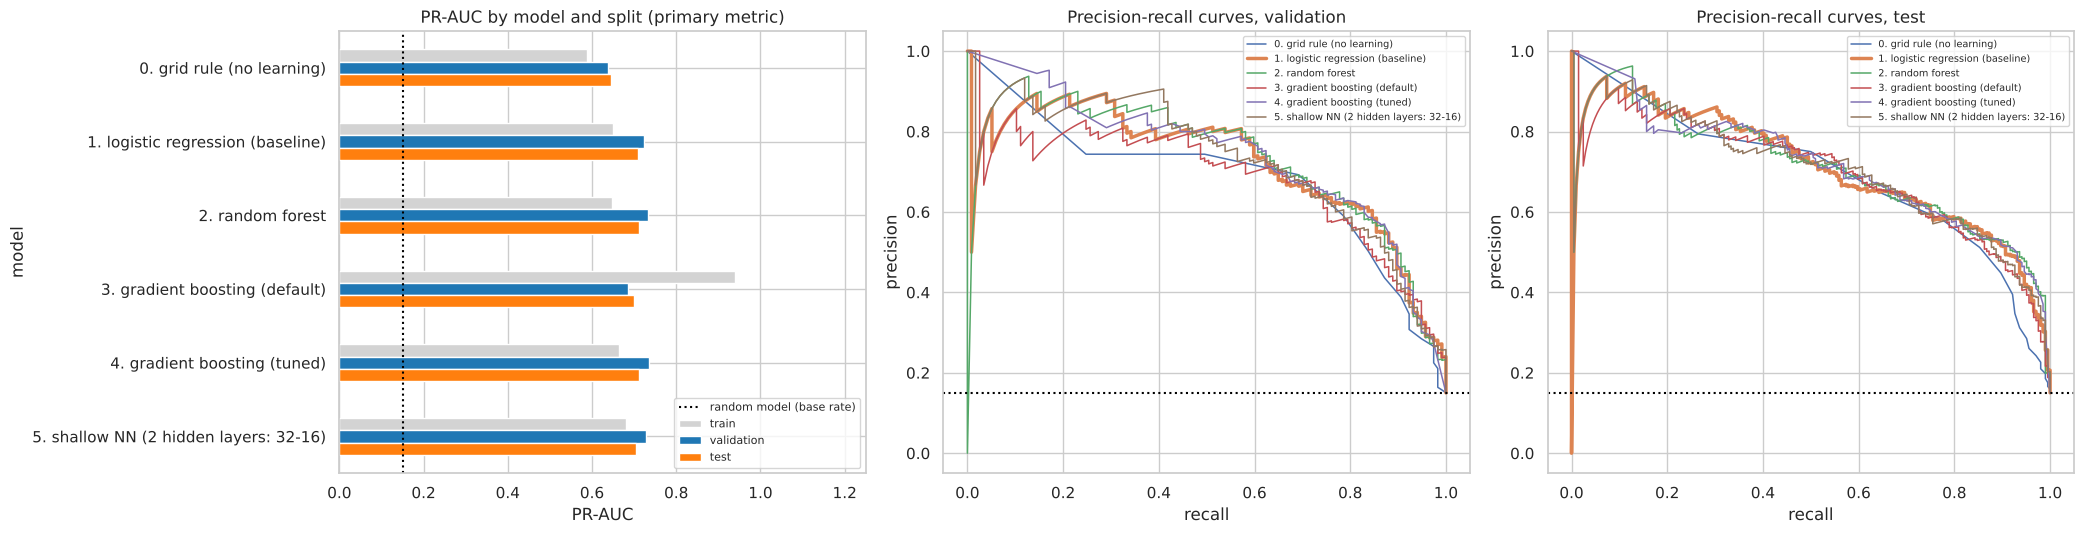

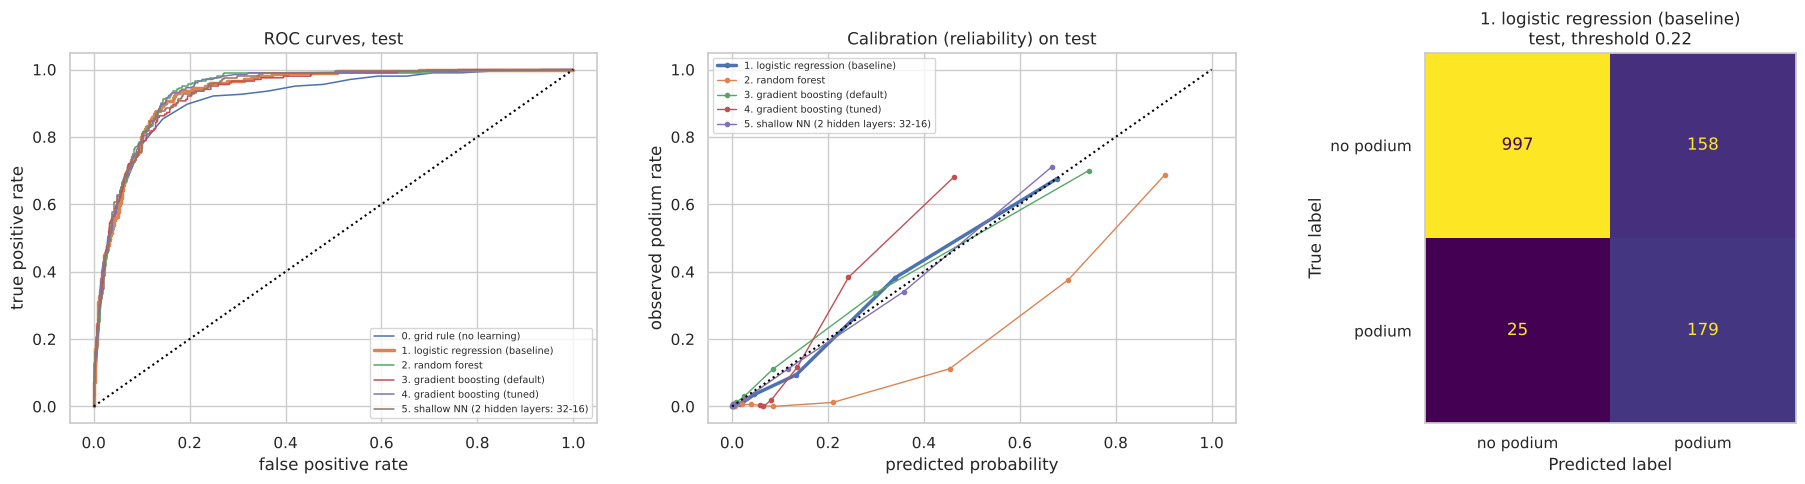

,grid-rule PR-AUC,baseline PR-AUC,podium rate,avg cars
period,,,,
1994–99,0.486,0.499,0.132,22.745
2000–04,0.579,0.692,0.143,20.965
2005–09,0.577,0.643,0.144,20.831
2010–13,0.602,0.657,0.128,23.442
2014–16,0.683,0.748,0.142,21.119
2017–19,0.701,0.703,0.150,20.000
2020–21 (val),0.639,0.723,0.150,20.000
2022–24 (test),0.645,0.709,0.150,19.985


In [50]:
fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
v = scores.pivot(index="model", columns="split", values="PR-AUC")[["train", "validation", "test"]]
v.plot(kind="barh", ax=axes[0], color=["lightgray", "tab:blue", "tab:orange"])
axes[0].axvline(y_test.mean(), color="black", ls=":", label="random model (base rate)")
axes[0].set_xlim(0, 1.25); axes[0].set_xlabel("PR-AUC"); axes[0].set_title("PR-AUC by model and split (primary metric)")
axes[0].legend(fontsize=8, loc="lower right"); axes[0].invert_yaxis()
for split_name, ax, y in [("validation", axes[1], y_val), ("test", axes[2], y_test)]:
    for name in RESULTS:
        prec, rec, _ = precision_recall_curve(y, RESULTS[name]["p"][split_name])
        ax.plot(rec, prec, lw=2.5 if name == FINAL_MODEL_NAME else 1.1, label=name)
    ax.axhline(y.mean(), color="black", ls=":")
    ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_title(f"Precision-recall curves, {split_name}"); ax.legend(fontsize=7)
save_fig("18_model_comparison")

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for name in RESULTS:
    fpr, tpr, _ = roc_curve(y_test, RESULTS[name]["p"]["test"])
    axes[0].plot(fpr, tpr, lw=2.5 if name == FINAL_MODEL_NAME else 1.1, label=name)
axes[0].plot([0, 1], [0, 1], color="black", ls=":"); axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate")
axes[0].set_title("ROC curves, test"); axes[0].legend(fontsize=7)
# Calibration: when a model says 0.7, do 70% of those drivers really podium?
for name in [n for n in RESULTS if not n.startswith("0")]:
    frac, mean_pred = calibration_curve(y_test, RESULTS[name]["p"]["test"], n_bins=8, strategy="quantile")
    axes[1].plot(mean_pred, frac, marker="o", ms=3, lw=2.5 if name == FINAL_MODEL_NAME else 1, label=name)
axes[1].plot([0, 1], [0, 1], color="black", ls=":"); axes[1].set_xlabel("predicted probability"); axes[1].set_ylabel("observed podium rate")
axes[1].set_title("Calibration (reliability) on test"); axes[1].legend(fontsize=7)
cm = confusion_matrix(y_test, RESULTS[FINAL_MODEL_NAME]["p"]["test"] >= RESULTS[FINAL_MODEL_NAME]["thr"])
ConfusionMatrixDisplay(cm, display_labels=["no podium", "podium"]).plot(ax=axes[2], colorbar=False)
axes[2].grid(False); axes[2].set_title(f"{FINAL_MODEL_NAME}\ntest, threshold {RESULTS[FINAL_MODEL_NAME]['thr']:.2f}")
save_fig("19_roc_calibration_confusion")

# Why is train PR-AUC below validation? The grid rule (no learning) shows the same pattern by period.
gr = model_table[model_table["year"] >= TRAIN_START].assign(period=lambda d: pd.cut(d["year"], [1993, 1999, 2004, 2009, 2013, 2016, 2019, 2021, 2024],
                    labels=["1994–99", "2000–04", "2005–09", "2010–13", "2014–16", "2017–19", "2020–21 (val)", "2022–24 (test)"]))
per_period = gr.groupby("period", observed=True).apply(lambda d: pd.Series({
    "grid-rule PR-AUC": average_precision_score(d["podium"], 1 / d["grid_pos"]),
    "baseline PR-AUC": average_precision_score(d["podium"], lr.predict_proba(d[FEATURES])[:, 1]),
    "podium rate": d["podium"].mean(), "avg cars": d.groupby("raceId").size().mean()}))
display(per_period.round(3))

### 9.5 Interpretation of the comparison

The full numbers are in the tables above. The key points *(all numbers from those tables)*:

* **The learned models clearly beat the grid rule, but not each other.** On validation the baseline logistic regression reaches PR-AUC **0.723** against **0.639** for the grid rule; the bootstrap interval of that difference (0.033 to 0.142) is entirely above 0, so standings, form and qualifying pace add real information on top of starting position. On the unseen test seasons it is 0.709 vs 0.645. A random model would score 0.150. (Only this baseline-vs-grid difference was tested formally; default gradient boosting, at 0.686, is the weakest learned model.)
* **Model selection (D24).** The best candidates on validation are tuned gradient boosting (0.736) and the random forest (0.734, mean of 3 seeds), about 0.01 above the baseline. But the bootstrap interval of *gradient boosting − baseline* is −0.022 to +0.043: it includes 0, so there is no evidence that the extra complexity helps. Following the rule, **the baseline logistic regression is the model used for inference and explanations.** The test seasons confirm this was not a costly choice: logistic regression 0.709, random forest 0.712, tuned gradient boosting 0.712, all well inside each other's intervals (about ±0.06).
* **Class weights (D20).** The calibration plot shows why the inference model is trained without them: the random forest, which uses balanced class weights (chosen in 9.1), predicts probabilities far above the real podium rates (validation Brier 0.106), while the logistic regression, trained without class weights, lies close to the diagonal (Brier 0.067), so its outputs can be read as probabilities.
* **Overfitting.** Default gradient boosting has a training PR-AUC of 0.940 but only 0.686 on validation; tuning removes that gap (0.665 train, 0.736 validation). The random forest's in-sample training score (0.695) is above its out-of-bag score (0.648), which is the number shown in the train table.
* **The network** scores about the same as the logistic regression (validation 0.727 averaged over 3 seeds, against 0.723; test 0.705 vs 0.709). Its random start alone moves validation PR-AUC between 0.726 and 0.729, so it shows no advantage on ~10,000 tabular rows.
* **Train lower than validation.** This happens even for the grid rule, which learns nothing (0.588 train vs 0.639 validation). The per-period table shows why: the earliest training seasons are by far the hardest to rank (grid rule 0.486 in 1994–99, against 0.68–0.70 in 2014–2019), because fields were bigger, breakdowns more frequent and qualifying data patchier.
* **Race top-3 hit rate.** Picking the three highest scores in each race, no learned model beats simply picking the first three on the grid (grid rule 0.692 on validation and 0.647 on test, learned models 0.667–0.684 and 0.637–0.647). The learned models' advantage is not in reordering the front of one grid, but in knowing **how likely** each front-runner is to podium across races (a front-row start in the dominant car vs in a midfield car), which is what PR-AUC and the Brier score reward.
* **Decisions at the threshold.** The F1-optimal threshold of the baseline is low (0.22), so it predicts about 4.1 podiums per race on validation and 5.0 on test, more than the 3 that are possible. This follows from scoring each driver independently (limitation below).

### 9.6 Strengths and limitations of each model

| model | strengths | limitations |
|---|---|---|
| logistic regression | simple, fast, deterministic; coefficients are readable; probabilities are well calibrated (trained without class weights) | assumes each feature moves the log-odds along a straight line; it cannot learn "pole matters more at Monaco" unless we build that feature |
| random forest | captures non-linear effects and interactions; robust to outliers and unscaled features | large; its in-sample score is far above its out-of-bag score (it memorises the training rows); results move with the random seed |
| gradient boosting | usually strong on tabular data; handles interactions | many hyperparameters; with fast learning and complex trees it overfits clearly (default vs tuned); tuning on a 39-race validation set is noisy |
| shallow NN | can approximate smooth non-linear functions | needs scaling and careful regularisation; results vary with the random seed; harder to explain; no advantage on ~10,000 tabular rows |

**Limitations shared by all models:** each driver is scored independently, so the model does not know that exactly three drivers podium per race (at the chosen threshold the models predict more than three podiums per race, see the table). There is no information about weather, tyres, safety cars or crashes, which cause many upsets. And the validation set is small (39 races), so model and threshold choices carry noise; the bootstrap intervals show how much.


## 10. Feature-group ablation

Section 6.7 justified each feature *before* training (hypotheses from EDA). The ablation measures each group's actual contribution *after* training: we remove one group at a time, retrain with everything else unchanged, and see how much PR-AUC drops.

We run it for two very different models, the **model used for inference** and the **best tree model**, so the conclusion does not depend on a single model type. Because a drop of 0.01 can be luck on 39 races, every change gets a **paired race-bootstrap interval** (D23): the full and the reduced model are scored on the same redrawn races. For the random forest every variant is trained with 3 seeds and averaged, so seed noise does not create fake differences.

🔶 **Decision D30 — what we do with the ablation.** A group (or feature) is removed from the final model only if removing it **improves validation PR-AUC of the inference model with a 95% interval entirely above 0**. Otherwise it stays, and we report what the ablation says about it. Test numbers are shown but never used for this decision.

Ablation models: ['1. logistic regression (baseline)', '4. gradient boosting (tuned)']


1. logistic regression (baseline)


PR-AUC            change vs all             95% CI of change                   significant           
split                   test validation          test validation              test        validation        test validation
variant                                                                                                                    
all features        0.708908    0.72332           0.0        0.0                                                           
without grid        0.698481   0.721654     -0.010427  -0.001665  -0.021 to -0.002  -0.018 to +0.014         yes         no
without qualifying  0.702674   0.715398     -0.006233  -0.007922  -0.015 to +0.001  -0.022 to +0.004          no         no
without standings   0.713498   0.712485       0.00459  -0.010835  -0.014 to +0.020  -0.027 to +0.013          no         no
without form        0.708801   0.714083     -0.000107  -0.009237  -0.014 to +0.014  -0.033 to +0.012          no         no
without context     0.711259   0.721586      0.002351  -0.001734  -0.007 to +0.009  -0.013 to +0.011          no         no
grid group only      0.64443    0.63859     -0.064478  -0.084729  -0.110 to -0.015  -0.142 to -0.033         yes        yes

4. gradient boosting (tuned)


PR-AUC            change vs all             95% CI of change                   significant           
split                   test validation          test validation              test        validation        test validation
variant                                                                                                                    
all features        0.712066   0.735542           0.0        0.0                                                           
without grid        0.685909   0.709197     -0.026157  -0.026345  -0.048 to -0.007  -0.056 to +0.005         yes         no
without qualifying  0.713106   0.716662       0.00104   -0.01888  -0.009 to +0.012  -0.038 to +0.003          no         no
without standings    0.71807   0.709812      0.006004   -0.02573  -0.015 to +0.029  -0.049 to +0.005          no         no
without form        0.710998   0.736745     -0.001068   0.001204  -0.007 to +0.004  -0.007 to +0.007          no         no
without context     0.712066   0.735542           0.0        0.0       0.000–0.000       0.000–0.000          no         no
grid group only     0.643107   0.637087     -0.068959  -0.098455  -0.099 to -0.034  -0.135 to -0.060         yes        yes

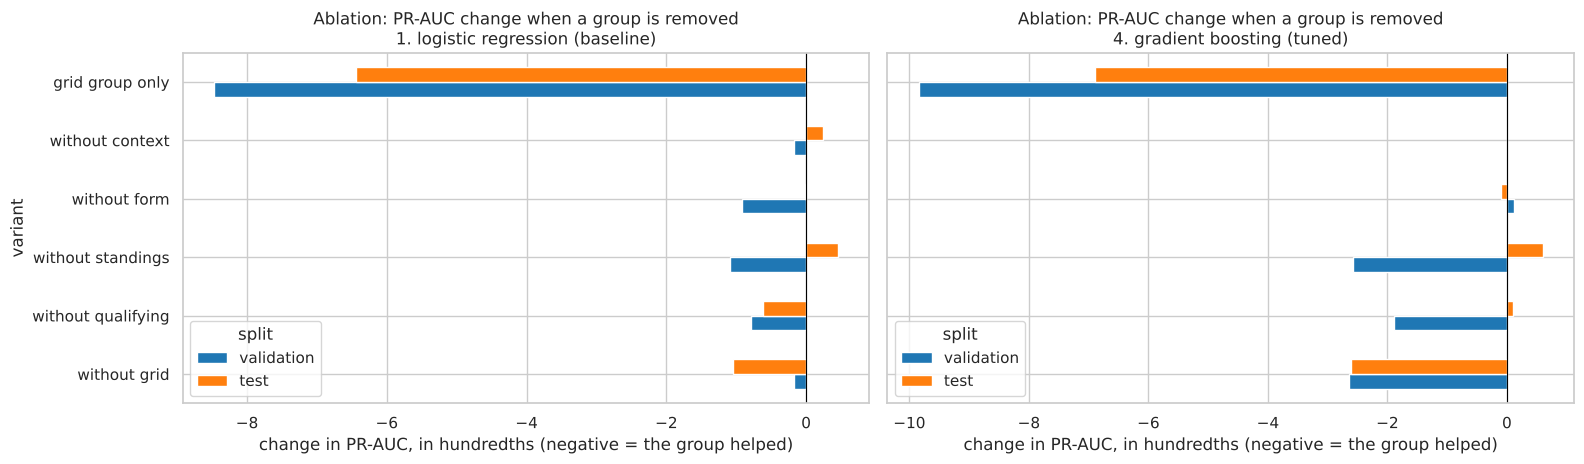

In [51]:
MAKERS = {BASELINE: lambda s=SEED: make_lr(),
          "2. random forest": lambda s=SEED: make_rf(seed=s),
          "3. gradient boosting (default)": lambda s=SEED: make_hgb(),
          "4. gradient boosting (tuned)": lambda s=SEED: make_hgb(**BEST_HGB_PARAMS)}
tree_names = ["2. random forest", "4. gradient boosting (tuned)"]
TREE_NAME = max(tree_names, key=lambda n: val_pr[n])          # best tree model on (seed-averaged) validation PR-AUC
ABLATION_MODELS = [FINAL_MODEL_NAME] + ([TREE_NAME] if TREE_NAME != FINAL_MODEL_NAME else [])
print("Ablation models:", ABLATION_MODELS)

def fit_predict(name, feats, frames, seeds=(SEED,)):
    """Train `name` on the given feature list (averaging over seeds for the random forest) and predict each frame."""
    seeds = seeds if name.startswith("2") else (SEED,)
    preds = [np.zeros(len(f)) for f in frames]
    for s in seeds:
        m = MAKERS[name](s).fit(X_train[feats], y_train)
        for i, f in enumerate(frames):
            preds[i] += m.predict_proba(f[feats])[:, 1] / len(seeds)
    return preds

# For each model: all features, without each group, and the grid group alone.
# Rows, hyperparameters and preprocessing never change, so any difference comes from the removed features.
variants = [("all features", FEATURES)] + [(f"without {g}", [f for f in FEATURES if f not in cols]) for g, cols in FEATURE_GROUPS.items()] \
           + [("grid group only", FEATURE_GROUPS["grid"])]
abl_rows, abl_preds = [], {}
for model_name in ABLATION_MODELS:
    for label, feats in variants:
        pv, pt = fit_predict(model_name, feats, [val, test], seeds=(SEED, 1, 2))
        abl_preds[(model_name, label)] = {"validation": pv, "test": pt}
    for split_name, frame in [("validation", val), ("test", test)]:
        b = race_bootstrap(frame, {lab: abl_preds[(model_name, lab)][split_name] for lab, _ in variants})
        for label, _ in variants:
            p = abl_preds[(model_name, label)][split_name]
            d = b[label] - b["all features"]
            abl_rows.append({"model": model_name, "variant": label, "split": split_name,
                             "PR-AUC": average_precision_score(frame["podium"], p),
                             "change vs all": average_precision_score(frame["podium"], p) - average_precision_score(frame["podium"], abl_preds[(model_name, "all features")][split_name]),
                             "95% CI of change": "" if label == "all features" else ci(d),
                             "significant": "" if label == "all features" else ("yes" if (np.percentile(d, 2.5) > 0 or np.percentile(d, 97.5) < 0) else "no")})
ablation = pd.DataFrame(abl_rows)
for m in ABLATION_MODELS:
    print(m); display(ablation[ablation["model"] == m].pivot(index="variant", columns="split", values=["PR-AUC", "change vs all", "95% CI of change", "significant"])
                      .reindex([v for v, _ in variants]).round(4))
ablation.to_csv(os.path.join(OUT_DIR, "ablation.csv"), index=False)

fig, axes = plt.subplots(1, len(ABLATION_MODELS), figsize=(8 * len(ABLATION_MODELS), 4.8), sharey=True)
axes = np.atleast_1d(axes)
for ax, model_name in zip(axes, ABLATION_MODELS):
    d = ablation[(ablation["model"] == model_name) & (ablation["variant"] != "all features")]
    piv = d.pivot(index="variant", columns="split", values="change vs all").reindex([v for v, _ in variants][1:])[["validation", "test"]]
    (piv * 100).plot(kind="barh", ax=ax, color=["tab:blue", "tab:orange"])
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"Ablation: PR-AUC change when a group is removed\n{model_name}")
    ax.set_xlabel("change in PR-AUC, in hundredths (negative = the group helped)")
save_fig("20_ablation")

**Single weak features.** Section 6.7 found several features that are weak on their own. The group ablation cannot test them one by one, so we drop each of them from the inference model separately.

In [52]:
weak = ["pit_lane_start", "grid_penalty", "home_race", "driver_age", "field_size", "experience"]
pv_full = abl_preds[(FINAL_MODEL_NAME, "all features")]["validation"]
one_rows, one_preds = [], {"all": pv_full}
for f in weak:
    one_preds[f] = fit_predict(FINAL_MODEL_NAME, [c for c in FEATURES if c != f], [val])[0]
b = race_bootstrap(val, one_preds)
for f in weak:
    d = b[f] - b["all"]
    one_rows.append({"feature removed": f, "val PR-AUC change": average_precision_score(y_val, one_preds[f]) - average_precision_score(y_val, pv_full),
                     "95% CI": ci(d), "significant": "yes" if (np.percentile(d, 2.5) > 0 or np.percentile(d, 97.5) < 0) else "no"})
display(pd.DataFrame(one_rows).round(4))

# DECISION D30 → see DECISIONS.md  (remove a group/feature only if that significantly improves validation PR-AUC)
to_drop = [r["variant"] for r in abl_rows if r["model"] == FINAL_MODEL_NAME and r["split"] == "validation"
           and r["variant"].startswith("without") and r["significant"] == "yes" and r["change vs all"] > 0]
to_drop += [r["feature removed"] for r in one_rows if r["significant"] == "yes" and r["val PR-AUC change"] > 0]
print("Groups/features whose removal significantly improves validation PR-AUC of the inference model:", to_drop or "none → all features stay")

,feature removed,val PR-AUC change,95% CI,significant
0,pit_lane_start,0.0000,-0.001 to +0.001,no
1,grid_penalty,0.0022,-0.006 to +0.011,no
2,home_race,0.0036,-0.000 to +0.008,no
3,driver_age,-0.0013,-0.012 to +0.011,no
4,field_size,0.0014,-0.001 to +0.006,no
5,experience,-0.0077,-0.016 to -0.000,yes


Groups/features whose removal significantly improves validation PR-AUC of the inference model: none → all features stay


**What this shows** *(numbers from the outputs above)*

* **The only large, clear effect is "grid group only":** keeping just the three grid features loses 0.085 PR-AUC on validation and 0.064 on test for the logistic regression, and 0.098 / 0.069 for gradient boosting, all with intervals far below 0. Together, the qualifying, standings, form and context groups add a lot on top of starting position.
* **Removing any single group changes little, and never significantly on validation.** For the logistic regression the validation changes are between −0.002 and −0.011, all with intervals that include 0. The groups overlap (grid ↔ qualifying, standings ↔ form, Section 6.7), so when one is removed the others take over most of its job.
* **Grid is the one group that is irreplaceable on test:** removing it costs both models significantly there (logistic regression −0.010, gradient boosting −0.026). On validation the same removal is within noise, which shows how small 39 races are.
* **Standings and qualifying matter most for gradient boosting on validation** (−0.026 and −0.019), but both intervals still include 0, and on test the effects disappear.
* **Form and context show no measurable contribution as groups.** Gradient boosting does not use the context features at all (removing them changes nothing). Our pre-training hypothesis that form would help is not confirmed. Following D30 both groups stay, because removing them does not improve validation significantly either.
* **Single weak features:** removing `experience` alone hurts significantly (−0.008, interval −0.016 to −0.000, just below 0), although removing the whole context group does not. The reason is that `experience` and `driver_age` are strongly correlated and get weights of opposite sign in the logistic regression; removed together, their effects cancel. Removing `pit_lane_start`, `grid_penalty`, `home_race`, `driver_age` or `field_size` alone changes nothing measurable. So no group or feature meets the D30 rule for removal, and the final model keeps all 21 features.

## 11. Explainability

🔶 **Decision D26 — what we explain and how.**
* We explain **the model used for inference** (`FINAL_MODEL_NAME`, chosen in 9.4), because those are the predictions a user would see. As a cross-check we also show the global SHAP picture of the best tree model, to see whether a very different model relies on the same information.
* **Global:** (1) permutation importance, per feature and per feature group, and (2) SHAP summary plots. **Local:** (3) a SHAP waterfall and (4) LIME, both for the same single prediction, so the two local methods can be compared; plus a SHAP explanation of one **wrong** prediction.
* Explanations are computed on the **test seasons (2022–2024)**: data the model never saw. Explaining does not choose anything, so using the test set here does not leak.

> ⚠️ **Explanations are not causal effects.** A feature being important means the *model relies on it to predict*. It does not mean the feature *causes* podiums. For example, `con_pts_share_before` is important because strong teams both score points and finish on podiums; giving a team points would not make its cars faster. Correlated features also share importance between them, so a single feature's importance can look smaller than the information it carries.

### 11.1 Permutation importance (global)

Shuffle one feature's values across rows (breaking its link to the target) and measure how much test PR-AUC drops. A big drop means the model depends on that feature. We also shuffle **whole groups together**, which is fairer for correlated features: shuffling only `grid_pos` still leaves `grid_pct` intact. Each shuffle is repeated 20 times; the spread shows how stable the number is (it does not include the uncertainty from having only 68 test races).

Explaining: 1. logistic regression (baseline)


,group,mean PR-AUC drop,std
0,grid,0.3405,0.0292
2,standings,0.0832,0.0201
1,qualifying,0.0163,0.0138
3,form,0.0117,0.0128
4,context,-0.0009,0.0046


,feature,mean PR-AUC drop,std,clearly above 0 (mean > 2 std)
1,grid_pct,0.1235,0.0234,True
0,grid_pos,0.0729,0.0191,True
18,experience,0.0178,0.0073,True
12,drv_podium_rate_last5,0.0129,0.0148,False
2,pit_lane_start,0.0119,0.0059,True
9,con_pts_share_before,0.0108,0.0084,False
15,con_avg_finish_last5,0.0103,0.0079,False
3,quali_position,0.0060,0.0059,False
5,grid_penalty,0.0037,0.0075,False
7,drv_rank_before,0.0019,0.0050,False


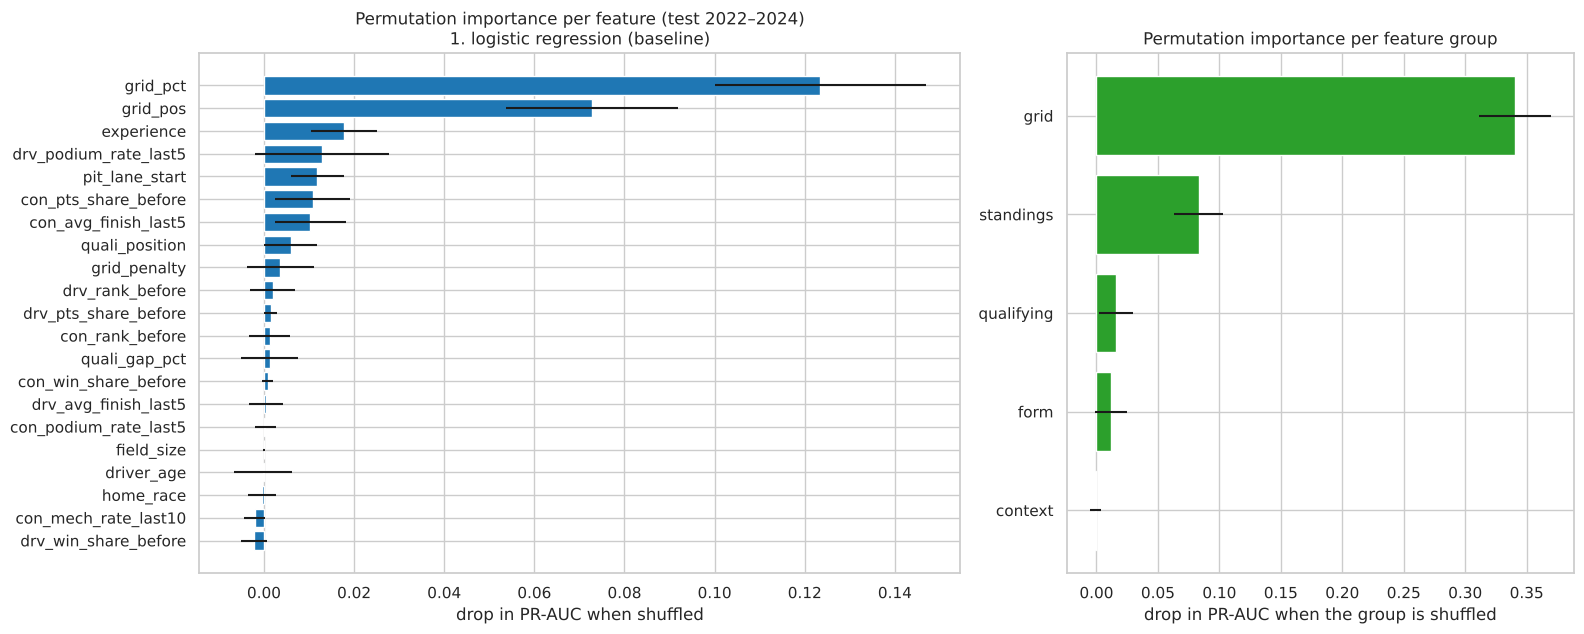

In [53]:
from sklearn.inspection import permutation_importance

# DECISION D26 → see DECISIONS.md  (explain the inference model on the unseen test seasons; cross-check with a tree model)
FINAL_PIPE = {BASELINE: lr, "2. random forest": rf,
              "3. gradient boosting (default)": hgb, "4. gradient boosting (tuned)": hgb_tuned}.get(FINAL_MODEL_NAME)
assert FINAL_PIPE is not None, "explanations below are written for a scikit-learn pipeline"
print("Explaining:", FINAL_MODEL_NAME)

# 20 repeats per feature: each repeat shuffles the column differently; we report the mean drop and its spread.
perm = permutation_importance(FINAL_PIPE, X_test, y_test, scoring="average_precision", n_repeats=20, random_state=SEED, n_jobs=-1)
perm_df = pd.DataFrame({"feature": FEATURES, "mean PR-AUC drop": perm.importances_mean, "std": perm.importances_std}).sort_values("mean PR-AUC drop", ascending=False)
perm_df["clearly above 0 (mean > 2 std)"] = perm_df["mean PR-AUC drop"] > 2 * perm_df["std"]

def group_permutation(model, X, y, groups, repeats=20):
    """Shuffle all columns of a group with the SAME row permutation, so the group is broken as a whole."""
    rng = np.random.default_rng(SEED)
    base_score = average_precision_score(y, model.predict_proba(X)[:, 1])
    out = []
    for g, cols in groups.items():
        drops = []
        for _ in range(repeats):
            Xp = X.copy()
            Xp[cols] = X[cols].values[rng.permutation(len(Xp))]
            drops.append(base_score - average_precision_score(y, model.predict_proba(Xp)[:, 1]))
        out.append({"group": g, "mean PR-AUC drop": np.mean(drops), "std": np.std(drops)})
    return pd.DataFrame(out).sort_values("mean PR-AUC drop", ascending=False)

perm_groups = group_permutation(FINAL_PIPE, X_test, y_test, FEATURE_GROUPS)
display(perm_groups.round(4))
display(perm_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [3, 2]})
p = perm_df.sort_values("mean PR-AUC drop")
axes[0].barh(p["feature"], p["mean PR-AUC drop"], xerr=p["std"], color="tab:blue")
axes[0].set_title(f"Permutation importance per feature (test 2022–2024)\n{FINAL_MODEL_NAME}"); axes[0].set_xlabel("drop in PR-AUC when shuffled")
pg = perm_groups.sort_values("mean PR-AUC drop")
axes[1].barh(pg["group"], pg["mean PR-AUC drop"], xerr=pg["std"], color="tab:green")
axes[1].set_title("Permutation importance per feature group"); axes[1].set_xlabel("drop in PR-AUC when the group is shuffled")
save_fig("21_permutation_importance")

### 11.2 SHAP (global)

SHAP splits every single prediction into contributions, one per input column, that add up from a **base value** (the model's output for an "average" row) to this row's output. For logistic regression the contributions are exact and in **log-odds** (the scale before the sigmoid). The inputs are the columns the model actually sees: the 21 features after imputation and scaling, plus the 8 missing-indicator columns.

The **beeswarm** shows every test row as a dot: horizontal position = how much that column pushed the prediction up or down; colour = the column's value (red = high, blue = low). The **bar plot** is the mean absolute contribution per column.

Background dataset has 10156 samples but max_samples=1000. Subsampling to 1000 samples for SHAP value computation. To use all samples, set max_samples=10156 when initializing the masker.


SHAP values are in log-odds units; columns explained: 29


,weight (log-odds per 1 std)
grid_pct,-0.877
grid_pos,-0.738
missingindicator_quali_gap_pct,0.712
missingindicator_quali_position,-0.318
missingindicator_grid_penalty,-0.318
con_pts_share_before,0.301
drv_podium_rate_last5,0.291
drv_rank_before,-0.237
con_avg_finish_last5,-0.221
experience,0.204


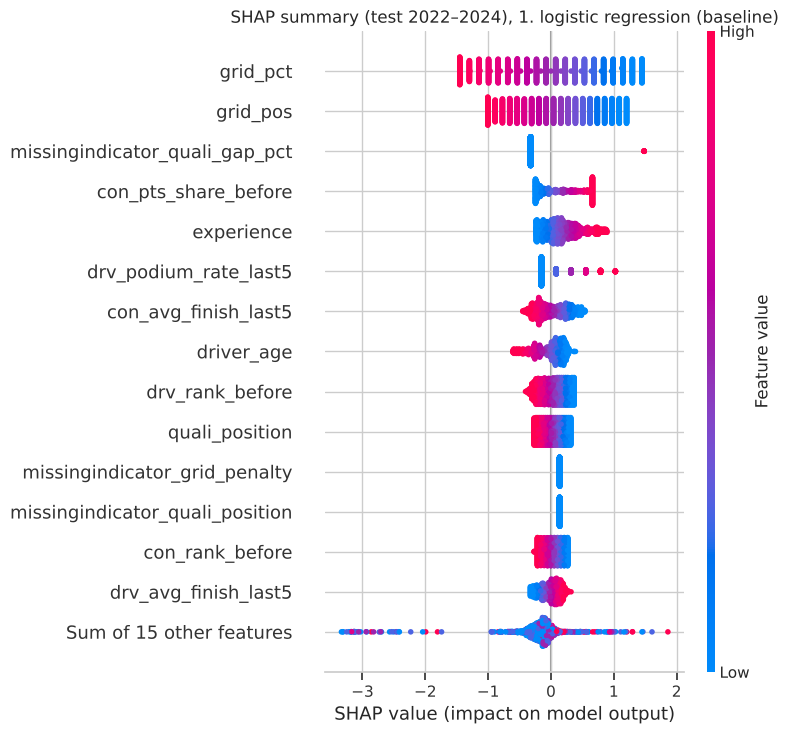

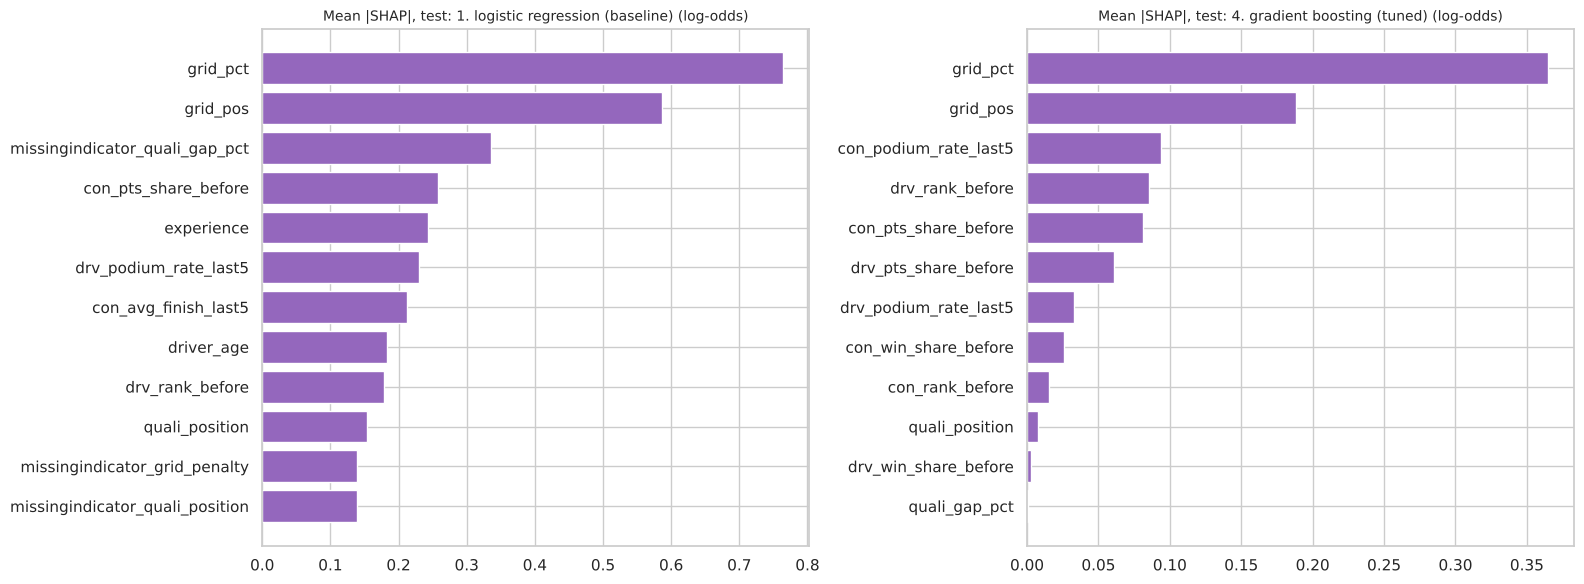

In [54]:
import shap

def shap_for(pipe, X_bg, X_explain):
    """Exact SHAP values for the last step of a pipeline: linear models -> LinearExplainer, trees -> TreeExplainer."""
    prep = Pipeline(pipe.steps[:-1])
    names = prep.get_feature_names_out()
    A_bg = pd.DataFrame(prep.transform(X_bg), columns=names)
    A_ex = pd.DataFrame(prep.transform(X_explain), columns=names, index=X_explain.index)
    model = pipe.steps[-1][1]
    if isinstance(model, LogisticRegression):
        sv = shap.LinearExplainer(model, shap.maskers.Independent(A_bg, max_samples=1000))(A_ex)
        unit = "log-odds"
    else:
        sv = shap.TreeExplainer(model)(A_ex)
        if sv.values.ndim == 3:                  # random forest: one set per class -> keep class 1 (podium)
            sv = sv[:, :, 1]
        unit = "probability" if isinstance(model, RandomForestClassifier) else "log-odds"
    return sv, A_ex, unit

shap_values, A_test, SHAP_UNIT = shap_for(FINAL_PIPE, X_train, X_test)
print("SHAP values are in", SHAP_UNIT, "units; columns explained:", A_test.shape[1])

# For a logistic regression the global picture can also be read straight from its weights (standardised inputs):
# the change in log-odds when a column rises by one standard deviation, holding all other columns fixed.
if isinstance(FINAL_PIPE.steps[-1][1], LogisticRegression):
    coefs = pd.Series(FINAL_PIPE.steps[-1][1].coef_[0], index=A_test.columns, name="weight (log-odds per 1 std)")
    display(coefs.sort_values(key=abs, ascending=False).round(3).to_frame())

plt.figure()
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title(f"SHAP summary (test 2022–2024), {FINAL_MODEL_NAME}")
save_fig("22_shap_beeswarm")

# Cross-check with the best tree model: does a very different model rely on the same information?
tree_pipe = {"2. random forest": rf, "4. gradient boosting (tuned)": hgb_tuned}[TREE_NAME]
shap_tree, _, tree_unit = shap_for(tree_pipe, X_train, X_test)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, sv, title in [(axes[0], shap_values, f"{FINAL_MODEL_NAME} ({SHAP_UNIT})"), (axes[1], shap_tree, f"{TREE_NAME} ({tree_unit})")]:
    imp = pd.Series(np.abs(sv.values).mean(axis=0), index=sv.feature_names).sort_values().tail(12)
    ax.barh(imp.index, imp.values, color="tab:purple"); ax.set_title(f"Mean |SHAP|, test: {title}", fontsize=10)
save_fig("23_shap_bar")

**What the global explanations show** *(read with the plots and tables above)*

* **Starting position dominates.** Shuffling the grid group lowers the test PR-AUC of the logistic regression by **0.34**, standings by 0.08, qualifying by 0.02, form by 0.01 and context by nothing. SHAP agrees: `grid_pct` and `grid_pos` have by far the largest contributions. The gradient-boosting cross-check (right bar chart) ranks the same top two, followed by constructor podium rate, driver rank and constructor points share, so two very different models rely on the same information: where the car starts and how strong it has been this season.
* **Group vs single feature.** Most single features show a drop that is not clearly above zero even though their group matters, because correlated partners take over when one of them is shuffled (e.g. `drv_rank_before` and `drv_pts_share_before`). This is why the group version is the fairer picture, and it matches the ablation.
* **Main directions are sensible:** a low grid slot pushes the prediction up; a high constructor points share, a recent podium habit and more experience push it up; a poor constructor average finish pushes it down.
* **Some weights point the "wrong" way, and we say so.** In the weight table, for example, `con_mech_rate_last10`, `drv_avg_finish_last5` and `quali_gap_pct` have *positive* weights (a worse value raises the prediction), and `con_podium_rate_last5` and `drv_pts_share_before` small negative ones. These are artefacts of correlated inputs: with grid, qualifying position, standings and team form already in the model, these columns only describe what is *left over*, and a linear model splits the shared information between partners, sometimes with opposite signs (age vs experience, driver vs constructor average finish). Their individual numbers should not be read as effects; only the group totals are meaningful.
* **The large `missingindicator_quali_gap_pct` bar is a near-constant offset**, not real information about the test drivers: almost every test row has a qualifying time, while about 19% of training rows did not, so SHAP (which compares each row with an average training row) gives nearly every test row the same small negative value for it.
* **`pit_lane_start` shows a sizeable permutation importance** although only a few test drivers started from the pit lane: shuffling hands the pit-lane flag to random drivers, including front-runners, which creates impossible rows that the model penalises strongly. Permutation importance can mislead on rare, strongly weighted flags.
* Again: this is how the **model** uses the features, not proof that these features **cause** podiums.

### 11.3 Local explanation of one prediction: SHAP waterfall

We pick a well-known case from the test seasons: **Max Verstappen at the 2023 Belgian GP**. He was fastest in qualifying but took a 5-place gearbox penalty, started 6th, and won. A grid-only view would rate his chances as moderate; let's see how the model reasons.

Predicted podium probability: 0.813  (actual podium = 1)


,value
grid_pos,6.000000
grid_pct,0.263158
pit_lane_start,0.000000
quali_position,1.000000
quali_gap_pct,0.181741
grid_penalty,5.000000
drv_pts_share_before,1.000000
drv_rank_before,1.000000
drv_win_share_before,0.818182
con_pts_share_before,1.000000


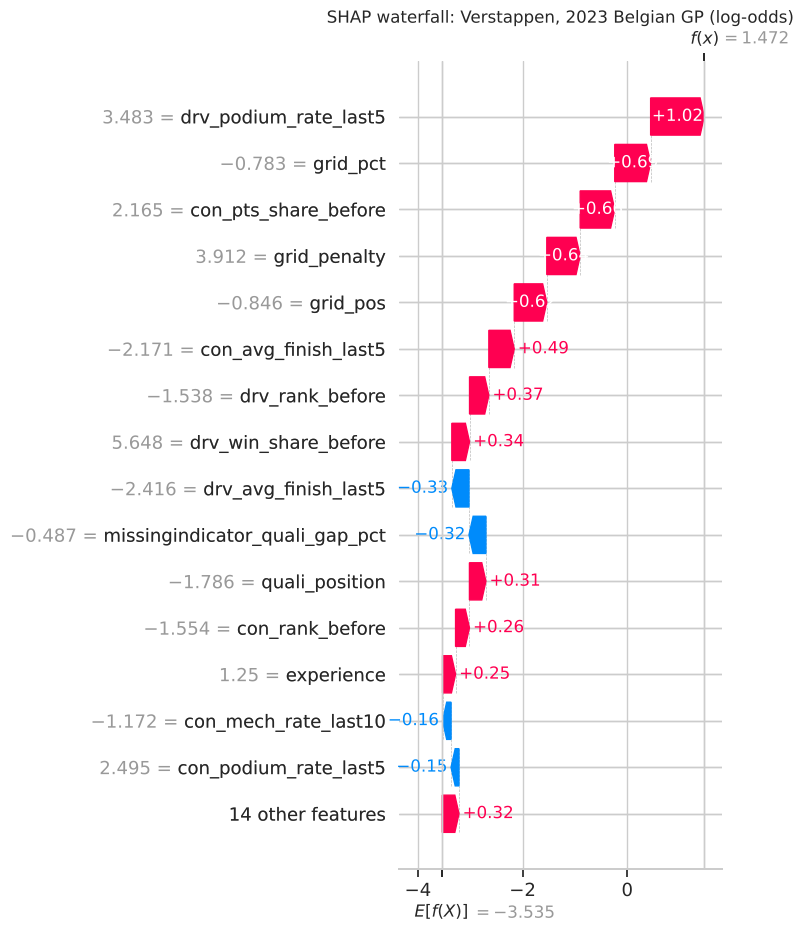

Base value: -3.535 | base + contributions: 1.472 (log-odds)


,column,model input (scaled),SHAP,group
12,drv_podium_rate_last5,3.483,1.025,form
1,grid_pct,-0.783,0.686,grid
9,con_pts_share_before,2.165,0.660,standings
5,grid_penalty,3.912,0.638,qualifying
0,grid_pos,-0.846,0.622,grid
15,con_avg_finish_last5,-2.171,0.485,form
7,drv_rank_before,-1.538,0.369,standings
8,drv_win_share_before,5.648,0.339,standings
13,drv_avg_finish_last5,-2.416,-0.328,form
22,missingindicator_quali_gap_pct,-0.487,-0.323,qualifying


Contributions summed per feature group:


,SHAP
group,
context,0.412
qualifying,0.810
form,0.853
grid,1.315
standings,1.617


,grid slot given to the model,model probability
0,1,0.898
1,6,0.813
2,10,0.713


In [55]:
# Locate the chosen driver-race (spa23 and ver were defined in Section 6.4).
ver_idx = test.index[(test["raceId"] == spa23) & (test["driverId"] == ver)][0]
ver_rec = test.loc[[ver_idx]]
prob = FINAL_PIPE.predict_proba(ver_rec[FEATURES])[0, 1]
print(f"Predicted podium probability: {prob:.3f}  (actual podium = {int(ver_rec['podium'].iloc[0])})")
display(ver_rec[FEATURES].T.rename(columns={ver_idx: "value"}))

pos = list(X_test.index).index(ver_idx)
plt.figure()
shap.plots.waterfall(shap_values[pos], max_display=16, show=False)
plt.title(f"SHAP waterfall: Verstappen, 2023 Belgian GP ({SHAP_UNIT})")
save_fig("24_shap_waterfall")

def explain_row(position):
    """Full SHAP table for one test row, plus the contributions summed per feature group."""
    t = pd.DataFrame({"column": A_test.columns, "model input (scaled)": A_test.iloc[position].values, "SHAP": shap_values.values[position]})
    t["group"] = t["column"].map(lambda c: next((g for g, cs in FEATURE_GROUPS.items() if c.replace("missingindicator_", "") in cs), "?"))
    return t.reindex(t["SHAP"].abs().sort_values(ascending=False).index), t.groupby("group")["SHAP"].sum().sort_values()

tab, by_group = explain_row(pos)
print(f"Base value: {shap_values.base_values[pos]:.3f} | base + contributions: {shap_values.base_values[pos] + shap_values.values[pos].sum():.3f} ({SHAP_UNIT})")
display(tab.head(12).round(3))
print("Contributions summed per feature group:"); display(by_group.round(3).to_frame("SHAP"))

# A model what-if (NOT causal): the same record with a different grid slot and no penalty.
what_if = []
for g in [1, 6, 10]:
    r = ver_rec[FEATURES].copy()
    r["grid_pos"] = g; r["grid_pct"] = (g - 1) / (r["field_size"].iloc[0] - 1); r["grid_penalty"] = g - r["quali_position"].iloc[0]
    what_if.append({"grid slot given to the model": g, "model probability": FINAL_PIPE.predict_proba(r)[0, 1]})
display(pd.DataFrame(what_if).round(3))

**How to read it** *(numbers from the tables above)*

* The base value **−3.54** (log-odds, about a 3% probability) is the model's output for an average training row; the contributions add up to **+1.47** log-odds, i.e. a podium probability of **0.81**. He won.
* **Summed per feature group**, everything pushes up: standings +1.617 (leading both championships), grid +1.315 (P6 is still far ahead of an average starter), form +0.853 (podiums in each of his last 5 races), qualifying +0.810, context +0.412.
* **`grid_penalty` (+0.64) pushes up, not down.** For a linear model this is logical: for a given grid slot, a large penalty means the driver's real pace was much better than the slot suggests (he qualified on pole). The model has learnt "P6 after a 5-place penalty" is a stronger position than "P6 on merit".
* Single negative bars (`drv_avg_finish_last5`, the qualifying-gap missing indicator) are artefacts of correlated or indicator columns (see 11.2): the indicator's −0.32 only says that this row, unlike about 19% of training rows, *has* a qualifying time. Their group totals are positive.
* **What-if (model behaviour, not causal):** given P1 instead of P6, the model would say 0.90; given P10, 0.71. Starting position moves the prediction, but the season-strength features keep it high in every case.

Most confident miss: Verstappen, 2024 Australian Grand Prix — probability 0.909, started 1, finished 19 (Brakes)


,SHAP
group,
qualifying,0.163
context,0.443
form,0.870
standings,1.697
grid,2.659


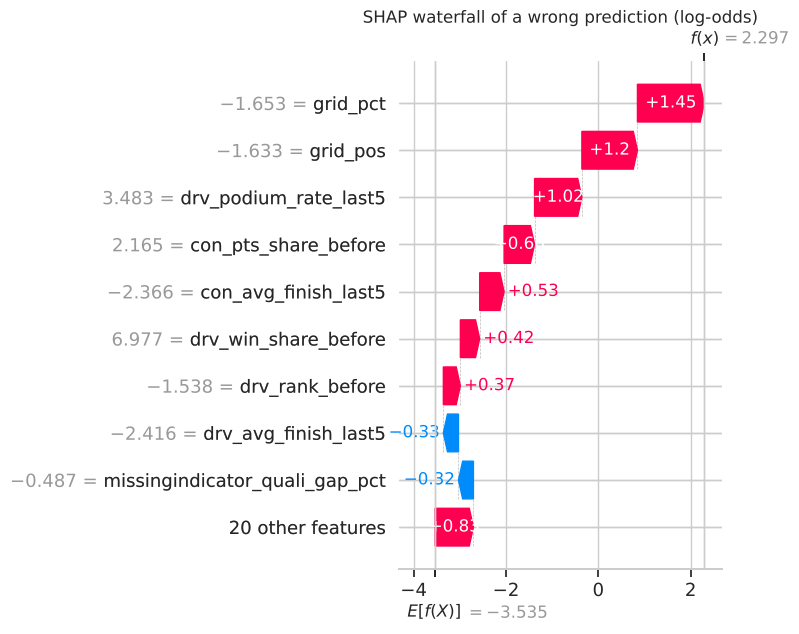

In [56]:
# One WRONG prediction: the test row the model was most confident about that did NOT end on the podium.
p_test = FINAL_PIPE.predict_proba(X_test)[:, 1]
fp_pos = int(np.argmax(np.where(y_test.values == 0, p_test, -1)))
fp_rec = test.iloc[[fp_pos]].merge(df["drivers"][["driverId", "surname"]], on="driverId").merge(
    df["races"][["raceId", "name"]], on="raceId").merge(results_clean[["raceId", "driverId", "status", "finish_rank"]], on=["raceId", "driverId"])
print(f"Most confident miss: {fp_rec['surname'].iloc[0]}, {int(fp_rec['year'].iloc[0])} {fp_rec['name'].iloc[0]} — "
      f"probability {p_test[fp_pos]:.3f}, started {int(fp_rec['grid_pos'].iloc[0])}, finished {int(fp_rec['finish_rank'].iloc[0])} ({fp_rec['status'].iloc[0]})")
tab_fp, by_group_fp = explain_row(fp_pos)
display(by_group_fp.round(3).to_frame("SHAP"))
plt.figure()
shap.plots.waterfall(shap_values[fp_pos], max_display=10, show=False)
plt.title(f"SHAP waterfall of a wrong prediction ({SHAP_UNIT})")
save_fig("24b_shap_waterfall_miss")

**What the wrong prediction shows** *(numbers from the output above)*

The model's most confident mistake in the test seasons is **Verstappen at the 2024 Australian GP**: pole position, leading both championships, probability **0.91**, and he retired with a brake failure. Every feature group pushed the prediction up (grid +2.66, standings +1.70, form +0.87 log-odds). Nothing in the pre-race data could have announced a component failure, which is exactly the kind of upset our limitations section describes: the model ranks the field well but cannot foresee breakdowns or crashes.

### 11.4 Local explanation of the same prediction: LIME

LIME explains one prediction differently. It creates thousands of slightly changed copies of the row, asks the model for their predictions, and fits a small **linear model** around this one point; that local model's weights are the explanation. Two things to know when reading it:
* LIME describes each feature by a **range** (by default the quartiles of the training data, e.g. `grid_pos ≤ 6`), not by its exact value, and changes features **independently**, so some of its synthetic rows are combinations that never happen (e.g. pole position in a back-marker car).
* It is random: we run it with **5 seeds** and report how stable the result is, and we print the local model's own prediction next to the real model's prediction.

LIME needs complete numeric rows, so missing values are filled with the training medians before perturbing.

,seed,local model R²,LIME local prediction,model probability
0,42,0.308,0.284,0.813
1,0,0.304,0.260,0.813
2,1,0.288,0.252,0.813
3,2,0.309,0.279,0.813
4,3,0.288,0.268,0.813


,mean weight,seeds in top 10
grid_pos <= 6.00,0.063,5
grid_penalty > 0.00,0.057,5
drv_podium_rate_last5 > 0.20,0.038,5
pit_lane_start <= 0.00,0.037,5
con_pts_share_before > 0.44,0.030,5
experience > 127.00,0.022,5
con_avg_finish_last5 <= 0.37,0.020,5
drv_rank_before <= 6.00,0.020,5
home_race <= 0.00,0.016,4
quali_position <= 7.00,0.016,4


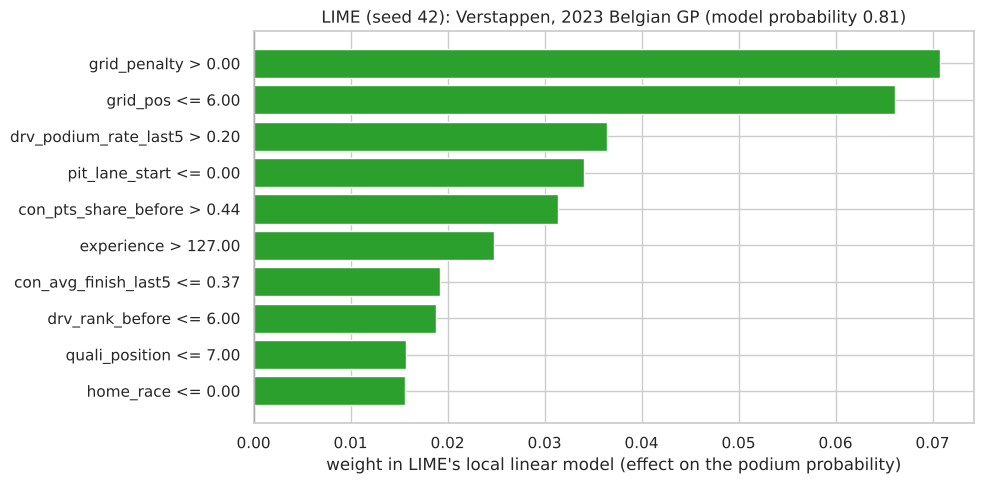

In [57]:
from lime.lime_tabular import LimeTabularExplainer

# LIME samples new rows around the instance using the training data statistics, which must not contain NaN.
median_filler = SimpleImputer(strategy="median").fit(X_train)
lime_train = median_filler.transform(X_train)

def predict_for_lime(arr):
    """LIME passes a numpy array; the pipeline expects a DataFrame with our column names."""
    return FINAL_PIPE.predict_proba(pd.DataFrame(arr, columns=FEATURES))

lime_runs, lime_stats = {}, []
for s in [SEED, 0, 1, 2, 3]:
    expl = LimeTabularExplainer(lime_train, feature_names=FEATURES, class_names=["no podium", "podium"],
                                mode="classification", discretize_continuous=True, random_state=s)
    # 5,000 perturbed copies of the row are scored by the model; LIME fits a weighted linear model to those scores.
    e = expl.explain_instance(median_filler.transform(ver_rec[FEATURES])[0], predict_for_lime, num_features=10, num_samples=5000)
    lime_runs[s] = dict(e.as_list())
    lime_stats.append({"seed": s, "local model R²": e.score, "LIME local prediction": e.local_pred[0], "model probability": prob})
display(pd.DataFrame(lime_stats).round(3))

stab = pd.DataFrame(lime_runs)
stab = stab.assign(**{"seeds in top 10": stab.notna().sum(axis=1), "mean weight": stab.mean(axis=1)}).sort_values("mean weight", key=abs, ascending=False)
display(stab[["mean weight", "seeds in top 10"]].round(3))

lime_df = pd.Series(lime_runs[SEED]).sort_values()
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(lime_df.index, lime_df.values, color=np.where(lime_df.values > 0, "tab:green", "tab:red"))
ax.axvline(0, color="black", lw=0.8)
ax.set_title(f"LIME (seed {SEED}): Verstappen, 2023 Belgian GP (model probability {prob:.2f})")
ax.set_xlabel("weight in LIME's local linear model (effect on the podium probability)")
save_fig("25_lime")

**SHAP vs LIME for this prediction** *(numbers from the outputs above)*

* **Direction agrees.** LIME's largest positive weights (`grid_pos ≤ 6`, `grid_penalty > 0`, recent podium rate, constructor points share, high experience, good constructor average finish, top-6 championship rank) are the same features SHAP pointed to, with the same direction, and they appear in the top 10 for all 5 seeds.
* **But LIME's local model fits this point badly.** Its R² is only about 0.3, and its own prediction for this row is about **0.25–0.28** while the real model says **0.81**. The reason is LIME's sampling: it draws synthetic rows from the whole training distribution (mostly midfield and back-marker cars with near-zero podium chances) and fits one straight line through them, which cannot follow the sigmoid's steep rise near this row. Its weights therefore describe the model's behaviour over a broad region, not at this exact point.
* **SHAP is the more trustworthy local explanation here.** For a logistic regression, SHAP values are exact and add up to the model's output, while LIME is an approximation that, in this case, is visibly poor. Where both agree — starting near the front, the penalty signalling real pace, and season-long strength drive this prediction — we can be confident in the explanation. And once more: these explain the **model's** reasoning, not what *causes* a podium.

## 12. Inference function

🔶 **Decision D27 — inference.** `predict_podium(record)` takes one driver's pre-race information as a dictionary and returns the podium probability and a yes/no decision.
* It uses the **model chosen in 9.4** (`FINAL_MODEL_NAME`) and its **validation-tuned threshold** (D22). Section 9.4 shows how well calibrated this model's probabilities are; for the logistic regression they can be read as real probabilities.
* **Required inputs:** `grid_pos` and `field_size`, because the starting position is the backbone of every prediction. A raw grid value of 0 is read as a pit-lane start (D7): it becomes the last slot and sets `pit_lane_start = 1`.
* **Derived inputs** are filled in when absent, with the same formulas as Section 6: `grid_pct` from grid slot and field size, `grid_penalty` from grid slot and qualifying position.
* **Other missing values are allowed.** They become NaN and the model's own fitted preprocessing fills them exactly as during training: the training **median**, plus a "was missing" indicator for the 8 columns that had missing values in training (qualifying and form). Grid, standings and context were never missing in training, so for those the median is used without an indicator. The function reports which features were missing, because a prediction made on part of the information should be trusted less.
* Unknown keys and impossible values (grid slot outside the field or not a whole number, a field of fewer than 2 cars, shares and rates outside 0–1, a `grid_pct` that contradicts the grid slot) raise an error instead of being silently accepted (a typo like `grid_position` would otherwise be treated as "missing").

In [58]:
FINAL_PREDICT = lambda X: FINAL_PIPE.predict_proba(X)[:, 1]
FINAL_THRESHOLD = RESULTS[FINAL_MODEL_NAME]["thr"]
SHARE_FEATURES = [f for f in FEATURES if any(k in f for k in ("share", "rate", "finish")) or f == "grid_pct"]   # must lie in 0–1

# DECISION D27 → see DECISIONS.md  (inference with the training pipeline's own imputation; checked inputs)
def predict_podium(record, predict=FINAL_PREDICT, threshold=FINAL_THRESHOLD):
    """Predict whether a driver finishes on the podium, from pre-race information only.

    record: dict {feature name: value}. Must contain grid_pos and field_size; any other subset of FEATURES may be given.
    Returns: dict with the probability, the decision at the validation-tuned threshold and the missing features.
    """
    unknown = set(record) - set(FEATURES)
    if unknown:
        raise ValueError(f"Unknown feature names: {sorted(unknown)}. Valid names: {FEATURES}")
    for req in ["grid_pos", "field_size"]:
        if record.get(req) is None:
            raise ValueError(f"'{req}' is required")
    row = pd.DataFrame([{f: record.get(f, np.nan) for f in FEATURES}]).astype(float)   # None -> NaN
    r = row.iloc[0]
    if r["field_size"] < 2 or r["field_size"] != int(r["field_size"]):
        raise ValueError(f"field_size must be a whole number of at least 2, got {r['field_size']}")
    if r["grid_pos"] != int(r["grid_pos"]):
        raise ValueError(f"grid_pos must be a whole number, got {r['grid_pos']}")
    if pd.notna(r["quali_position"]) and not 1 <= r["quali_position"] <= r["field_size"] + 10:
        raise ValueError(f"quali_position {r['quali_position']} is not plausible for a field of {r['field_size']:.0f}")
    if r["grid_pos"] == 0:                                     # raw Ergast grid 0 = pit-lane start (D7)
        row["grid_pos"], row["pit_lane_start"] = r["field_size"], 1.0
    elif pd.isna(r["pit_lane_start"]):
        row["pit_lane_start"] = 0.0
    r = row.iloc[0]
    if not 1 <= r["grid_pos"] <= r["field_size"]:
        raise ValueError(f"grid_pos must be between 1 and field_size ({r['field_size']:.0f}), got {r['grid_pos']}")
    # Derive features that follow directly from other inputs (same formulas as Section 6)
    expected_pct = (r["grid_pos"] - 1) / (r["field_size"] - 1)
    if pd.notna(r["grid_pct"]) and abs(r["grid_pct"] - expected_pct) > 1e-6:
        raise ValueError(f"grid_pct {r['grid_pct']} contradicts grid_pos/field_size (expected {expected_pct:.4f})")
    row["grid_pct"] = expected_pct
    if pd.isna(r["grid_penalty"]) and pd.notna(r["quali_position"]):
        row["grid_penalty"] = r["grid_pos"] - r["quali_position"]
    bad = [f for f in SHARE_FEATURES if pd.notna(row.at[0, f]) and not 0 <= row.at[0, f] <= 1]
    if bad:
        raise ValueError(f"these features must be between 0 and 1: {bad}")
    missing = [f for f in FEATURES if pd.isna(row.at[0, f])]
    prob = float(predict(row[FEATURES])[0])
    return {"podium_probability": round(prob, 3), "predicted_podium": bool(prob >= threshold),
            "threshold": round(threshold, 3), "model": FINAL_MODEL_NAME, "missing_features": missing}

# Demo 1 — a complete record: Verstappen, 2023 Belgian GP (taken from the test set)
complete = {f: float(v) for f, v in ver_rec[FEATURES].iloc[0].items()}
print("Complete record:")
print(json.dumps(predict_podium(complete), indent=2))

# Demo 2 — the same driver with qualifying and form unknown (e.g. that data feed is not available yet)
partial = {k: v for k, v in complete.items() if k not in FEATURE_GROUPS["qualifying"] + FEATURE_GROUPS["form"]}
partial["quali_position"] = None          # an explicit None is handled like an absent key
print("\nPartially-missing record:")
print(json.dumps(predict_podium(partial), indent=2))

# Demo 3 — a hand-written record: a rookie starting 15th, most history unknown; raw grid 0 handled as pit lane in demo 4
rookie = {"grid_pos": 15, "field_size": 20, "experience": 0, "driver_age": 20.5, "home_race": 0, "con_rank_before": 7,
          "drv_pts_share_before": 0.0, "drv_win_share_before": 0.0}
print("\nHand-written partial record:")
print(json.dumps(predict_podium(rookie), indent=2))
print("\nSame rookie starting from the pit lane (raw grid 0):",
      predict_podium({**rookie, "grid_pos": 0})["podium_probability"])

# Why does the probability change when parts are missing? Remove one block at a time.
decomp = []
for label, drop in [("nothing missing", []), ("qualifying missing", FEATURE_GROUPS["qualifying"]), ("form missing", FEATURE_GROUPS["form"]),
                    ("qualifying and form missing (demo 2)", FEATURE_GROUPS["qualifying"] + FEATURE_GROUPS["form"])]:
    decomp.append({"what is missing": label, "probability": predict_podium({k: v for k, v in complete.items() if k not in drop})["podium_probability"]})
display(pd.DataFrame(decomp))
print("Training medians used for missing form values:",
      {f: round(float(v), 3) for f, v in zip(FEATURES, FINAL_PIPE.named_steps["impute"].statistics_) if f in FEATURE_GROUPS["form"]})

Complete record:
{
  "podium_probability": 0.813,
  "predicted_podium": true,
  "threshold": 0.218,
  "model": "1. logistic regression (baseline)",
  "missing_features": []
}

Partially-missing record:
{
  "podium_probability": 0.84,
  "predicted_podium": true,
  "threshold": 0.218,
  "model": "1. logistic regression (baseline)",
  "missing_features": [
    "quali_position",
    "quali_gap_pct",
    "grid_penalty",
    "drv_podium_rate_last5",
    "drv_avg_finish_last5",
    "con_podium_rate_last5",
    "con_avg_finish_last5",
    "con_mech_rate_last10"
  ]
}

Hand-written partial record:
{
  "podium_probability": 0.058,
  "predicted_podium": false,
  "threshold": 0.218,
  "model": "1. logistic regression (baseline)",
  "missing_features": [
    "quali_position",
    "quali_gap_pct",
    "grid_penalty",
    "drv_rank_before",
    "con_pts_share_before",
    "con_win_share_before",
    "drv_podium_rate_last5",
    "drv_avg_finish_last5",
    "con_podium_rate_last5",
    "con_avg_finish_

,what is missing,probability
0,nothing missing,0.813
1,qualifying missing,0.677
2,form missing,0.916
3,qualifying and form missing (demo 2),0.840


Training medians used for missing form values: {'drv_podium_rate_last5': 0.0, 'drv_avg_finish_last5': 0.517, 'con_podium_rate_last5': 0.0, 'con_avg_finish_last5': 0.519, 'con_mech_rate_last10': 0.15}


**What this shows** *(numbers from the output above)*

* **Complete record:** Verstappen at Spa 2023 gets 0.81 → "podium" (he won).
* **Partially-missing record:** without qualifying and form it gets 0.84, still "podium". The breakdown table explains why the number barely moves although half the information is gone:
  * **Qualifying missing → 0.68.** The model no longer knows he was fastest; the qualifying position is filled with the training median (P11) and the "was missing" flag is set, which the model learnt from 1996–2002 seasons, so the prediction falls back on grid and standings.
  * **Form missing → 0.92, i.e. higher.** Missing form values are filled with the training medians (0 recent podiums, a mid-field average finish) *and* flagged. In training, missing form only happened for debutants and new teams, so the flag's learnt effect does not fit a driver with 174 starts. This is a pattern the model never saw, and its output should not be trusted much.
  * With both missing the two effects roughly cancel (0.84). The lesson: **imputed predictions are only as good as the training data's examples of that missing pattern.** That is why the function lists the missing features.
* **Hand-written rookie** starting 15th in a mid-field car: 0.06 → "no podium". From the pit lane: 0.00.
* The probabilities can be read as probabilities: the logistic regression is close to the diagonal in the calibration plot (9.4).

## 13. Summary and limitations

### Results

* **Data:** 26,759 raw result rows → 24,715 driver-race rows of cars that were on the grid at the prediction cutoff (Indianapolis 500 and failed qualifiers removed, one row per driver per race). The model trains on 1994–2019 (10,156 rows), validates on 2020–2021 and is tested on 2022–2024.
* **Q1:** front-row starts convert more often after 2014 (68.0% → 75.9%, significant); Monaco/Monza (2003–13) and Suzuka (2014–24) convert best, but individual circuits are not statistically distinguishable, so a change in the circuit ranking cannot be shown; a front-row qualifier moved back by a penalty podiums far less often (28%) than one who starts there (73%).
* **Q2:** the raw home "disadvantage" (−2.1 pp) shrinks to −0.8 pp (CI −2.1 to +0.3) once grid and era are controlled; logistic odds ratio 0.93 (0.79–1.11). No evidence of a home advantage.
* **Q3:** mechanical retirements fell from 8.9% to 5.5% of starts; Caterham, Lotus F1 and Toro Rosso highest in 2014–2021, Alfa Romeo and Alpine in 2022–2024 (team differences only borderline there).
* **Models:** the learned models reach validation PR-AUC 0.69–0.74 and test 0.70–0.71 against 0.64 / 0.65 for the grid-only rule (the baseline's gain over the grid rule is significant); none beats the logistic-regression baseline by more than noise, so the **baseline logistic regression** is used for inference (test PR-AUC 0.709, ROC-AUC 0.936, well calibrated).
* **Ablation and XAI:** starting position is the one irreplaceable group; the other groups together add 0.06–0.10 PR-AUC over grid alone but substitute for each other. Both a linear and a tree model rely on the same information.

### Why each feature is valid at the pre-race cutoff

| feature group | known before lights out because… |
|---|---|
| grid | the starting grid is fixed after qualifying and penalties |
| qualifying | qualifying happens before the race; the gap uses Q1 laps only; on 2021–22 sprint weekends the penalty is measured against the sprint result, which is also before the race |
| standings | taken from the **previous** race's table (or the previous season's final table), never the current race's (D13) |
| form | rolling windows over **earlier** races only; `shift(1)` keeps the current race out (D14) |
| context | date of birth, number of earlier races, nationality vs circuit country and the number of cars on the grid are all known beforehand |

Automatic checks in Section 6 confirm this: every standings row comes from an earlier race, a hand-recomputed form value matches the feature, and no post-race column is in the feature list.

### Known limitations

* **Qualifying-coverage drift.** Qualifying data starts in 1994 and is patchy until 2002, so most of what the model learned about qualifying comes from 2003 on; the missing-value indicators let it treat 1996–2002 rows differently. The earliest training seasons are the hardest to predict (grid rule 0.49 in 1994–99, per-period table in 9.4).
* **Era sensitivity.** The sport changed (rules, reliability, field size). We trained on 1994–2019; the per-period table shows the same model ranks some eras much better than others, and the 2022–2024 test (new ground-effect rules) shows it still transfers. A future rule change may not.
* **Small evaluation sets.** Validation has 39 races and test 68, so PR-AUC intervals are about ±0.06–0.11 wide; differences between our learned models are inside them. Validation scores are also slightly optimistic because validation was used for several choices.
* **Independent predictions.** Each driver is scored alone; nothing forces exactly three podiums per race, so the yes/no output predicts about 4 podiums per race on validation and 5 on test.
* **Missing race-day factors.** Weather, tyre strategy, safety cars, crashes and breakdowns are not in the data and cause many upsets (e.g. the most confident miss in 11.3).
* **Missing-value patterns at inference.** A record whose missing values form a pattern the training data never had (e.g. a veteran with no form data) gets an unreliable prediction (Section 12).
* **Team identity.** Renamed constructors get a new `constructorId`, so their form history restarts.
* **Data quirks we documented but could not fully fix:** shared drives in the 1950s (D4); vacant positions after disqualifications (D8); the broken race times of the 2024 Belgian GP (3.2); some cars that failed *before* the start are coded as 0-lap retirements, so they count as race starts (checked in Q3); for raw grid 0 the pit-lane/non-starter distinction uses the laps column (D7); a championship exclusion decided at season end is flagged in every table of that season (handled in D13).
* **Explanations are not causal** (Section 11).